# Kitsune: online packet-header classification

The classifier is **online**: its input is each packet's header fields, in
order, plus the time since the previous packet of the flow, and it can decide after every packet. Only the PCAPs and
label files are used.

This notebook holds the whole process and is meant to be run top to bottom in one kernel. Shared code is in
`kitsune_lib.py`.

| Stage | Contents |
|---|---|
| 0 | data, PCAP parsing, flows, 50-packet segments, inputs |
| 1 | diagnostics before the split, Tracks A and B, time split |
| 2 | GRU size; main model (all feature groups) and model without TTL, destination port and IAT |
| 3 | deployable units, thresholds, all/unseen views, ceilings, baselines, per attack type, held-out traffic, confidence intervals, drift, evasion, cost |
| 4 | retraining on OOD, unseen sessions, whole flows |
| 5 | stateful GRU: memory carried across a flow's segments, against the main model |
| 6 | MC dropout on the chosen model (Track A, without the testbed group): aleatoric and epistemic uncertainty |
| 7 | drift monitoring with the population stability index (PSI) |

Stages 2-5 run for Tracks A and B, stages 6 and 7 for Track A only. Before each track the namespace is cleared and
`TRACK` is set, so every section runs on its own track's data only.

**Tracks.** A: labels as recorded. B: conflicting sequences removed, the best case after manual review (not every
conflict may be resolvable). Results on real data, where conflicting labels are addressed when possible, are expected to fall between the two.

**Reproducibility.** The package versions in `src/Project/data/results/environment.txt` (Python 3.13.7, torch 2.9.0+cpu
and the full freeze listed there) are required to reproduce the results; install them with
`pip install -r src/Project/data/results/environment.txt` (lines starting with `#` are comments). Every random step uses
`SEED = 0`; GRU training gives bit-identical weights on rerun with the same package versions and the same number of
CPU threads.

Models and intermediate results are cached (`data/models_v2`, `data/results`, `data/tracks`), so a rerun reuses the
trained models; delete them to recompute from scratch.

In [1]:
import gzip
import json
import time
import zipfile
from pathlib import Path

import dpkt
import numpy as np
import pandas as pd

# 9 attack folders, each with <Attack>_pcap, _labels and _dataset (unused). 19 GB zipped.
DATA_DIR = Path("data")
archive = zipfile.ZipFile(DATA_DIR / "kitsune+network+attack+dataset.zip")
for m in archive.infolist():
    if "_pcap" in m.filename or "_labels" in m.filename:
        print(f"{m.file_size / 1e6:8.1f} MB  {m.filename}")

   147.7 MB  active_wiretap/Active Wiretap_pcap.pcapng.gz
     5.5 MB  active_wiretap/Active Wiretap_labels.csv.gz
   147.1 MB  arp_mitm/ARP MitM_pcap.pcapng.gz
     6.0 MB  arp_mitm/ARP MitM_labels.csv.gz
   186.1 MB  fuzzing/Fuzzing_pcap.pcapng.gz
     5.4 MB  fuzzing/Fuzzing_labels.csv.gz
     0.0 MB  mirai/Mirai_labels.csv.gz
     8.5 MB  mirai/Mirai_pcap.pcap.gz
     4.0 MB  os_scan/OS Scan_labels.csv.gz
   211.1 MB  os_scan/OS Scan_pcap.pcapng.gz
   295.0 MB  ssdp_flood/SSDP Flood_pcap.pcap.gz
     9.7 MB  ssdp_flood/SSDP Flood_labels.csv.gz
   248.9 MB  ssl_renegotiation/SSL Renegotiation_pcap.pcap.gz
     5.3 MB  ssl_renegotiation/SSL Renegotiation_labels.csv.gz
     6.6 MB  syn_dos/SYN DoS_labels.csv.gz
   334.1 MB  syn_dos/SYN DoS_pcap.pcap.gz
     5.9 MB  video_injection/Video Injection_labels.csv.gz
   263.6 MB  video_injection/Video Injection_pcap.pcapng.gz


In [2]:
# Data exploration: what the raw data looks like, using Mirai as the example.
# Each capture is a gzipped PCAP plus a labels CSV holding one 0/1 label per packet, in packet order.
# (member() is defined further down, so the files are looked up directly here.)
pcap_name = next(n for n in archive.namelist() if n.startswith("mirai/") and "_pcap" in n)
labels_name = next(n for n in archive.namelist() if n.startswith("mirai/") and "_labels" in n)

with archive.open(labels_name) as f, gzip.open(f) as g:
    labels = pd.read_csv(g, header=None, names=["label"])["label"]
first_attack = int(labels.to_numpy().argmax())
print(f"{labels_name}: {len(labels):,} rows, no header, one label per packet")
print(f"  benign (0): {(labels == 0).sum():,}   malicious (1): {(labels == 1).sum():,}")
print(f"  first malicious packet: number {first_attack + 1:,}\n")


def describe(ts, buf):
    eth = dpkt.ethernet.Ethernet(buf)
    row = {"time": ts, "bytes": len(buf), "src": dpkt.utils.mac_to_str(eth.src),
           "dst": dpkt.utils.mac_to_str(eth.dst), "protocol": type(eth.data).__name__, "ports": ""}
    if isinstance(eth.data, bytes):  # EtherType dpkt does not decode
        row["protocol"] = f"type 0x{eth.type:04x}"
    if isinstance(eth.data, (dpkt.ip.IP, dpkt.ip6.IP6)):
        ip = eth.data
        row["src"], row["dst"] = dpkt.utils.inet_to_str(ip.src), dpkt.utils.inet_to_str(ip.dst)
        row["protocol"] = type(ip.data).__name__
        if isinstance(ip.data, (dpkt.tcp.TCP, dpkt.udp.UDP)):
            row["ports"] = f"{ip.data.sport} -> {ip.data.dport}"
    return row


# Despite its .pcap extension, Mirai's file is pcapng.
shown = set(range(5)) | set(range(first_attack - 2, first_attack + 3))
rows = []
with archive.open(pcap_name) as f, gzip.open(f) as g:
    for i, (ts, buf) in enumerate(dpkt.pcapng.Reader(g)):
        if i in shown:
            rows.append({"packet": i + 1, **describe(ts, buf), "label": labels[i]})
        if i == first_attack:
            attack_buf = buf
        if i > max(shown):
            break
packets = pd.DataFrame(rows)
packets["time"] = (packets["time"] - packets["time"].iloc[0]).round(3)  # seconds since the first packet
print(f"{pcap_name}: first packets, then the packets around the first malicious one")
print(packets.to_string(index=False))

# The table above is a selection. Every header field of one packet, layer by layer:
print(f"\nAll fields of packet {first_attack + 1:,} (the first malicious one), {len(attack_buf)} bytes captured:")
layer = dpkt.ethernet.Ethernet(attack_buf)
while isinstance(layer, dpkt.Packet):
    fields = {}
    for name in layer.__hdr_fields__:
        # Fields packed into shared bytes (e.g. IP version + header length) are split into their parts
        for part in [p for p, _ in getattr(layer, "__bit_fields__", {}).get(name, [(name, 0)]) if not p.startswith("_")]:
            value = getattr(layer, part)
            if part in ("src", "dst"):
                value = dpkt.utils.mac_to_str(value) if len(value) == 6 else dpkt.utils.inet_to_str(value)
            fields[part] = value
    print(f"  {type(layer).__name__:<9}" + ", ".join(f"{k}={v}" for k, v in fields.items()))
    layer = layer.data
print(f"  {'payload':<9}{len(layer)} bytes: {layer!r}")

mirai/Mirai_labels.csv.gz: 764,137 rows, no header, one label per packet
  benign (0): 121,621   malicious (1): 642,516
  first malicious packet: number 121,622



mirai/Mirai_pcap.pcap.gz: first packets, then the packets around the first malicious one
 packet     time  bytes               src               dst    protocol         ports  label
      1    0.000     60     192.168.2.108       52.24.43.67         TCP   21074 -> 80      0
      2    0.000     60     192.168.2.108      52.25.66.250         TCP 20532 -> 8280      0
      3    0.001     86       192.168.2.1     192.168.2.108        ICMP                    0
      4    0.001     86       192.168.2.1     192.168.2.108        ICMP                    0
      5    0.357     60 48:02:2e:01:83:15 ff:ff:ff:ff:ff:ff         ARP                    0
 121620 4458.484     60 00:14:1c:28:d6:06 00:14:1c:28:d6:06 type 0x9000                    0
 121621 4458.499     75     192.168.2.111       192.168.2.1         UDP   60494 -> 53      0
 121622 4458.539     70     192.168.2.110       192.168.2.1         UDP   43269 -> 53      1
 121623 4458.698     75     192.168.2.122       192.168.2.1         UDP   

In [3]:
# Proposal Table 1: capture -> folder and role
CAPTURES = {
    "OS Scan": "os_scan", "Fuzzing": "fuzzing",
    "Video Injection": "video_injection", "Active Wiretap": "active_wiretap",
    "SSDP Flood": "ssdp_flood", "SYN DoS": "syn_dos", "SSL Renegotiation": "ssl_renegotiation",
    "ARP MitM": "arp_mitm", "Mirai": "mirai",  # OOD test only
}
OOD_CAPTURES = ["ARP MitM", "Mirai"]
L = 50    # packets kept per sample
SEED = 0  # passed to every random step

PACKET_DIR = DATA_DIR / "packets"
PACKET_DIR.mkdir(exist_ok=True)
PACKET_DTYPE = np.dtype([
    ("ts", "f8"), ("flow", "u4"), ("direction", "u1"), ("frame_len", "u4"), ("ethertype", "u2"),
    ("ip_proto", "u1"), ("ttl", "u1"), ("ip_hlen", "u1"), ("l4_hlen", "u1"), ("tcp_flags", "u1"),
    ("tcp_window", "u2"), ("udp_len", "u2"), ("icmp_type", "u1"), ("icmp_code", "u1"),
    ("arp_op", "u2"), ("dst_port", "u2"),
])


def member(capture, suffix):
    return next(n for n in archive.namelist() if n.startswith(CAPTURES[capture] + "/") and suffix in n)


def read_labels(capture):
    # Mirai's file is a bare column; the others have a header and an index column.
    with archive.open(member(capture, "_labels")) as f, gzip.open(f) as g:
        labels = pd.read_csv(g, header=None, low_memory=False).iloc[:, -1]
    return pd.to_numeric(labels, errors="coerce").dropna().to_numpy(dtype=np.int8)


def open_reader(stream):
    # Extensions lie: Mirai_pcap.pcap.gz is really pcapng, so go by the magic number.
    return dpkt.pcapng.Reader(stream) if stream.peek(4)[:4] == b"\n\r\r\n" else dpkt.pcap.Reader(stream)


def parse_capture(capture):
    """One row per packet, in file order so it lines up with the labels file.
    IPs, MACs and ports only assign the flow id; they are not stored."""
    labels = read_labels(capture)
    packets = np.zeros(len(labels), dtype=PACKET_DTYPE)
    flows = {}  # canonical key -> (flow id, endpoint that sent the first packet)
    with archive.open(member(capture, "_pcap")) as f, gzip.open(f) as g:
        i = -1
        for i, (ts, buf) in enumerate(open_reader(g)):
            frame_len, proto, ttl, ip_hlen, l4_hlen, flags, window, udp_len = len(buf), 0, 0, 0, 0, 0, 0, 0
            icmp_type, icmp_code, arp_op, sport, dport, ethertype = 0, 0, 0, 0, 0, 0
            src, dst = b"", b""
            try:
                eth = dpkt.ethernet.Ethernet(buf)
            except dpkt.UnpackError:
                eth = None
            if eth is not None:
                ethertype = eth.type if eth.type >= 0x600 else 0  # below 0x600 it is an 802.3 length
                ip = eth.data
                if isinstance(ip, (dpkt.ip.IP, dpkt.ip6.IP6)):
                    src, dst, proto = ip.src, ip.dst, ip.p
                    if isinstance(ip, dpkt.ip.IP):
                        ttl, ip_hlen = ip.ttl, ip.hl * 4
                        frame_len = (ip.len + 14) if ip.len else frame_len  # captures cut frames to 200 bytes
                    else:
                        ttl, ip_hlen = ip.hlim, 40
                        frame_len = ip.plen + 54
                    l4 = ip.data
                    if isinstance(l4, dpkt.tcp.TCP):
                        sport, dport, flags, window, l4_hlen = l4.sport, l4.dport, l4.flags, l4.win, l4.off * 4
                    elif isinstance(l4, dpkt.udp.UDP):
                        sport, dport, udp_len, l4_hlen = l4.sport, l4.dport, l4.ulen, 8
                    elif isinstance(l4, (dpkt.icmp.ICMP, dpkt.icmp6.ICMP6)):
                        icmp_type, icmp_code, l4_hlen = l4.type, l4.code, 8
                else:
                    src, dst = eth.src, eth.dst
                    if isinstance(ip, dpkt.arp.ARP):
                        arp_op = ip.op
            a, b = (src, sport), (dst, dport)
            key = (a, b, proto, ethertype) if a <= b else (b, a, proto, ethertype)
            flow_id, first_sender = flows.setdefault(key, (len(flows), a))
            if i < len(labels):
                packets[i] = (ts, flow_id, a != first_sender, frame_len, ethertype, proto, ttl, ip_hlen, l4_hlen,
                              flags, window, udp_len, icmp_type, icmp_code, arp_op, dport)
    assert i + 1 == len(labels), f"{capture}: {i + 1:,} packets but {len(labels):,} labels"
    out = pd.DataFrame(packets)
    out["label"] = labels
    return out

In [4]:
# Parse every PCAP with dpkt (~4 min); cached after the first run.
# parse_capture asserts that the packet count equals the label count, capture by capture.
t0 = time.time()
for capture, folder in CAPTURES.items():
    path = PACKET_DIR / f"{folder}.parquet"
    if not path.exists():
        parse_capture(capture).to_parquet(path, index=False)
        print(f"{capture}: parsed, {time.time() - t0:.0f}s")

overview = []
for capture, folder in CAPTURES.items():
    p = pd.read_parquet(PACKET_DIR / f"{folder}.parquet", columns=["ts", "flow", "label", "ip_proto", "ethertype"])
    overview.append({
        "capture": capture, "packets": len(p), "malicious share": p["label"].mean(),
        "minutes": (p["ts"].max() - p["ts"].min()) / 60,
        "attack starts at (share of capture)": p["label"].to_numpy().argmax() / len(p),
        "TCP": (p["ip_proto"] == 6).mean(), "UDP": (p["ip_proto"] == 17).mean(),
        "ARP": (p["ethertype"] == 0x806).mean(),
    })
overview = pd.DataFrame(overview).set_index("capture")
overview.round(3)

,packets,malicious share,minutes,attack starts at (share of capture),TCP,UDP,ARP
capture,,,,,,,
OS Scan,1697851,0.039,52.213,0.774,0.641,0.359,0.000
Fuzzing,2244139,0.193,28.954,0.579,0.240,0.759,0.001
Video Injection,2472401,0.041,35.418,0.862,0.000,0.997,0.000
Active Wiretap,2278689,0.405,21.937,0.571,0.171,0.828,0.000
SSDP Flood,4077266,0.353,40.735,0.641,0.160,0.839,0.000
SYN DoS,2771276,0.003,52.820,0.968,0.296,0.703,0.000
SSL Renegotiation,2207571,0.042,38.734,0.598,0.206,0.794,0.001
ARP MitM,2504267,0.457,20.176,0.519,0.150,0.848,0.001
Mirai,764137,0.841,118.948,0.159,0.067,0.135,0.734


In [5]:
# What the parsed packets look like: the first packets of one capture, and the first label change
p = pd.read_parquet(PACKET_DIR / "active_wiretap.parquet")
p.insert(0, "packet", np.arange(1, len(p) + 1))
shown_cols = ["packet", "ts", "flow", "direction", "frame_len", "ethertype", "ip_proto", "ttl", "l4_hlen", "tcp_flags", "tcp_window", "dst_port", "label"]
print(f"Active Wiretap: {p.shape[0]:,} packets, {p.shape[1] - 1} fields. First packets:")
print(p[shown_cols].head(5).to_string(index=False))
first_attack = int(p["label"].to_numpy().argmax())
print(f"\nFirst malicious packet is number {first_attack + 1:,}. Around it:")
print(p[shown_cols].iloc[first_attack - 2:first_attack + 3].to_string(index=False))
print("\nProtocols (ip_proto):", p["ip_proto"].value_counts().head(5).to_dict())

Active Wiretap: 2,278,689 packets, 17 fields. First packets:
 packet           ts  flow  direction  frame_len  ethertype  ip_proto  ttl  l4_hlen  tcp_flags  tcp_window  dst_port  label
      1 1.502269e+09     0          0        209       2048        17   64        8          0           0     56514      0
      2 1.502269e+09     0          0       1514       2048        17   64        8          0           0     56514      0
      3 1.502269e+09     0          0       1514       2048        17   64        8          0           0     56514      0
      4 1.502269e+09     0          0       1514       2048        17   64        8          0           0     56514      0
      5 1.502269e+09     0          0       1514       2048        17   64        8          0           0     56514      0

First malicious packet is number 1,300,001. Around it:
 packet           ts  flow  direction  frame_len  ethertype  ip_proto  ttl  l4_hlen  tcp_flags  tcp_window  dst_port  label
1299999 1.50227

## Week 2: flows, segments and inputs

Follows proposal Section 4.2, over all nine captures:

1. **Flows.** IP packets are grouped by 5-tuple, non-IP packets by MAC pair and EtherType, both directions together.
2. **Flow segments.** Each flow is cut into consecutive segments of L = 50 packets and **each segment is one sample**.
   The table below shows why: whole flows, or only their first L packets, leave few samples and most packets unseen.
   A segment is labelled attack if any of its packets is labelled malicious. The classifier starts fresh on each, so
   long flows are re-checked every L packets (Stage 5 carries memory across them instead).
3. **Inputs.** Header fields plus the inter-arrival time (IAT). Addresses group packets into flows and are then dropped.
   TTL, destination port and IAT are inputs of the main model; because they may identify this testbed (hosts,
   services, network timing) rather than the attack, a second model is trained without them (Stage 2).
4. **Diagnostics, tracks and the split** are in Stage 1 below.

In [6]:
# Why segments: whole flows vs L-packet segments. A sample is attack if any of its packets is malicious.
comparison = []
for capture, folder in CAPTURES.items():
    p = pd.read_parquet(PACKET_DIR / f"{folder}.parquet", columns=["ts", "flow", "label"])
    p = p.sort_values(["flow", "ts"], kind="stable")
    seq = p.groupby("flow").cumcount()
    whole = p.groupby("flow")["label"].max()
    first_l = p[seq < L].groupby("flow")["label"].max()  # label seen by a first-L-packets model
    segment = p.groupby(["flow", seq // L])["label"].max()
    comparison.append({
        "capture": capture, "flows": len(whole), "flows, benign": int((whole == 0).sum()),
        "flows, attack": int(whole.sum()), "largest flow, packets": int(p.groupby("flow").size().max()),
        "packets in first L": int((seq < L).sum()), "attack flows benign in first L": int(whole.sum() - first_l.sum()),
        "segments": len(segment), "segments, benign": int((segment == 0).sum()), "segments, attack": int(segment.sum()),
    })
comparison = pd.DataFrame(comparison).set_index("capture")
comparison.to_csv(DATA_DIR / "flows_vs_segments.csv")
print("in-distribution totals:", comparison.drop(OOD_CAPTURES)[["flows", "flows, benign", "segments", "segments, benign"]].sum().to_dict())
comparison

in-distribution totals: {'flows': 134870, 'flows, benign': 659, 'segments': 458104, 'segments, benign': 290919}


,flows,"flows, benign","flows, attack","largest flow, packets",packets in first L,attack flows benign in first L,segments,"segments, benign","segments, attack"
capture,,,,,,,,,
OS Scan,65588,6,65582,956952,131482,0,96918,31335,65583
Fuzzing,1807,13,1794,539312,2790,8,46641,36224,10417
Video Injection,71,63,8,413047,1612,4,49502,47444,2058
Active Wiretap,98,15,83,248969,2979,18,45641,26030,19611
SSDP Flood,65750,212,65538,652009,1442942,0,118453,52915,65538
SYN DoS,766,275,491,817905,4342,1,56121,55479,642
SSL Renegotiation,790,75,715,436538,6278,1,44828,41492,3336
ARP MitM,121,32,89,376586,1830,19,50189,26058,24131
Mirai,32960,19880,13080,551471,75443,44,46771,21396,25375


Reading the table: a capture is a few cameras holding a few very long connections, plus, in OS Scan and SSDP Flood, tens of thousands of tiny attack flows. Whole flows give only a few hundred benign samples and single-digit attack samples in some captures, and most packets are never seen, so a per-capture 60/20/20 split is not possible. An idle timeout does not help because streams rarely pause. Segments keep nearly all traffic and keep the online logic unchanged.

In [7]:
# Per-packet inputs. Continuous columns are log-scaled here and standardized with training statistics later.
CONTINUOUS = ["frame_len", "tcp_window", "ip_hlen", "l4_hlen", "iat"]
BINARY = ["direction", "tcp", "udp", "icmp", "arp_request", "arp_reply", "other_ip", "ipv6",
          "fin", "syn", "rst", "psh", "ack", "urg", "ece", "cwr", "mask"]
EXTRA = ["ttl", "dst_port"]  # inputs of the main model; removed with IAT in the testbed comparison
COLUMNS = CONTINUOUS + BINARY + EXTRA
COL = {c: i for i, c in enumerate(COLUMNS)}
# What makes two packets "the same". IAT is left out: at microsecond resolution almost no two
# gaps are equal, so it would hide copies that differ only in timing jitter. Stage 1 shows both.
HEADER_KEY = ["direction", "frame_len", "protocol", "tcp_flags", "tcp_window", "ip_hlen", "l4_hlen", "arp_op", "is_ipv6"]


def packet_features(p, pos):
    """Input matrix for packets of one capture, already ordered by flow and time."""
    iat = p["ts"].diff().where(pos != 0, 0).fillna(0).clip(lower=0).to_numpy()
    x = np.zeros((len(p), len(COLUMNS)), dtype=np.float32)
    x[:, COL["frame_len"]] = np.log1p(p["frame_len"])
    x[:, COL["tcp_window"]] = np.log1p(p["tcp_window"])
    x[:, COL["ip_hlen"]] = p["ip_hlen"]
    x[:, COL["l4_hlen"]] = p["l4_hlen"]
    x[:, COL["iat"]] = np.log1p(iat * 1e6)  # microseconds
    x[:, COL["direction"]] = p["direction"]
    x[:, COL["tcp"]] = p["protocol"] == 1
    x[:, COL["udp"]] = p["protocol"] == 2
    x[:, COL["icmp"]] = p["protocol"] == 3
    x[:, COL["arp_request"]] = p["arp_op"] == 1
    x[:, COL["arp_reply"]] = p["arp_op"] == 2
    x[:, COL["other_ip"]] = p["protocol"] == 5
    x[:, COL["ipv6"]] = p["is_ipv6"]
    for bit, name in enumerate(["fin", "syn", "rst", "psh", "ack", "urg", "ece", "cwr"]):
        x[:, COL[name]] = (p["tcp_flags"].to_numpy() >> bit) & 1
    x[:, COL["mask"]] = 1
    x[:, COL["ttl"]] = p["ttl"]
    x[:, COL["dst_port"]] = np.log1p(p["dst_port"])
    return x, np.rint(iat * 1e6).astype(np.int64)


SEQ_FILE, SEG_FILE, HASH_FILE = DATA_DIR / "sequences.npy", DATA_DIR / "segments.parquet", DATA_DIR / "packet_hashes.npz"
if not (SEQ_FILE.exists() and SEG_FILE.exists() and HASH_FILE.exists()):
    t0 = time.time()
    n_total = int(comparison["segments"].sum())
    X_out = np.lib.format.open_memmap(SEQ_FILE, mode="w+", dtype=np.float32, shape=(n_total, L, len(COLUMNS)))
    H_header, H_timed = np.zeros((n_total, L), np.uint64), np.zeros((n_total, L), np.uint64)
    meta, offset = [], 0
    for capture, folder in CAPTURES.items():
        p = pd.read_parquet(PACKET_DIR / f"{folder}.parquet").sort_values(["flow", "ts"], kind="stable").reset_index(drop=True)
        seq = p.groupby("flow").cumcount().to_numpy()
        pos = seq % L
        seg = np.cumsum(pos == 0) - 1 + offset
        p["protocol"] = np.select([p["ip_proto"] == 6, p["ip_proto"] == 17, p["ip_proto"].isin([1, 58]),
                                   p["ethertype"] == 0x806, p["ip_proto"] > 0], [1, 2, 3, 4, 5], 0)
        p["is_ipv6"] = (p["ethertype"] == 0x86DD).astype(np.int8)
        x, iat_us = packet_features(p, pos)
        X_out[seg, pos] = x
        H_header[seg, pos] = pd.util.hash_pandas_object(p[HEADER_KEY], index=False).to_numpy()
        H_timed[seg, pos] = pd.util.hash_pandas_object(p[HEADER_KEY].assign(iat=iat_us), index=False).to_numpy()
        m = pd.DataFrame({"segment": seg, "label": p["label"], "ts": p["ts"], "is_arp": p["ethertype"] == 0x806})
        m = m.groupby("segment").agg(attack=("label", "max"), malicious=("label", "sum"), length=("label", "size"),
                                     start=("ts", "min"), arp_share=("is_arp", "mean")).reset_index()
        m["capture"] = capture
        meta.append(m)
        offset = seg[-1] + 1
        print(f"\r{capture:18} {time.time() - t0:4.0f}s", end="")
    assert offset == n_total
    X_out.flush()
    del X_out
    pd.concat(meta, ignore_index=True).to_parquet(SEG_FILE, index=False)
    np.savez(HASH_FILE, header=H_header, timed=H_timed)

X = np.load(SEQ_FILE, mmap_mode="r")  # segments x L x columns, zero-padded after the last packet
segments = pd.read_parquet(SEG_FILE)
_hashes = np.load(HASH_FILE)
H_header, H_timed = _hashes["header"], _hashes["timed"]
print(f"\n{X.shape[0]:,} segments, {X.shape[2]} columns, {X.nbytes / 1e9:.1f} GB")
segments.groupby("capture", sort=False).agg(segments=("attack", "size"), attack=("attack", "sum"), median_length=("length", "median"))


555,064 segments, 24 columns, 2.7 GB


,segments,attack,median_length
capture,,,
OS Scan,96918,65583,2.0
Fuzzing,46641,10417,50.0
Video Injection,49502,2058,50.0
Active Wiretap,45641,19611,50.0
SSDP Flood,118453,65538,28.0
SYN DoS,56121,642,50.0
SSL Renegotiation,44828,3336,50.0
ARP MitM,50189,24131,50.0
Mirai,46771,25375,3.0


In [8]:
# What a sample looks like: a few segments, then the model inputs of one of them, packet by packet
print("Segments (one row per sample):")
print(segments.groupby("capture", sort=False).sample(1, random_state=SEED).to_string(index=False))

example = segments[(segments["capture"] == "SSL Renegotiation") & (segments["attack"] == 1) & (segments["length"] >= 8)].iloc[0]
values = pd.DataFrame(np.array(X[int(example["segment"]), :8]), columns=COLUMNS).round(2)
print(f"\nSegment {int(example['segment']):,}: {example['capture']}, attack={int(example['attack'])}, {int(example['length'])} packets. "
      f"First 8 packets, before standardizing (frame_len, tcp_window and iat are log-scaled):")
print(values[["frame_len", "tcp_window", "ip_hlen", "l4_hlen", "iat", "direction", "tcp", "udp", "syn", "ack", "psh", "fin", "rst", "mask"]].to_string())

short = segments[segments["length"] == 2].iloc[0]
print(f"\nPadding: segment {int(short['segment']):,} has 2 packets, so `mask` is",
      np.array(X[int(short["segment"]), :4, COL["mask"]]).astype(int).tolist(), "for its first 4 steps")

Segments (one row per sample):
 segment  attack  malicious  length        start  arp_share           capture
    8373       0          0      50 1.502110e+09        0.0           OS Scan
  113878       0          0      50 1.502280e+09        0.0           Fuzzing
  180065       0          0      50 1.487597e+09        0.0   Video Injection
  223032       1         36      50 1.502270e+09        0.0    Active Wiretap
  335226       1         27      27 1.488018e+09        0.0        SSDP Flood
  378411       0          0      50 1.488012e+09        0.0           SYN DoS
  416239       0          0      50 1.493928e+09        0.0 SSL Renegotiation
  481780       0          0      50 1.502268e+09        0.0          ARP MitM
  550506       1          3       3 1.540452e+09        0.0             Mirai



Segment 419,647: SSL Renegotiation, attack=1, 50 packets. First 8 packets, before standardizing (frame_len, tcp_window and iat are log-scaled):
   frame_len  tcp_window  ip_hlen  l4_hlen   iat  direction  tcp  udp  syn  ack  psh  fin  rst  mask
0       7.28        7.84     20.0     20.0  0.00        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
1       7.28        7.84     20.0     20.0  3.83        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
2       7.28        7.84     20.0     20.0  4.80        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
3       7.28        7.84     20.0     20.0  5.00        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
4       7.28        7.84     20.0     20.0  4.70        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
5       7.28        7.84     20.0     20.0  4.64        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
6       7.28        7.84     20.0     20.0  4.67        0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0   1.0
7       7.28        7.84     20.0     20.0  4.8

## Stage 1: data, diagnostics and tracks

Reads the parsed segments built above (PCAP parsing, flows, 50-packet segments, inputs), measures the pre-split
diagnostics, and builds the two tracks. Every later stage reads the tracks saved here.

- **Diagnostics** (informational, before any split): the distinct share and the conflicting sequences.
- **Tracks**, each at its own full size and split by time (per capture and class: earliest 60% train, next 20%
  validation, last 20% test):

| Track | Duplicates | Conflicts | Scenario |
|---|---|---|---|
| A | kept | kept | labels as recorded |
| B | kept | dropped | best case after conflicts are reviewed by hand (not every conflict may be resolvable) |

Real-world results are expected to sit between A and B.

Mirai (another network) and ARP MitM (same network) are held out of every track.

In [1]:
import numpy as np
import pandas as pd

from kitsune_lib import (CAPTURES, OOD_CAPTURES, L, SEED, DATA_DIR, TRACK_DIR, RESULT_DIR, load_data, save_json)

X, segments, y_all, lengths, prefix_header, prefix_timed = load_data()

# Flow of every segment, numbered as when the segments were built (captures in order, flows sorted by start time);
# used to resample whole flows for confidence intervals, since segments of one flow are not independent
from kitsune_lib import L as _L
flow_rows, offset = [], 0
for capture, folder in CAPTURES.items():
    p = pd.read_parquet(DATA_DIR / "packets" / f"{folder}.parquet", columns=["flow", "ts"]).sort_values(["flow", "ts"], kind="stable")
    first = (p.groupby("flow").cumcount().to_numpy() % _L) == 0
    flow_rows.append(pd.DataFrame({"segment": np.arange(offset, offset + first.sum()), "flow": p["flow"].to_numpy()[first]}))
    offset += int(first.sum())
flows = pd.concat(flow_rows, ignore_index=True)
assert offset == len(segments)
segments = segments.merge(flows, on="segment")
print(f"{len(segments):,} segments in {segments.groupby(['capture', 'flow']).ngroups:,} flows, {X.shape[2]} stored columns")

555,064 segments in 167,951 flows, 24 stored columns


### Diagnostics before the split

Informational only. A sample at k is a segment cut to its first k packets. The **distinct share** counts one copy of each
distinct sequence, labels ignored, over all samples: below 1, copies can fall on both sides of a split, so leakage shows
up after it as the difference between the "all" and "unseen" views. **Conflicting sequences** carry both labels; they are
candidates for manual relabelling where the true label can be established, and the rest are genuinely ambiguous.
Two sequence keys: headers alone, and headers + inter-arrival times (the models' inputs).

In [2]:
def diagnostics(hashes, y):
    c = pd.DataFrame({"h": hashes, "attack": y}).groupby("h")["attack"].agg(n="size", n_attack="sum")
    conflict = (c["n_attack"] > 0) & (c["n_attack"] < c["n"])
    return {"distinct share": len(c) / len(y), "conflicting sequences": int(conflict.sum()),
            "conflicting share of distinct": conflict.mean(), "samples in conflict": int(c.loc[conflict, "n"].sum())}


known = ~segments["capture"].isin(OOD_CAPTURES).to_numpy()
report = pd.concat({
    key: pd.DataFrame([diagnostics(H[known, k - 1], y_all[known]) for k in range(1, L + 1)], index=range(1, L + 1))
    for key, H in [("headers", prefix_header), ("headers + IAT", prefix_timed)]
}, names=["key", "k"])
report.to_csv(RESULT_DIR / "diagnostics.csv")
report.loc[(["headers", "headers + IAT"], [1, 2, 3, 5, 10, 20, 50]), :].round(4)

distinct share  conflicting sequences  \
key           k                                           
headers       1           0.0072                    818   
              2           0.0205                   1391   
              3           0.0380                   1991   
              5           0.0737                   3271   
              10          0.1944                   5779   
              20          0.4030                   1017   
              50          0.4793                     49   
headers + IAT 1           0.0072                    818   
              2           0.2968                   2401   
              3           0.6389                   4720   
              5           0.8535                     15   
              10          0.8551                      2   
              20          0.8551                      2   
              50          0.8551                      2   

                  conflicting share of distinct  samples in conflict  
key           k                                                       
headers       1                          0.2480               288322  
              2                          0.1478               155307  
              3                          0.1144               144307  
              5                          0.0969               128791  
              10                         0.0649                86804  
              20                         0.0055                25843  
              50                         0.0002                 2657  
headers + IAT 1                          0.2480               288322  
              2                          0.0177               125947  
              3                          0.0161                31070  
              5                          0.0000                   39  
              10                         0.0000                    5  
              20                         0.0000                    5  
              50                         0.0000                    5

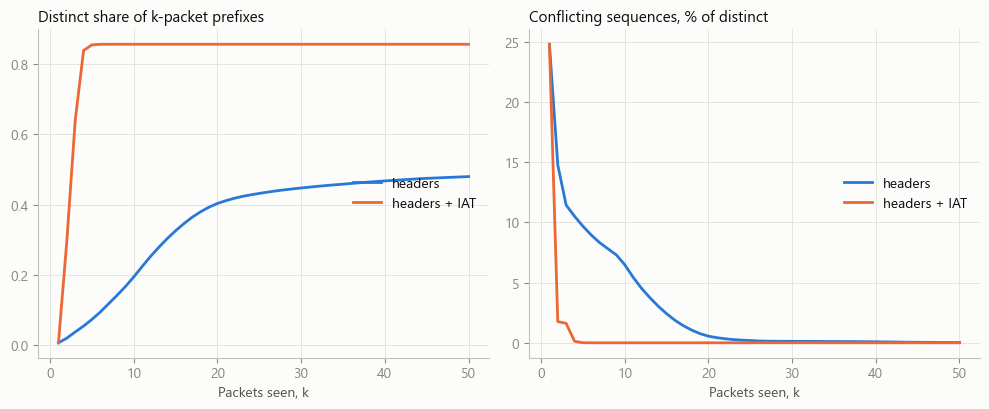

In [3]:
import matplotlib.pyplot as plt

FIG_DIR = DATA_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
# Reference palette (dataviz skill): series in fixed order, recessive chrome
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
})

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for key, color in [("headers", BLUE), ("headers + IAT", ORANGE)]:
    g = report.loc[key]
    axes[0].plot(g.index, g["distinct share"], color=color, label=key)
    axes[1].plot(g.index, g["conflicting share of distinct"] * 100, color=color, label=key)
axes[0].set_title("Distinct share of k-packet prefixes", loc="left", fontsize=11)
axes[1].set_title("Conflicting sequences, % of distinct", loc="left", fontsize=11)
for ax in axes:
    ax.set_xlabel("Packets seen, k")
    ax.legend(loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "data_diagnostics.png", dpi=150)
plt.show()

In [4]:
# Every conflicting whole segment for manual review, most lopsided first (a 10-to-1 split hints at a mislabel;
# a balanced one at genuine ambiguity). The ratio only orders the list, it decides nothing.
in_dist = segments[known].copy()
in_dist["capture_order"] = in_dist["capture"].map({c: i for i, c in enumerate(CAPTURES)})
in_dist = in_dist.sort_values(["capture_order", "start"], kind="stable")
copies = in_dist.groupby("hash").agg(copies=("segment", "size"), captures=("capture", "nunique"),
                                     benign=("attack", lambda a: int((a == 0).sum())), attack=("attack", "sum"),
                                     length=("length", "first"))
review = copies[(copies["benign"] > 0) & (copies["attack"] > 0)]
review = review.assign(minority_share=review[["benign", "attack"]].min(axis=1) / review["copies"]).sort_values("minority_share")
review.to_csv(RESULT_DIR / "conflicts_for_review.csv")
print(f"{len(review):,} conflicting sequences ({int(review['copies'].sum()):,} segments) written for review")
review.head(10)

49 conflicting sequences (2,657 segments) written for review


,copies,captures,benign,attack,length,minority_share
hash,,,,,,
11667848766037174900,441,2,436,5,50,0.011338
86904020342891221,51,2,50,1,50,0.019608
18136889866780085365,44,2,43,1,50,0.022727
18424441164791658140,39,2,38,1,50,0.025641
2567465741470322395,30,2,29,1,50,0.033333
7856757415908046846,57,2,55,2,50,0.035088
3296971798656163495,25,2,24,1,50,0.040000
4817024456266224321,24,1,23,1,50,0.041667
18068687793616464317,29,2,27,2,50,0.068966


### Tracks

Built from the known captures in time order. Each track keeps its own size: nothing is sampled to match the other.
The split is by time within each capture and class.

In [5]:
conflict_hashes = review.index
in_conflict = in_dist["hash"].isin(conflict_hashes)
tracks = {"A": in_dist, "B": in_dist[~in_conflict]}


def time_split(g):
    rank = (np.arange(len(g)) + 0.5) / len(g)
    return pd.Series(np.select([rank < 0.6, rank < 0.8], ["train", "val"], "test"), index=g.index)


summary = []
for name, t in tracks.items():
    t = t.sort_values(["capture_order", "attack", "start"], kind="stable").copy()
    t["split"] = pd.concat([time_split(g) for _, g in t.groupby(["capture", "attack"], sort=False)])
    for _, g in t.groupby(["capture", "attack"]):  # time order holds inside each capture and class
        s = g.groupby("split")["start"]
        assert s.max()["train"] <= s.min()["val"] and s.max()["val"] <= s.min()["test"]
    t[["segment", "capture", "flow", "attack", "length", "start", "hash", "split"]].to_parquet(TRACK_DIR / f"{name}.parquet", index=False)
    tracks[name] = t
    train_h = set(t.loc[t["split"] == "train", "hash"])
    for part in ["train", "val", "test"]:
        d = t[t["split"] == part]
        summary.append({"track": name, "split": part, "segments": len(d), "attack share": d["attack"].mean(),
                        "unseen rows": int((~d["hash"].isin(train_h)).sum()) if part != "train" else np.nan})
assert not tracks["B"]["hash"].isin(conflict_hashes).any()
summary = pd.DataFrame(summary).set_index(["track", "split"])
summary.to_csv(RESULT_DIR / "track_sizes.csv")
summary

segments  attack share  unseen rows
track split                                     
A     train    274862      0.364954          NaN
      val       91621      0.364938      54121.0
      test      91621      0.364949      54312.0
B     train    273269      0.366518          NaN
      val       91089      0.366521      54098.0
      test      91089      0.366521      54121.0

In [6]:
# Held out of every track: attack segments of Mirai (another network) and ARP MitM (same network) whose sequence never
# occurs in the known captures, plus all held-out segments for the before/after views of Mirai's time-based labels
held = segments[~known].copy()
held["group"] = np.where(held["capture"] == "Mirai", "Mirai",
                         np.where(held["arp_share"] > 0.5, "ARP MitM (ARP)", "ARP MitM (relayed)"))
held["new sequence"] = ~held["hash"].isin(in_dist["hash"])
held[["segment", "capture", "flow", "attack", "length", "start", "hash", "group", "new sequence"]].to_parquet(TRACK_DIR / "held_out.parquet", index=False)
held.groupby(["group", "attack"]).agg(segments=("segment", "size"), new=("new sequence", "sum"))

segments    new
group              attack                 
ARP MitM (ARP)     0             40      5
ARP MitM (relayed) 0          26018  25948
                   1          24131  24036
Mirai              0          21396  11689
                   1          25375   8468

## Stage 2: models (per track)

The track comes from the `TRACK` environment variable (A or B). Everything here uses only that track's data, and
every choice is made on its validation split, never on test.

1. **GRU size** (64, 128, 128x2) on all feature groups, by validation loss. The chosen size model is the **main model**.
2. **Model without TTL, destination port and IAT**: the same size on every other feature group. These inputs can
   identify this testbed rather than the attack (TTL: the sender's operating system and hop count; destination port:
   the attacked service; IAT: this network's link speed, load and capture host), so comparing the two models shows how
   much of the performance depends on them.

Losses are shown on all validation rows and on the unseen ones (sequence not in training).

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os

from pathlib import Path

import numpy as np
import pandas as pd

import kitsune_lib
from kitsune_lib import (GROUPS, GRU_GRID, RESULT_DIR, SEED, TESTBED_GROUPS, eval_loss, fit_gru,
                         group_columns, load, load_data, read_track, save_json, split_index, fit_stats, unseen)

TRACK = os.environ.get("TRACK", "A")
SEEDS = [SEED]  # more seeds left for future work

X, segments, y_all, lengths, prefix_header, _ = load_data()
part = split_index(read_track(TRACK))
if os.environ.get("QUICK"):  # smoke test: tiny subsample, one epoch, scratch folders
    part = {k: v[::max(1, len(v) // 2000)] for k, v in part.items()}
    kitsune_lib.MAX_EPOCHS = 1
    kitsune_lib.MODEL_DIR = RESULT_DIR = Path(os.environ["QUICK"])
stats = fit_stats(X, part["train"])
x_train_all = load(X, part["train"], stats)
x_val_all = load(X, part["val"], stats)
y_train = y_all[part["train"]].astype(np.float32)
y_val = y_all[part["val"]].astype(np.float32)
val_unseen = unseen(part["val"], part["train"], segments["hash"].to_numpy())
weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Track {TRACK}: train {len(y_train):,}, validation {len(y_val):,} ({val_unseen.mean():.1%} unseen)")


def train(name, groups, arch, seed=SEED):
    cols = group_columns(groups)
    model, loss_all = fit_gru(f"{TRACK}_{name}", x_train_all[:, :, cols], y_train, x_val_all[:, :, cols], y_val,
                              *GRU_GRID[arch], seed=seed)
    loss_unseen = eval_loss(model, x_val_all[val_unseen][:, :, cols], y_val[val_unseen], weight, len(cols) - 1)
    return {"model": f"{TRACK}_{name}", "validation loss, all": loss_all, "validation loss, unseen": loss_unseen}

Track A: train 274,862, validation 91,621 (59.1% unseen)


#### 1. GRU size

In [2]:
ALL = list(GROUPS)
size_rows = {arch: train(f"size_{arch}", ALL, arch) for arch in GRU_GRID}
sizes = pd.DataFrame(size_rows).T
arch = sizes["validation loss, all"].astype(float).idxmin()
sizes.to_csv(RESULT_DIR / f"{TRACK}_gru_size.csv")
print(f"chosen size: {arch}")
sizes

chosen size: 128x2


,model,"validation loss, all","validation loss, unseen"
64,A_size_64,0.094174,0.151446
128,A_size_128,0.097486,0.157802
128x2,A_size_128x2,0.07808,0.127624


#### 2. Main model and model without TTL, destination port and IAT

In [3]:
final = {"main": ALL, "without TTL, destination port and IAT":[g for g in ALL if g not in TESTBED_GROUPS]}
finals = []
for role, groups in final.items():
    tag = "all" if role == "main" else "no_testbed"
    for seed in SEEDS:
        if role == "main" and seed == SEED:
            r = {**size_rows[arch]}  # the chosen size model is the main model
        else:
            r = train(f"{arch}_{tag}" if seed == SEED else f"{arch}_{tag}_seed{seed}", groups, arch, seed)
        finals.append({"role": role, "seed": seed, "groups": ", ".join(groups), **r})
finals = pd.DataFrame(finals)
finals.to_csv(RESULT_DIR / f"{TRACK}_final_models.csv", index=False)
save_json({"track": TRACK, "arch": arch, "final": final,
           "models": {role: finals.loc[finals["role"] == role, "model"].tolist() for role in final}},
          RESULT_DIR / f"{TRACK}_selection.json")
finals

A_128x2_no_testbed: epoch 1, validation loss 0.1901, 244s


A_128x2_no_testbed: epoch 2, validation loss 0.1760, 488s


A_128x2_no_testbed: epoch 3, validation loss 0.1560, 755s


A_128x2_no_testbed: epoch 4, validation loss 0.1479, 993s


A_128x2_no_testbed: epoch 5, validation loss 0.1494, 1230s


A_128x2_no_testbed: epoch 6, validation loss 0.1442, 1493s


A_128x2_no_testbed: epoch 7, validation loss 0.1414, 1782s


A_128x2_no_testbed: epoch 8, validation loss 0.1404, 2066s


A_128x2_no_testbed: epoch 9, validation loss 0.1399, 2312s


A_128x2_no_testbed: epoch 10, validation loss 0.1378, 2560s


,role,seed,groups,model,"validation loss, all","validation loss, unseen"
0,main,0,"sizes, header lengths, TCP flags, TCP window, ...",A_size_128x2,0.078080,0.127624
1,"without TTL, destination port and IAT",0,"sizes, header lengths, TCP flags, TCP window, ...",A_128x2_no_testbed,0.137837,0.217138


### Track B

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "B"  # the stage reads its track from here

In [1]:
import os

from pathlib import Path

import numpy as np
import pandas as pd

import kitsune_lib
from kitsune_lib import (GROUPS, GRU_GRID, RESULT_DIR, SEED, TESTBED_GROUPS, eval_loss, fit_gru,
                         group_columns, load, load_data, read_track, save_json, split_index, fit_stats, unseen)

TRACK = os.environ.get("TRACK", "A")
SEEDS = [SEED]  # more seeds left for future work

X, segments, y_all, lengths, prefix_header, _ = load_data()
part = split_index(read_track(TRACK))
if os.environ.get("QUICK"):  # smoke test: tiny subsample, one epoch, scratch folders
    part = {k: v[::max(1, len(v) // 2000)] for k, v in part.items()}
    kitsune_lib.MAX_EPOCHS = 1
    kitsune_lib.MODEL_DIR = RESULT_DIR = Path(os.environ["QUICK"])
stats = fit_stats(X, part["train"])
x_train_all = load(X, part["train"], stats)
x_val_all = load(X, part["val"], stats)
y_train = y_all[part["train"]].astype(np.float32)
y_val = y_all[part["val"]].astype(np.float32)
val_unseen = unseen(part["val"], part["train"], segments["hash"].to_numpy())
weight = float((y_train == 0).sum() / (y_train == 1).sum())
print(f"Track {TRACK}: train {len(y_train):,}, validation {len(y_val):,} ({val_unseen.mean():.1%} unseen)")


def train(name, groups, arch, seed=SEED):
    cols = group_columns(groups)
    model, loss_all = fit_gru(f"{TRACK}_{name}", x_train_all[:, :, cols], y_train, x_val_all[:, :, cols], y_val,
                              *GRU_GRID[arch], seed=seed)
    loss_unseen = eval_loss(model, x_val_all[val_unseen][:, :, cols], y_val[val_unseen], weight, len(cols) - 1)
    return {"model": f"{TRACK}_{name}", "validation loss, all": loss_all, "validation loss, unseen": loss_unseen}

Track B: train 273,269, validation 91,089 (59.4% unseen)


#### 1. GRU size

In [2]:
ALL = list(GROUPS)
size_rows = {arch: train(f"size_{arch}", ALL, arch) for arch in GRU_GRID}
sizes = pd.DataFrame(size_rows).T
arch = sizes["validation loss, all"].astype(float).idxmin()
sizes.to_csv(RESULT_DIR / f"{TRACK}_gru_size.csv")
print(f"chosen size: {arch}")
sizes

B_size_64: epoch 1, validation loss 0.1630, 37s


B_size_64: epoch 2, validation loss 0.1438, 72s


B_size_64: epoch 3, validation loss 0.1127, 108s


B_size_64: epoch 4, validation loss 0.1068, 143s


B_size_64: epoch 5, validation loss 0.1078, 179s


B_size_64: epoch 6, validation loss 0.1002, 214s


... (20 outputs left out)

B_size_128x2: epoch 9, validation loss 0.0936, 1934s


B_size_128x2: epoch 10, validation loss 0.0759, 2151s


chosen size: 128x2


,model,"validation loss, all","validation loss, unseen"
64,B_size_64,0.096358,0.154714
128,B_size_128,0.090185,0.147064
128x2,B_size_128x2,0.075864,0.124516


#### 2. Main model and model without TTL, destination port and IAT

In [3]:
final = {"main": ALL, "without TTL, destination port and IAT":[g for g in ALL if g not in TESTBED_GROUPS]}
finals = []
for role, groups in final.items():
    tag = "all" if role == "main" else "no_testbed"
    for seed in SEEDS:
        if role == "main" and seed == SEED:
            r = {**size_rows[arch]}  # the chosen size model is the main model
        else:
            r = train(f"{arch}_{tag}" if seed == SEED else f"{arch}_{tag}_seed{seed}", groups, arch, seed)
        finals.append({"role": role, "seed": seed, "groups": ", ".join(groups), **r})
finals = pd.DataFrame(finals)
finals.to_csv(RESULT_DIR / f"{TRACK}_final_models.csv", index=False)
save_json({"track": TRACK, "arch": arch, "final": final,
           "models": {role: finals.loc[finals["role"] == role, "model"].tolist() for role in final}},
          RESULT_DIR / f"{TRACK}_selection.json")
finals

B_128x2_no_testbed: epoch 1, validation loss 0.1893, 215s


B_128x2_no_testbed: epoch 2, validation loss 0.1742, 434s


B_128x2_no_testbed: epoch 3, validation loss 0.1762, 654s


B_128x2_no_testbed: epoch 4, validation loss 0.1479, 870s


B_128x2_no_testbed: epoch 5, validation loss 0.1447, 1089s


B_128x2_no_testbed: epoch 6, validation loss 0.1478, 1307s


B_128x2_no_testbed: epoch 7, validation loss 0.1548, 1526s


,role,seed,groups,model,"validation loss, all","validation loss, unseen"
0,main,0,"sizes, header lengths, TCP flags, TCP window, ...",B_size_128x2,0.075864,0.124516
1,"without TTL, destination port and IAT",0,"sizes, header lengths, TCP flags, TCP window, ...",B_128x2_no_testbed,0.144703,0.226849


## Stage 3: evaluation (per track)

The track comes from `TRACK`. Each final model from stage 2 becomes one **deployable unit**, built only from this track's
data: input statistics (training), temperatures (first validation half), two OOD detectors on training hidden states
(an Isolation Forest, and the Mahalanobis distance to the nearer class mean with a shared covariance), OOD limits and
the High/Low cut-offs (second validation half). Test and the held-out captures are used only to measure.

**Decision rule**, per segment, packet by packet up to K (K = L = 50 is the working cut-off; shorter K are reported):
OOD if the running mean of either detector's score is over its limit (forest OR Mahalanobis); High (block) if
P(attack) >= tau_attack; Low (benign, this segment only) at the segment's end if P(attack) <= tau_benign; otherwise
Medium ("I don't know").

**Thresholds** are per-track precision targets on the second validation half: tau_attack is the lowest cut-off with at
least 99% of blocks real attacks, tau_benign the highest with at least 99.9% of Low answers really benign. The two OOD
limits sit at the same quantile of their detector's known validation scores, the lowest at which at most 5% of known
validation segments are ever flagged by either detector.

**Views**: "all" is the split as it is; "unseen" is "all" with every row whose sequence appears in this track's training
split removed. Ceilings (MaxAcc: Jerabek et al. Eq. 1; minimum FPR: their lower bound) are computed on
exactly the rows each result is measured on.

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

import kitsune_lib as kl
from kitsune_lib import (BUCKETS, CAPTURES, GRU_GRID, K_REPORT, L, SEED, STEP_BUCKET, at_prefix, at_rate, ceiling,
                         fit_gru, fit_stats, fit_temperatures, flow_bootstrap, group_columns, known_metrics, load,
                         load_data, load_json, ood_thresholds, p_attack, predict, read_track, real_steps, route,
                         running_mean, scores, split_index, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:  # smoke test against the stage-2 smoke-test models
    kl.MODEL_DIR = OUT = Path(QUICK)
HIDDEN_TRAIN, FOREST_STEPS = 30_000, 200_000
DEPLOY_RATE = 0.01  # attack share assumed for the "real network" precision line

X, segments, y_all, lengths, prefix_header, prefix_timed = load_data()
track = read_track(TRACK).set_index("segment", drop=False)
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
if QUICK:
    part = {k: v[::max(1, len(v) // 3000)] for k, v in part.items()}
    held = held.iloc[::max(1, len(held) // 3000)]
seg_hash = segments["hash"].to_numpy()
train_hashes = seg_hash[part["train"]]
selection = load_json(OUT / f"{TRACK}_selection.json")
arch = selection["arch"]
print(f"Track {TRACK}: size {arch}, main groups: {selection['final']['main']}")

# The two validation halves, stratified by capture and class
from sklearn.model_selection import train_test_split
v = track.loc[part["val"]]
strata = (v["capture"] + v["attack"].astype(str)).to_numpy()
counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
strata = np.where(counts < 2, v["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
cal_idx, thr_idx = train_test_split(part["val"], test_size=0.5, random_state=SEED,
                                    stratify=strata if pd.Series(strata).value_counts().min() >= 2 else None)
parts = {"train sample": np.sort(np.random.default_rng(SEED).choice(part["train"], min(HIDDEN_TRAIN, len(part["train"])), replace=False)),
         "cal": np.sort(cal_idx), "thr": np.sort(thr_idx), "val": part["val"], "test": part["test"], "held": held.index.to_numpy()}
unseen_of = {p: ~np.isin(seg_hash[i], train_hashes) for p, i in parts.items()}
print({p: f"{len(i):,} ({unseen_of[p].mean():.0%} unseen)" for p, i in parts.items()})

Track A: size 128x2, main groups: ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']
{'train sample': '30,000 (0% unseen)', 'cal': '45,810 (59% unseen)', 'thr': '45,811 (59% unseen)', 'val': '91,621 (59% unseen)', 'test': '91,621 (59% unseen)', 'held': '96,960 (72% unseen)'}


#### Deployable units

`build_unit` builds everything a deployment of one model needs and saves it. The main model uses all feature
groups; the model without TTL, destination port and IAT is built the same way.

In [2]:
stats = fit_stats(X, part["train"])


def unit_for(model_name, groups):
    cols = group_columns(groups)
    model, _ = fit_gru(model_name, np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32), None, None, *GRU_GRID[arch])
    u = kl.build_unit(X, model, cols, stats, parts, lengths, y_all, forest_steps=FOREST_STEPS)
    u.update(model=model_name, groups=groups)
    joblib.dump({k: u[k] for k in ["model", "groups", "columns", "stats", "temperatures", "fitted temperatures", "detectors", "thresholds"]},
                kl.MODEL_DIR / f"{model_name}_unit.joblib")
    return u


units = {}
for role, names in selection["models"].items():
    for name in names:
        t0 = time.time()
        units[name] = unit_for(name, selection["final"][role])
        print(f"{name}: unit built in {time.time() - t0:.0f}s")
main = units[selection["models"]["main"][0]]
thresholds = pd.DataFrame({(name, K): {k: v for k, v in t.items() if k != "ood limits"} for name, u in units.items()
                           for K, t in u["thresholds"].items()}).T
thresholds.index.names = ["model", "K"]
thresholds.to_csv(OUT / f"{TRACK}_thresholds.csv")
thresholds.xs(L, level="K")

A_size_128x2: unit built in 257s


A_128x2_no_testbed: unit built in 244s


,ood quantile,tau_attack,tau_benign,high target met,low target met,blocks,block precision,"block precision, lower 95%",Low answers,Low precision,"Low precision, lower 95%"
model,,,,,,,,,,,
A_size_128x2,0.993491,0.932021,0.005915,True,True,14882,0.990324,0.988897,20496,0.999122,0.998698
A_128x2_no_testbed,0.987841,0.985627,0.01606,True,True,14534,0.990023,0.988558,18823,0.999044,0.998582


#### Known traffic: pipeline results, "I know" performance, all and unseen

In [3]:
def decide(u, p, K):
    t = u["tuned"][K]
    return route(u["prob"][p], t["flags"][p], u["n"][p], t["tau_attack"], t["tau_benign"], K)


rows = []
for name, u in units.items():
    for p in ("val", "test"):
        for K in K_REPORT:
            out, packets = decide(u, p, K)
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_of[p])]:
                r = known_metrics(out[m], u["y"][p][m], packets[m])
                r["block precision at 1% attacks"] = at_rate(r["attacks blocked"], r["benign blocked"], DEPLOY_RATE)
                rows.append({"model": name, "split": p, "K": K, "view": view, **r})
pipeline = pd.DataFrame(rows).set_index(["model", "split", "K", "view"])
pipeline.to_csv(OUT / f"{TRACK}_pipeline.csv")
shown = ["segments", "coverage", "attacks blocked", "block precision", "block precision at 1% attacks", "attacks called benign",
         "benign blocked", "benign called Low", "Low precision", "accuracy when answering", "macro F1 when answering",
         "Medium", "OOD", "mean packets to block"]
pipeline.loc[(main["model"], ["val", "test"], L), shown].round(4)

segments  coverage  attacks blocked  \
model        split K  view                                          
A_size_128x2 val   50 all        91621    0.7714           0.8820   
                      unseen     54121    0.6512           0.5833   
             test  50 all        91621    0.7997           0.8448   
                      unseen     54312    0.6898           0.3898   

                              block precision  block precision at 1% attacks  \
model        split K  view                                                     
A_size_128x2 val   50 all              0.9906                         0.6501   
                      unseen           0.9444                         0.5485   
             test  50 all              0.9804                         0.4677   
                      unseen           0.8469                         0.2679   

                              attacks called benign  benign blocked  \
model        split K  view                                            
A_size_128x2 val   50 all                    0.0010          0.0048   
                      unseen                 0.0048          0.0048   
             test  50 all                    0.0062          0.0097   
                      unseen                 0.0288          0.0108   

                              benign called Low  Low precision  \
model        split K  view                                       
A_size_128x2 val   50 all                0.7025         0.9992   
                      unseen             0.6553         0.9990   
             test  50 all                0.7605         0.9953   
                      unseen             0.7204         0.9939   

                              accuracy when answering  \
model        split K  view                              
A_size_128x2 val   50 all                      0.9956   
                      unseen                   0.9926   
             test  50 all                      0.9895   
                      unseen                   0.9809   

                              macro F1 when answering  Medium     OOD  \
model        split K  view                                              
A_size_128x2 val   50 all                      0.9955  0.2112  0.0174   
                      unseen                   0.9817  0.3328  0.0159   
             test  50 all                      0.9889  0.1854  0.0149   
                      unseen                   0.9383  0.3000  0.0103   

                              mean packets to block  
model        split K  view                           
A_size_128x2 val   50 all                    1.4395  
                      unseen                 4.1952  
             test  50 all                    1.2848  
                      unseen                 3.7375

In [4]:
# 95% intervals on test, resampling whole flows (segments of one flow are not independent)
flow_key = (track.loc[parts["test"], "capture"] + "/" + track.loc[parts["test"], "flow"].astype(str)).to_numpy()
out, _ = decide(main, "test", L)
cis = {view: flow_bootstrap(out[m], main["y"]["test"][m], flow_key[m]) for view, m in
       [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]}
pd.DataFrame(cis).to_csv(OUT / f"{TRACK}_bootstrap.csv")
pd.DataFrame(cis)

,all,unseen
"attacks blocked, 95% CI","(0.7679710591042087, 0.9327994227562896)","(0.12114883296258552, 0.723374297276971)"
"block precision, 95% CI","(0.9619968486268983, 0.9940834998025411)","(0.5448053231670726, 0.9572877651073838)"
"Low precision, 95% CI","(0.9850114024130447, 0.9999252609005991)","(0.9783351425105659, 0.9999681018618383)"
"coverage, 95% CI","(0.7017079951332937, 0.8709603262361871)","(0.558598073848063, 0.8132025442176195)"


#### Per attack type, with the average across types

In [5]:
capture_of = track.loc[parts["test"], "capture"].to_numpy()
start_of = track.loc[parts["test"], "start"].to_numpy()
out, packets = decide(main, "test", L)
rows = []
for view, vm in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]:
    for capture in CAPTURES:
        m = vm & (capture_of == capture)
        if not m.any():
            continue
        r = known_metrics(out[m], main["y"]["test"][m], packets[m])
        hours = max((start_of[capture_of == capture].max() - start_of[capture_of == capture].min()) / 3600, 1e-9)
        y_m, o_m = main["y"]["test"][m], out[m]
        r.update({"test hours": hours, "false blocks per hour": ((o_m == "High") & (y_m == 0)).sum() / hours,
                  "Medium per hour": (o_m == "Medium").sum() / hours,
                  "attacks passed per hour": ((o_m != "High") & (y_m == 1)).sum() / hours})
        rows.append({"view": view, "attack type": capture, **r})
per_type = pd.DataFrame(rows).set_index(["view", "attack type"])
for view in ["all", "unseen"]:  # every attack type weighs the same in the average
    per_type.loc[(view, "average across types"), :] = per_type.loc[view].mean(numeric_only=True)
per_type.to_csv(OUT / f"{TRACK}_per_attack_type.csv")
per_type[["attack segments", "attacks blocked", "attacks called benign", "Medium", "block precision", "Low precision",
          "false blocks per hour", "attacks passed per hour"]].round(4)

attack segments  attacks blocked  \
view   attack type                                              
all    OS Scan                    13117.0000           0.9430   
       Fuzzing                     2083.0000           0.0048   
       Video Injection              412.0000           0.3641   
       Active Wiretap              3922.0000           0.4709   
       SSDP Flood                 13108.0000           1.0000   
       SYN DoS                      128.0000           0.8047   
       SSL Renegotiation            667.0000           0.9895   
unseen OS Scan                       15.0000           0.0000   
       Fuzzing                     2053.0000           0.0049   
       Video Injection              385.0000           0.3610   
       Active Wiretap              3922.0000           0.4709   
       SSDP Flood                   121.0000           1.0000   
       SYN DoS                       47.0000           0.9149   
       SSL Renegotiation            651.0000           0.9892   
all    average across types        4776.7143           0.6539   
unseen average across types        1027.7143           0.5344   

                             attacks called benign  Medium  block precision  \
view   attack type                                                            
all    OS Scan                              0.0000  0.0008           1.0000   
       Fuzzing                              0.0000  0.2278           0.4545   
       Video Injection                      0.0243  0.4319           0.2577   
       Active Wiretap                       0.0502  0.6803           0.9731   
       SSDP Flood                           0.0000  0.0093           0.9977   
       SYN DoS                              0.0000  0.2683           0.7305   
       SSL Renegotiation                    0.0000  0.1257           0.9970   
unseen OS Scan                              0.0000  0.0014              NaN   
       Fuzzing                              0.0000  0.2259           0.4545   
       Video Injection                      0.0260  0.4256           0.2443   
       Active Wiretap                       0.0502  0.6817           0.9742   
       SSDP Flood                           0.0000  0.0069           0.9167   
       SYN DoS                              0.0000  0.3652           0.9348   
       SSL Renegotiation                    0.0000  0.2052           0.9969   
all    average across types                 0.0106  0.2492           0.7729   
unseen average across types                 0.0109  0.2731           0.7536   

                             Low precision  false blocks per hour  \
view   attack type                                                  
all    OS Scan                      1.0000                 0.0000   
       Fuzzing                      1.0000                83.8508   
       Video Injection              0.9980              3065.8150   
       Active Wiretap               0.7006               230.0163   
       SSDP Flood                   1.0000               178.4804   
       SYN DoS                      1.0000               213.5656   
       SSL Renegotiation            1.0000                11.9861   
unseen OS Scan                      1.0000                 0.0000   
       Fuzzing                      1.0000                83.8508   
       Video Injection              0.9980              3051.6215   
       Active Wiretap               0.7006               220.9961   
       SSDP Flood                   1.0000                65.4428   
       SYN DoS                      1.0000                16.8604   
       SSL Renegotiation            1.0000                11.9861   
all    average across types         0.9569               540.5306   
unseen average across types         0.9569               492.9654   

                             attacks passed per hour  
view   attack type                                    
all    OS Scan                             4301.7268  
       Fuzzing             

In [6]:
# Drift: four time slices of each capture's test period
rank = pd.Series(start_of).groupby(capture_of).rank(pct=True).to_numpy()
slice_of = np.minimum((rank * 4).astype(int), 3) + 1
drift = pd.DataFrame([{"slice": s, **known_metrics(out[slice_of == s], main["y"]["test"][slice_of == s])} for s in range(1, 5)]).set_index("slice")
drift.to_csv(OUT / f"{TRACK}_drift.csv")
drift[["segments", "coverage", "attacks blocked", "block precision", "Low precision", "Medium", "OOD"]].round(4)

,segments,coverage,attacks blocked,block precision,Low precision,Medium,OOD
slice,,,,,,,
1,22900,0.7831,0.9401,0.9688,1.0000,0.2023,0.0145
2,22905,0.7893,0.9604,0.9489,1.0000,0.1935,0.0172
3,22905,0.7931,0.8390,0.9913,0.9870,0.1881,0.0188
4,22911,0.8332,0.7529,0.9948,0.9894,0.1576,0.0092


#### Time to a decision

How much traffic time passes before an answer: the seconds between a segment's first packet and the packet its answer
came at (from the packets' inter-arrival times), for each decision packet K. "Blocks" are High answers on attack
segments; "any answer" covers every segment. Compute time is separate (deployment cost below).

In [7]:
iat_s = np.expm1(np.array(X[parts["test"], :, kl.COL["iat"]], dtype=np.float64)) / 1e6  # seconds since the flow's previous packet
iat_s[:, 0] = 0  # counted from the segment's first packet
elapsed = np.cumsum(iat_s, axis=1)
rows = []
for name, u in units.items():
    y = u["y"]["test"]
    for K in K_REPORT:
        out, packets = decide(u, "test", K)
        t = elapsed[np.arange(len(out)), packets - 1]
        for answers, m in [("blocks", (out == "High") & (y == 1)), ("any answer", np.ones(len(out), bool))]:
            rows.append({"model": name, "K": K, "answers": answers, "segments": int(m.sum()),
                         "packets, mean": packets[m].mean() if m.any() else np.nan,
                         "seconds, median": np.median(t[m]) if m.any() else np.nan,
                         "seconds, 90th percentile": np.quantile(t[m], 0.9) if m.any() else np.nan})
decision_time = pd.DataFrame(rows).set_index(["model", "K", "answers"])
decision_time.to_csv(OUT / f"{TRACK}_decision_time.csv")
decision_time.round(4)

segments  packets, mean  seconds, median  \
model              K  answers                                                
A_size_128x2       1  blocks         23925         1.0000           0.0000   
                      any answer     91621         1.0000           0.0000   
                   3  blocks         27248         1.0247           0.0000   
                      any answer     91621         2.3769           0.0003   
                   5  blocks         27658         1.0730           0.0000   
                      any answer     91621         3.7359           0.0006   
                   10 blocks         27963         1.0987           0.0000   
                      any answer     91621         7.1307           0.0061   
                   20 blocks         27983         1.1467           0.0000   
                      any answer     91621        13.8865           0.0663   
                   50 blocks         28247         1.2848           0.0000   
                      any answer     91621        34.0395           0.1957   
A_128x2_no_testbed 1  blocks         13103         1.0000           0.0000   
                      any answer     91621         1.0000           0.0000   
                   3  blocks         27733         2.0001           0.0001   
                      any answer     91621         2.6366           0.0004   
                   5  blocks         27752         2.0001           0.0001   
                      any answer     91621         3.9618           0.0009   
                   10 blocks         27994         2.0376           0.0001   
                      any answer     91621         7.3154           0.0638   
                   20 blocks         28196         2.0935           0.0002   
                      any answer     91621        13.9365           0.0966   
                   50 blocks         28284         2.1800           0.0002   
                      any answer     91621        33.9345           0.2657   

                                  seconds, 90th percentile  
model              K  answers                               
A_size_128x2       1  blocks                        0.0000  
                      any answer                    0.0000  
                   3  blocks                        0.0000  
                      any answer                    0.0595  
                   5  blocks                        0.0000  
                      any answer                    0.0659  
                   10 blocks                        0.0000  
                      any answer                    0.0711  
                   20 blocks                        0.0000  
                      any answer                    0.1951  
                   50 blocks                        0.0000  
                      any answer                    0.4049  
A_128x2_no_testbed 1  blocks                        0.0000  
                      any answer                    0.0000  
                   3  blocks                        7.5041  
                      any answer                    2.8691  
                   5  blocks                        7.5030  
                      any answer                    2.8981  
                   10 blocks                        7.4637  
                      any answer                    2.9017  
                   20 blocks                        7.4355  
                      any answer                    2.9060  
                   50 blocks                        7.4288  
                      any answer                    2.9175

#### Forced answers and ceilings on the same rows

A ceiling bounds a model only when identical rows are identical *in what the model reads*. The "headers" key is exactly
the input of the model without TTL, destination port and IAT, so its ceilings are upper bounds for that model. No key
holds TTL and destination port, so for the main model (and the baselines, which read its inputs) the ceilings are
reference values only: a model that reads more fields can separate rows the key treats as identical and score above them.

In [8]:
PREFIXES = [1, 2, 3, 5, 10, 20, 50]
rows = []
for name, u in units.items():
    for p in ("val", "test"):
        idx = parts[p]
        for view, m in [("all", np.ones(len(idx), bool)), ("unseen", unseen_of[p])]:
            for k in PREFIXES:
                pred = (at_prefix(u["prob"][p], u["n"][p], k)[m] >= 0.5).astype(int)
                r = {"model": name, "split": p, "view": view, "k": k, **scores(u["y"][p][m], pred)}
                for key, H in [("headers + IAT", prefix_timed), ("headers", prefix_header)]:
                    c = ceiling(H[idx[m], k - 1], u["y"][p][m])
                    r.update({f"{cname}, {key}": value for cname, value in c.items() if cname != "rows"})
                r["rows"] = int(m.sum())
                rows.append(r)
forced = pd.DataFrame(rows).set_index(["model", "split", "view", "k"])
forced.to_csv(OUT / f"{TRACK}_forced_and_ceilings.csv")
no_testbed = selection["models"]["without TTL, destination port and IAT"][0]
# The model without the testbed group, against its exact ceilings (key "headers")
forced.loc[(no_testbed, "test"), ["rows", "accuracy", "MaxAcc, headers", "macro F1", "MaxF1, headers", "FPR",
                                  "minimum FPR, headers", "missed attacks", "minimum missed attacks, headers"]].round(4)

C:\Users\joe22\AppData\Local\Temp\ipykernel_33784\2112947015.py:19: PerformanceWarning: indexing past lexsort depth may impact performance.
  forced.loc[(no_testbed, "test"), ["rows", "accuracy", "MaxAcc, headers", "macro F1", "MaxF1, headers", "FPR",


rows  accuracy  MaxAcc, headers  macro F1  MaxF1, headers     FPR  \
view   k                                                                        
all    1   91621    0.9050           0.9464    0.8969          0.9403  0.0672   
       2   91621    0.9392           0.9498    0.9328          0.9442  0.0181   
       3   91621    0.9428           0.9533    0.9368          0.9482  0.0144   
       5   91621    0.9445           0.9598    0.9386          0.9558  0.0122   
       10  91621    0.9475           0.9762    0.9417          0.9742  0.0065   
       20  91621    0.9483           0.9943    0.9425          0.9939  0.0039   
       50  91621    0.9488           0.9997    0.9430          0.9997  0.0026   
unseen 1   54312    0.8439           0.9107    0.6379          0.7263  0.0789   
       2   54312    0.9004           0.9160    0.7228          0.7523  0.0197   
       3   54312    0.9061           0.9219    0.7369          0.7787  0.0156   
       5   54312    0.9086           0.9329    0.7421          0.8240  0.0133   
       10  54312    0.9136           0.9607    0.7479          0.9094  0.0063   
       20  54312    0.9148           0.9913    0.7467          0.9805  0.0032   
       50  54312    0.9156           1.0000    0.7464          1.0000  0.0015   

           minimum FPR, headers  missed attacks  \
view   k                                          
all    1                 0.4014          0.1435   
       2                 0.3479          0.1350   
       3                 0.3161          0.1316   
       5                 0.2585          0.1308   
       10                0.1248          0.1326   
       20                0.0492          0.1349   
       50                0.0027          0.1357   
unseen 1                 0.4853          0.6618   
       2                 0.4206          0.6229   
       3                 0.3814          0.6069   
       5                 0.3103          0.6031   
       10                0.1456          0.6113   
       20                0.0523          0.6222   
       50                0.0000          0.6271   

           minimum missed attacks, headers  
view   k                                    
all    1                            0.1438  
       2                            0.1325  
       3                            0.1209  
       5                            0.0978  
       10                           0.0476  
       20                           0.0144  
       50                           0.0008  
unseen 1                            0.6610  
       2                            0.6109  
       3                            0.5563  
       5                            0.4483  
       10                           0.2143  
       20                           0.0601  
       50                           0.0000

In [9]:
# The main model, with the ceilings as reference values (the keys leave out TTL and destination port)
forced.loc[(main["model"], "test"), ["rows", "accuracy", "MaxAcc, headers + IAT", "macro F1", "MaxF1, headers + IAT", "FPR",
                                     "minimum FPR, headers + IAT", "missed attacks", "minimum missed attacks, headers + IAT"]].round(4)

C:\Users\joe22\AppData\Local\Temp\ipykernel_33784\151176323.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  forced.loc[(main["model"], "test"), ["rows", "accuracy", "MaxAcc, headers + IAT", "macro F1", "MaxF1, headers + IAT", "FPR",


rows  accuracy  MaxAcc, headers + IAT  macro F1  \
view   k                                                      
all    1   91621    0.9408                 0.9464    0.9338   
       2   91621    0.9526                 0.9616    0.9478   
       3   91621    0.9505                 0.9881    0.9455   
       5   91621    0.9498                 1.0000    0.9444   
       10  91621    0.9452                 1.0000    0.9394   
       20  91621    0.9449                 1.0000    0.9392   
       50  91621    0.9470                 1.0000    0.9414   
unseen 1   54312    0.9028                 0.9107    0.6898   
       2   54312    0.9227                 0.9358    0.7942   
       3   54312    0.9192                 0.9801    0.7825   
       5   54312    0.9177                 1.0000    0.7663   
       10  54312    0.9098                 1.0000    0.7484   
       20  54312    0.9094                 1.0000    0.7503   
       50  54312    0.9128                 1.0000    0.7557   

           MaxF1, headers + IAT     FPR  minimum FPR, headers + IAT  \
view   k                                                              
all    1                 0.9403  0.0029                      0.4014   
       2                 0.9578  0.0117                      0.2741   
       3                 0.9871  0.0123                      0.0329   
       5                 1.0000  0.0071                      0.0000   
       10                1.0000  0.0126                      0.0000   
       20                1.0000  0.0141                      0.0000   
       50                1.0000  0.0108                      0.0000   
unseen 1                 0.7263  0.0021                      0.4853   
       2                 0.8327  0.0127                      0.3319   
       3                 0.9569  0.0133                      0.0398   
       5                 1.0000  0.0072                      0.0000   
       10                1.0000  0.0140                      0.0000   
       20                1.0000  0.0159                      0.0000   
       50                1.0000  0.0118                      0.0000   

           missed attacks  minimum missed attacks, headers + IAT  
view   k                                                          
all    1           0.1572                                 0.1438  
       2           0.1096                                 0.0933  
       3           0.1142                                 0.0149  
       5           0.1253                                 0.0000  
       10          0.1283                                 0.0000  
       20          0.1263                                 0.0000  
       50          0.1265                                 0.0000  
unseen 1           0.7200                                 0.6610  
       2           0.5001                                 0.4309  
       3           0.5227                                 0.0677  
       5           0.5742                                 0.0000  
       10          0.5892                                 0.0000  
       20          0.5801                                 0.0000  
       50          0.5812                                 0.0000

#### Calibration on test

Temperature scaling divides the logit by one temperature per range of packets seen, fitted on the first validation half
and capped at T >= 1 so that calibration never makes the model more confident. Each model is scored with the
temperatures it uses (capped) and, for comparison, with the fitted ones (uncapped), at decision packets 1, 3, 10 and 50.
ECE: 15 equal-width bins of P(attack), the gap between mean P(attack) and the share of attacks in each bin, weighted by
the bin's size. The reliability bins at K = 50 are saved for the reliability diagram.

In [10]:
def calibration(p, y, bins=15):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    which = np.minimum((p * bins).astype(int), bins - 1)
    ece = sum(abs(p[which == b].mean() - y[which == b].mean()) * (which == b).mean() for b in range(bins) if (which == b).any())
    return {"ECE": ece, "Brier": np.mean((p - y) ** 2), "NLL": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))}


fitted_T = pd.DataFrame({name: dict(zip(BUCKETS, u["fitted temperatures"][[list(STEP_BUCKET).index(b) for b in range(len(BUCKETS))]]))
                         for name, u in units.items()}).T
print("fitted temperatures (before the cap), per range of packets seen:")
print(fitted_T.round(3))
rows, reliability = [], []
for name, u in units.items():
    for reading, T in [("capped (used)", u["temperatures"]), ("fitted, uncapped", u["fitted temperatures"])]:
        prob = p_attack(u["z"]["test"], T)
        for view, m in [("all", np.ones(len(u["y"]["test"]), bool)), ("unseen", unseen_of["test"])]:
            for k in [1, 3, 10, L]:
                p, y = at_prefix(prob, u["n"]["test"], k)[m], u["y"]["test"][m]
                rows.append({"model": name, "temperature": reading, "view": view, "k": k, **calibration(p, y)})
                if k == L and view == "all":
                    which = np.minimum((p * 15).astype(int), 14)
                    reliability += [{"model": name, "temperature": reading, "bin": b, "segments": int((which == b).sum()),
                                     "mean P(attack)": p[which == b].mean(), "attack share": y[which == b].mean()}
                                    for b in range(15) if (which == b).any()]
calib = pd.DataFrame(rows).set_index(["model", "temperature", "view", "k"])
calib.to_csv(OUT / f"{TRACK}_calibration.csv")
pd.DataFrame(reliability).to_csv(OUT / f"{TRACK}_reliability.csv", index=False)
calib.xs("all", level="view").round(4)

fitted temperatures (before the cap), per range of packets seen:
                        1    2-3   4-10    11+
A_size_128x2        0.823  0.690  0.826  0.941
A_128x2_no_testbed  0.892  0.856  0.777  0.772


ECE   Brier     NLL
model              temperature      k                         
A_size_128x2       capped (used)    1   0.0634  0.0532  0.1785
                                    3   0.0321  0.0298  0.0967
                                    10  0.0278  0.0346  0.1211
                                    50  0.0312  0.0346  0.1283
                   fitted, uncapped 1   0.0477  0.0531  0.1756
                                    3   0.0265  0.0318  0.0986
                                    10  0.0324  0.0357  0.1346
                                    50  0.0324  0.0350  0.1337
A_128x2_no_testbed capped (used)    1   0.0725  0.0702  0.2467
                                    3   0.0149  0.0467  0.1608
                                    10  0.0100  0.0427  0.1408
                                    50  0.0115  0.0351  0.1140
                   fitted, uncapped 1   0.0558  0.0701  0.2444
                                    3   0.0155  0.0471  0.1609
                                    10  0.0108  0.0429  0.1414
                                    50  0.0146  0.0355  0.1201

Does the cap change the answers? With the uncapped temperatures, the High/Low cut-offs are retuned on the second
validation half (same precision targets, same OOD flags) and the test answers are compared with the ones in use.

In [11]:
rows = []
for name, u in units.items():
    prob = {p: p_attack(u["z"][p], u["fitted temperatures"]) for p in ("thr", "test")}
    for K in [1, 3, 10, L]:
        flags = u["tuned"][K]["flags"]
        t = tune_targets(prob["thr"], flags["thr"], u["n"]["thr"], u["y"]["thr"], K)
        uncapped = route(prob["test"], flags["test"], u["n"]["test"], t["tau_attack"], t["tau_benign"], K)
        for reading, (out, packets) in [("capped (used)", decide(u, "test", K)), ("fitted, uncapped", uncapped)]:
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]:
                rows.append({"model": name, "temperature": reading, "K": K, "view": view,
                             **known_metrics(out[m], u["y"]["test"][m], packets[m])})
cap_answers = pd.DataFrame(rows).set_index(["model", "temperature", "K", "view"])
cap_answers.to_csv(OUT / f"{TRACK}_cap_answers.csv")
cap_answers.xs("all", level="view")[["coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision",
                                     "Medium", "mean packets to block"]].round(4)

coverage  attacks blocked  \
model              temperature      K                               
A_size_128x2       capped (used)    1     0.4798           0.7155   
                   fitted, uncapped 1     0.5016           0.7155   
                   capped (used)    3     0.6072           0.8149   
                   fitted, uncapped 3     0.6086           0.8150   
                   capped (used)    10    0.7821           0.8363   
                   fitted, uncapped 10    0.7856           0.8368   
                   capped (used)    50    0.7997           0.8448   
                   fitted, uncapped 50    0.7992           0.8454   
A_128x2_no_testbed capped (used)    1     0.1437           0.3919   
                   fitted, uncapped 1     0.1436           0.3918   
                   capped (used)    3     0.5987           0.8294   
                   fitted, uncapped 3     0.6010           0.8295   
                   capped (used)    10    0.6779           0.8372   
                   fitted, uncapped 10    0.6796           0.8375   
                   capped (used)    50    0.7585           0.8459   
                   fitted, uncapped 50    0.7569           0.8465   

                                        block precision  \
model              temperature      K                     
A_size_128x2       capped (used)    1            0.9938   
                   fitted, uncapped 1            0.9938   
                   capped (used)    3            0.9921   
                   fitted, uncapped 3            0.9920   
                   capped (used)    10           0.9905   
                   fitted, uncapped 10           0.9901   
                   capped (used)    50           0.9804   
                   fitted, uncapped 50           0.9813   
A_128x2_no_testbed capped (used)    1            0.9963   
                   fitted, uncapped 1            0.9965   
                   capped (used)    3            0.9927   
                   fitted, uncapped 3            0.9928   
                   capped (used)    10           0.9925   
                   fitted, uncapped 10           0.9926   
                   capped (used)    50           0.9926   
                   fitted, uncapped 50           0.9962   

                                        attacks called benign  Low precision  \
model              temperature      K                                          
A_size_128x2       capped (used)    1                  0.0001         0.9997   
                   fitted, uncapped 1                  0.0001         0.9998   
                   capped (used)    3                  0.0002         0.9998   
                   fitted, uncapped 3                  0.0002         0.9998   
                   capped (used)    10                 0.0098         0.9925   
                   fitted, uncapped 10                 0.0108         0.9918   
                   capped (used)    50                 0.0062         0.9953   
                   fitted, uncapped 50                 0.0061         0.9954   
A_128x2_no_testbed capped (used)    1                  0.0000         1.0000   
                   fitted, uncapped 1                  0.0000         1.0000   
                   capped (used)    3                  0.0002         0.9998   
                   fitted, uncapped 3                  0.0002         0.9998   
                   capped (used)    10                 0.0018         0.9982   
                   fitted, uncapped 10                 0.0022         0.9979   
                   capped (used)    50                 0.0031         0.9975   
                   fitted, uncapped 50                 0.0029         0.9976   

                                        Medium  mean packets to block  
model              temperature      K                                  
A_size_128x2       capped (used)    1   0.4721                 1.0000  
                   fitted, uncapped 1   0.4503                 1.0000  
     

#### Held-out captures: Mirai (another network) and ARP MitM (same network)

On held-out traffic the only correct answer is "I don't know" (Medium or OOD); any High or Low answer is a failure, even
when it matches the label. Mirai's labels are time-based (everything after packet 121,622 counts as attack), so its groups
are read as before and during infection.

In [12]:
group_of = held.loc[parts["held"], "group"].to_numpy()
cap_of = held.loc[parts["held"], "capture"].to_numpy()
label_of = main["y"]["held"]
rows = []
for name, u in units.items():
    out, _ = decide(u, "held", L)
    for view, vm in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["held"])]:
        for capture in ["Mirai", "ARP MitM"]:
            for lab, desc in [(0, "before infection" if capture == "Mirai" else "benign"), (1, "during infection" if capture == "Mirai" else "attack")]:
                m = vm & (cap_of == capture) & (label_of == lab)
                o = out[m]
                rows.append({"model": name, "view": view, "traffic": f"{capture}, {desc}", "segments": int(m.sum()),
                             "failure rate": np.isin(o, ["High", "Low"]).mean(), **{a: (o == a).mean() for a in ["High", "Low", "Medium", "OOD"]}})
held_table = pd.DataFrame(rows).set_index(["model", "view", "traffic"])
held_table.to_csv(OUT / f"{TRACK}_held_out.csv")
held_table.loc[main["model"]].round(4)

segments  failure rate    High     Low  \
view   traffic                                                           
all    Mirai, before infection     21396        0.0956  0.0718  0.0238   
       Mirai, during infection     25375        0.0499  0.0381  0.0118   
       ARP MitM, benign            26058        0.3842  0.0017  0.3825   
       ARP MitM, attack            24131        0.3933  0.0113  0.3820   
unseen Mirai, before infection     11692        0.1311  0.0896  0.0415   
       Mirai, during infection      8479        0.1124  0.0791  0.0333   
       ARP MitM, benign            25984        0.3852  0.0017  0.3835   
       ARP MitM, attack            24044        0.3947  0.0113  0.3833   

                                Medium     OOD  
view   traffic                                  
all    Mirai, before infection  0.0865  0.8179  
       Mirai, during infection  0.0647  0.8855  
       ARP MitM, benign         0.6071  0.0087  
       ARP MitM, attack         0.5984  0.0083  
unseen Mirai, before infection  0.1336  0.7353  
       Mirai, during infection  0.1724  0.7152  
       ARP MitM, benign         0.6081  0.0067  
       ARP MitM, attack         0.5989  0.0065

In [13]:
# OOD separation: AUROC of each detector's running mean, known test packets against held-out packets, per prefix bucket
real_t, real_h = real_steps(main["n"]["test"]), real_steps(main["n"]["held"])
rows = []
for detector in kl.DETECTORS:
    s = {p: main["mean"][p][detector] for p in ("test", "held")}
    for group in pd.unique(group_of):
        for b, bucket in enumerate(BUCKETS):
            inb = (STEP_BUCKET == b)[None, :]
            known_s = s["test"][real_t & inb]
            new_s = s["held"][(group_of == group)[:, None] & real_h & inb]
            if len(new_s):
                rows.append({"detector": detector, "held-out": group, "bucket": bucket,
                             "AUROC": roc_auc_score(np.r_[np.zeros(len(known_s)), np.ones(len(new_s))], np.r_[known_s, new_s])})
ood_auc = pd.DataFrame(rows).set_index(["detector", "held-out", "bucket"])["AUROC"].unstack("bucket")[list(BUCKETS)]
ood_auc.to_csv(OUT / f"{TRACK}_ood_auroc.csv")
ood_auc.round(3)

bucket                              1    2-3   4-10    11+
detector    held-out                                      
forest      ARP MitM (ARP)      0.711  0.678  0.869  0.922
            ARP MitM (relayed)  0.444  0.500  0.554  0.577
            Mirai               0.703  0.713  0.836  0.912
mahalanobis ARP MitM (ARP)      0.999  0.998  0.997  0.996
            ARP MitM (relayed)  0.303  0.549  0.622  0.540
            Mirai               0.989  0.975  0.961  0.961

Which detector flags what, at K = 50: the share of segments flagged by the forest only, Mahalanobis only, both, and
either (the OOD answer). Known test traffic shows the cost, the held-out captures what each detector adds.

In [14]:
rows = []
for name, u in units.items():
    t = u["tuned"][L]
    for p, groups in [("test", np.where(u["y"]["test"] == 1, "known test, attack", "known test, benign")), ("held", group_of)]:
        live = real_steps(u["n"][p])
        by = {d: ((u["mean"][p][d] > np.asarray(t["ood limits"][d])[STEP_BUCKET][None, :]) & live).any(axis=1) for d in kl.DETECTORS}
        for g in pd.unique(groups):
            m = groups == g
            f, mh = by["forest"][m], by["mahalanobis"][m]
            rows.append({"model": name, "traffic": g, "segments": int(m.sum()), "forest only": (f & ~mh).mean(),
                         "Mahalanobis only": (mh & ~f).mean(), "both": (f & mh).mean(), "either": (f | mh).mean()})
detector_overlap = pd.DataFrame(rows).set_index(["model", "traffic"])
detector_overlap.to_csv(OUT / f"{TRACK}_ood_detectors.csv")
detector_overlap.round(4)

segments  forest only  \
model              traffic                                     
A_size_128x2       known test, benign     58184       0.0000   
                   known test, attack     33437       0.0397   
                   ARP MitM (relayed)     50149       0.0000   
                   ARP MitM (ARP)            40       0.0000   
                   Mirai                  46771       0.0000   
A_128x2_no_testbed known test, benign     58184       0.0003   
                   known test, attack     33437       0.0341   
                   ARP MitM (relayed)     50149       0.0005   
                   ARP MitM (ARP)            40       0.0000   
                   Mirai                  46771       0.0844   

                                       Mahalanobis only    both  either  
model              traffic                                               
A_size_128x2       known test, benign            0.0088  0.0003  0.0091  
                   known test, attack            0.0214  0.0129  0.0740  
                   ARP MitM (relayed)            0.0087  0.0011  0.0098  
                   ARP MitM (ARP)                1.0000  0.0000  1.0000  
                   Mirai                         0.7820  0.0877  0.8697  
A_128x2_no_testbed known test, benign            0.0233  0.0048  0.0284  
                   known test, attack            0.0095  0.0291  0.0727  
                   ARP MitM (relayed)            0.0089  0.0066  0.0161  
                   ARP MitM (ARP)                1.0000  0.0000  1.0000  
                   Mirai                         0.2493  0.3200  0.6537

#### Baselines: k-NN and XGBoost against the GRU

One section, one training per model: k-NN (L1 distance, 15 neighbours, share of attack among them) and weighted
XGBoost, at each checkpoint k on the first k packets of the main model's inputs. Every model is read at the
same checkpoints with the OOD gate off, gets its High/Low cut-offs from the same precision targets on the same rows of
the second validation half, and is scored on the same 15,000 test rows. Forced answers (P(attack) >= 0.5) sit next to the
ceilings on those rows; the H/M/L reading is the main comparison. These models read TTL and destination port, which the
ceiling key leaves out, so the ceilings here are reference values, not upper bounds.

In [15]:
from sklearn.neighbors import NearestNeighbors
from xgboost import XGBClassifier

CHECKS, EVAL_ROWS, KNN_TRAIN, NEIGHBOURS = [1, 2, 3, 5, 10, 20, L], 15_000, 40_000, 15
rng = np.random.default_rng(SEED)
pick = {p: np.sort(rng.choice(len(parts[p]), min(EVAL_ROWS, len(parts[p])), replace=False)) for p in ("thr", "test")}
cols = main["columns"]
cache = OUT / f"{TRACK}_baseline_probs.npz"
if cache.exists():
    probs = dict(np.load(cache))
else:
    x_tr, y_tr = load(X, part["train"], stats, cols), y_all[part["train"]]
    knn_rows = rng.permutation(len(x_tr))[:KNN_TRAIN]
    x_ev = {p: load(X, parts[p][pick[p]], stats, cols) for p in pick}
    probs = {f"{m}|{p}": np.zeros((len(pick[p]), len(CHECKS))) for m in ["k-NN", "XGBoost"] for p in pick}
    for j, k in enumerate(CHECKS):
        t0 = time.time()
        flat = x_tr[:, :k].reshape(len(x_tr), -1)
        nn = NearestNeighbors(n_neighbors=NEIGHBOURS, metric="manhattan", algorithm="brute", n_jobs=-1).fit(flat[knn_rows])
        xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED,
                            scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum()).fit(flat, y_tr)
        for p, x in x_ev.items():
            f = x[:, :k].reshape(len(x), -1)
            probs[f"k-NN|{p}"][:, j] = y_tr[knn_rows][nn.kneighbors(f, return_distance=False)].mean(axis=1)
            probs[f"XGBoost|{p}"][:, j] = xgb.predict_proba(f)[:, 1]
        print(f"k={k}: {time.time() - t0:.0f}s")
    np.savez(cache, **probs)
for p in pick:  # the GRU read at the same checkpoints
    probs[f"GRU|{p}"] = np.stack([at_prefix(main["prob"][p][pick[p]], main["n"][p][pick[p]], k) for k in CHECKS], axis=1)

rows, forced_rows = [], []
y_ev = {p: main["y"][p][pick[p]] for p in pick}
full = {p: np.full(len(pick[p]), len(CHECKS)) for p in pick}
no_flags = {p: np.zeros((len(pick[p]), len(CHECKS)), bool) for p in pick}
test_idx = parts["test"][pick["test"]]
test_unseen = unseen_of["test"][pick["test"]]
for m in ["GRU", "k-NN", "XGBoost"]:
    t = tune_targets(probs[f"{m}|thr"], no_flags["thr"], full["thr"], y_ev["thr"], len(CHECKS))
    out, _ = route(probs[f"{m}|test"], no_flags["test"], full["test"], t["tau_attack"], t["tau_benign"], len(CHECKS))
    for view, vm in [("all", np.ones(len(out), bool)), ("unseen", test_unseen)]:
        rows.append({"model": m, "view": view, "tau_attack": t["tau_attack"], "tau_benign": t["tau_benign"],
                     **known_metrics(out[vm], y_ev["test"][vm])})
        for j, k in enumerate(CHECKS):
            r = {"model": m, "view": view, "k": k, **scores(y_ev["test"][vm], (probs[f"{m}|test"][vm, j] >= 0.5).astype(int))}
            c = ceiling(prefix_timed[test_idx[vm], k - 1], y_ev["test"][vm])
            forced_rows.append({**r, **{f"{name} (same rows)": value for name, value in c.items()}})
baselines = pd.DataFrame(rows).set_index(["model", "view"])
baselines_forced = pd.DataFrame(forced_rows).set_index(["model", "view", "k"])
baselines.to_csv(OUT / f"{TRACK}_baselines.csv")
baselines_forced.to_csv(OUT / f"{TRACK}_baselines_forced.csv")
baselines[["coverage", "attacks blocked", "block precision", "attacks called benign", "benign called Low", "Low precision",
           "accuracy when answering", "macro F1 when answering", "Medium"]].round(4)

coverage  attacks blocked  block precision  \
model   view                                                 
GRU     all       0.8119           0.8697           0.9815   
        unseen    0.7009           0.4153           0.8642   
k-NN    all       0.3249           0.8953           0.9879   
        unseen    0.0753           0.5288           0.9231   
XGBoost all       0.9564           0.9120           0.9919   
        unseen    0.9282           0.6034           0.9544   

                attacks called benign  benign called Low  Low precision  \
model   view                                                              
GRU     all                    0.0080             0.7661         0.9942   
        unseen                 0.0364             0.7287         0.9925   
k-NN    all                    0.0000             0.0000            NaN   
        unseen                 0.0000             0.0000            NaN   
XGBoost all                    0.0102             0.9713         0.9941   
        unseen                 0.0441             0.9663         0.9931   

                accuracy when answering  macro F1 when answering  Medium  
model   view                                                              
GRU     all                      0.9892                   0.9887  0.1881  
        unseen                   0.9809                   0.9402  0.2991  
k-NN    all                      0.9879                   0.4970  0.6751  
        unseen                   0.9231                   0.4800  0.9247  
XGBoost all                      0.9934                   0.9927  0.0436  
        unseen                   0.9897                   0.9687  0.0718

In [16]:
baselines_forced[["accuracy", "MaxAcc (same rows)", "macro F1", "MaxF1 (same rows)", "FPR", "missed attacks"]].round(4)

accuracy  MaxAcc (same rows)  macro F1  MaxF1 (same rows)  \
model   view   k                                                               
GRU     all    1     0.9430              0.9499    0.9357             0.9438   
               2     0.9545              0.9691    0.9495             0.9659   
               3     0.9531              0.9967    0.9480             0.9965   
               5     0.9518              1.0000    0.9462             1.0000   
               10    0.9475              1.0000    0.9415             1.0000   
               20    0.9466              1.0000    0.9406             1.0000   
               50    0.9482              1.0000    0.9423             1.0000   
        unseen 1     0.9072              0.9177    0.7088             0.7527   
               2     0.9265              0.9493    0.8070             0.8727   
               3     0.9240              0.9947    0.7989             0.9884   
               5     0.9214              1.0000    0.7779             1.0000   
               10    0.9144              1.0000    0.7622             1.0000   
               20    0.9129              1.0000    0.7616             1.0000   
               50    0.9152              1.0000    0.7656             1.0000   
k-NN    all    1     0.9664              0.9499    0.9627             0.9438   
               2     0.9499              0.9691    0.9440             0.9659   
               3     0.9489              0.9967    0.9428             0.9965   
               5     0.9460              1.0000    0.9394             1.0000   
               10    0.9445              1.0000    0.9375             1.0000   
               20    0.9446              1.0000    0.9375             1.0000   
               50    0.9444              1.0000    0.9373             1.0000   
        unseen 1     0.9451              0.9177    0.8544             0.7527   
               2     0.9177              0.9493    0.7640             0.8727   
               3     0.9160              0.9947    0.7524             0.9884   
               5     0.9122              1.0000    0.7376             1.0000   
               10    0.9099              1.0000    0.7229             1.0000   
               20    0.9100              1.0000    0.7183             1.0000   
               50    0.9097              1.0000    0.7175             1.0000   
XGBoost all    1     0.9619              0.9499    0.9580             0.9438   
               2     0.9678              0.9691    0.9644             0.9659   
               3     0.9687              0.9967    0.9654             0.9965   
               5     0.9702              1.0000    0.9670             1.0000   
               10    0.9683              1.0000    0.9648             1.0000   
               20    0.9675              1.0000    0.9640             1.0000   
               50    0.9645              1.0000    0.9605             1.0000   
        unseen 1     0.9383              0.9177    0.8490             0.7527   
               2     0.9479              0.9493    0.8657             0.8727   
               3     0.9493              0.9947    0.8700             0.9884   
               5     0.9517              1.0000    0.8759             1.0000   
               10    0.9482              1.0000    0.8648             1.0000   
               20    0.9472              1.0000    0.8614             1.0000   
               50    0.9416              1.0000    0.8436             1.0000   

                      FPR  missed attacks  
model   view   k                           
GRU     all    1   0.0030          0.1536  
               2   0.0123          0.1051  
               3   0.0127          0.1080  
               5   0.0068          0.1224  
               10  0.0120          0.1250  
               20  0.0141          0.1237  
               50  0.0117          0.1235  
        unseen 1   0.0026          0.6890  
               2   0.0137          0.4686  
              

#### Main model vs without TTL, destination port and IAT

In [17]:
roles = {n: role for role, names in selection["models"].items() for n in names}
compare = pd.concat({view: pipeline.xs(("test", L, view), level=["split", "K", "view"])[shown] for view in ["all", "unseen"]},
                    names=["view"]).rename(index=roles, level=1)
compare.to_csv(OUT / f"{TRACK}_testbed_comparison.csv")
compare.round(4)

segments  coverage  \
view   model                                                       
all    main                                      91621    0.7997   
       without TTL, destination port and IAT     91621    0.7585   
unseen main                                      54312    0.6898   
       without TTL, destination port and IAT     54312    0.6089   

                                              attacks blocked  \
view   model                                                    
all    main                                            0.8448   
       without TTL, destination port and IAT           0.8459   
unseen main                                            0.3898   
       without TTL, destination port and IAT           0.3051   

                                              block precision  \
view   model                                                    
all    main                                            0.9804   
       without TTL, destination port and IAT           0.9926   
unseen main                                            0.8469   
       without TTL, destination port and IAT           0.9238   

                                              block precision at 1% attacks  \
view   model                                                                  
all    main                                                          0.4677   
       without TTL, destination port and IAT                         0.7020   
unseen main                                                          0.2679   
       without TTL, destination port and IAT                         0.4452   

                                              attacks called benign  \
view   model                                                          
all    main                                                  0.0062   
       without TTL, destination port and IAT                 0.0031   
unseen main                                                  0.0288   
       without TTL, destination port and IAT                 0.0143   

                                              benign blocked  \
view   model                                                   
all    main                                           0.0097   
       without TTL, destination port and IAT          0.0036   
unseen main                                           0.0108   
       without TTL, destination port and IAT          0.0038   

                                              benign called Low  \
view   model                                                      
all    main                                              0.7605   
       without TTL, destination port and IAT             0.7029   
unseen main                                              0.7204   
       without TTL, destination port and IAT             0.6492   

                                              Low precision  \
view   model                                                  
all    main                                          0.9953   
       without TTL, destination port and IAT         0.9975   
unseen main                                          0.9939   
       without TTL, destination port and IAT         0.9966   

                                              accuracy when answering  \
view   model                                                            
all    main                                                    0.9895   
       without TTL, destination port and IAT                   0.9955   
unseen main                                                    0.9809   
       without TTL, destination port and IAT                   0.9914   

                                              macro F1 when answering  Medium  \
view   model                                                                    
all    main                                                    0.9889  0.1854   
       without TTL, destination port and IAT                   0.9953  0.2158   
unseen main            

#### Evasion: perturbing what an attacker controls

Test attack segments with timing jitter (each inter-arrival time multiplied by a factor in [0.8, 1.2]) or padding (up to
32 bytes added to each frame), with no retraining. A block that turns into Medium or OOD fails safe; one that turns into
Low is the dangerous failure.

In [18]:
rng = np.random.default_rng(SEED)
att = parts["test"][main["y"]["test"] == 1]
raw = np.array(X[att])
mask = raw[:, :, kl.MASK_IDX] > 0
variants = {"none": raw}
v = raw.copy(); iat = np.expm1(v[:, :, kl.COL["iat"]]) * rng.uniform(0.8, 1.2, mask.shape); v[:, :, kl.COL["iat"]] = np.where(mask, np.log1p(iat), 0); variants["IAT jitter +/-20%"] = v
v = raw.copy(); size = np.expm1(v[:, :, kl.COL["frame_len"]]) + rng.integers(0, 33, mask.shape); v[:, :, kl.COL["frame_len"]] = np.where(mask, np.log1p(size), 0); variants["padding up to 32 bytes"] = v
mu, sd = main["stats"]
n_att = lengths[att]
t = main["tuned"][L]
rows = []
for vname, raw_v in variants.items():
    x = raw_v.copy()
    x[:, :, kl.CONT_IDX] = (x[:, :, kl.CONT_IDX] - mu) / sd
    x *= x[:, :, [kl.MASK_IDX]]
    z, h = predict(main["net"], x[:, :, main["columns"]].copy(), with_hidden=True)
    flags = kl.ood_flags(kl.ood_running_means(main["detectors"], h, n_att), t["ood limits"])
    del h
    out, _ = route(p_attack(z, main["temperatures"]), flags, n_att, t["tau_attack"], t["tau_benign"], L)
    rows.append({"perturbation": vname, **{a: (out == a).mean() for a in ["High", "Low", "Medium", "OOD"]}})
evasion = pd.DataFrame(rows).set_index("perturbation")
evasion.to_csv(OUT / f"{TRACK}_evasion.csv")
print(f"{len(att):,} test attack segments; inputs used: {main['groups']}")
evasion.round(4)

33,437 test attack segments; inputs used: ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']


,High,Low,Medium,OOD
perturbation,,,,
none,0.8448,0.0062,0.1209,0.0281
IAT jitter +/-20%,0.8445,0.0062,0.1211,0.0281
padding up to 32 bytes,0.8459,0.0052,0.1229,0.0259


#### Deployment cost

In [19]:
hidden, layers = GRU_GRID[arch]
net = main["net"].eval()
torch.set_num_threads(1)
one = torch.from_numpy(load(X, parts["test"][:1], stats, main["columns"])[:, :1])
state, t0 = None, time.perf_counter()
with torch.no_grad():
    for _ in range(5000):
        o_, state = net.gru(one, state)
        net.head(o_)
per_packet_us = (time.perf_counter() - t0) / 5000 * 1e6
torch.set_num_threads(os.cpu_count())
cost = {"inference per packet, one thread (us)": per_packet_us, "packets per second, one thread": 1e6 / per_packet_us,
        "state per flow (bytes)": layers * hidden * 4 + 8, "forest trees": 200}
kl.save_json(cost, OUT / f"{TRACK}_deployment_cost.json")
cost

{'inference per packet, one thread (us)': 89.33661999180913,
 'packets per second, one thread': 11193.618026870565,
 'state per flow (bytes)': 1032,
 'forest trees': 200}

### Track B

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "B"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

import kitsune_lib as kl
from kitsune_lib import (BUCKETS, CAPTURES, GRU_GRID, K_REPORT, L, SEED, STEP_BUCKET, at_prefix, at_rate, ceiling,
                         fit_gru, fit_stats, fit_temperatures, flow_bootstrap, group_columns, known_metrics, load,
                         load_data, load_json, ood_thresholds, p_attack, predict, read_track, real_steps, route,
                         running_mean, scores, split_index, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:  # smoke test against the stage-2 smoke-test models
    kl.MODEL_DIR = OUT = Path(QUICK)
HIDDEN_TRAIN, FOREST_STEPS = 30_000, 200_000
DEPLOY_RATE = 0.01  # attack share assumed for the "real network" precision line

X, segments, y_all, lengths, prefix_header, prefix_timed = load_data()
track = read_track(TRACK).set_index("segment", drop=False)
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
if QUICK:
    part = {k: v[::max(1, len(v) // 3000)] for k, v in part.items()}
    held = held.iloc[::max(1, len(held) // 3000)]
seg_hash = segments["hash"].to_numpy()
train_hashes = seg_hash[part["train"]]
selection = load_json(OUT / f"{TRACK}_selection.json")
arch = selection["arch"]
print(f"Track {TRACK}: size {arch}, main groups: {selection['final']['main']}")

# The two validation halves, stratified by capture and class
from sklearn.model_selection import train_test_split
v = track.loc[part["val"]]
strata = (v["capture"] + v["attack"].astype(str)).to_numpy()
counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
strata = np.where(counts < 2, v["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
cal_idx, thr_idx = train_test_split(part["val"], test_size=0.5, random_state=SEED,
                                    stratify=strata if pd.Series(strata).value_counts().min() >= 2 else None)
parts = {"train sample": np.sort(np.random.default_rng(SEED).choice(part["train"], min(HIDDEN_TRAIN, len(part["train"])), replace=False)),
         "cal": np.sort(cal_idx), "thr": np.sort(thr_idx), "val": part["val"], "test": part["test"], "held": held.index.to_numpy()}
unseen_of = {p: ~np.isin(seg_hash[i], train_hashes) for p, i in parts.items()}
print({p: f"{len(i):,} ({unseen_of[p].mean():.0%} unseen)" for p, i in parts.items()})

Track B: size 128x2, main groups: ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']
{'train sample': '30,000 (0% unseen)', 'cal': '45,544 (59% unseen)', 'thr': '45,545 (59% unseen)', 'val': '91,089 (59% unseen)', 'test': '91,089 (59% unseen)', 'held': '96,960 (72% unseen)'}


#### Deployable units

`build_unit` builds everything a deployment of one model needs and saves it. The main model uses all feature
groups; the model without TTL, destination port and IAT is built the same way.

In [2]:
stats = fit_stats(X, part["train"])


def unit_for(model_name, groups):
    cols = group_columns(groups)
    model, _ = fit_gru(model_name, np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32), None, None, *GRU_GRID[arch])
    u = kl.build_unit(X, model, cols, stats, parts, lengths, y_all, forest_steps=FOREST_STEPS)
    u.update(model=model_name, groups=groups)
    joblib.dump({k: u[k] for k in ["model", "groups", "columns", "stats", "temperatures", "fitted temperatures", "detectors", "thresholds"]},
                kl.MODEL_DIR / f"{model_name}_unit.joblib")
    return u


units = {}
for role, names in selection["models"].items():
    for name in names:
        t0 = time.time()
        units[name] = unit_for(name, selection["final"][role])
        print(f"{name}: unit built in {time.time() - t0:.0f}s")
main = units[selection["models"]["main"][0]]
thresholds = pd.DataFrame({(name, K): {k: v for k, v in t.items() if k != "ood limits"} for name, u in units.items()
                           for K, t in u["thresholds"].items()}).T
thresholds.index.names = ["model", "K"]
thresholds.to_csv(OUT / f"{TRACK}_thresholds.csv")
thresholds.xs(L, level="K")

B_size_128x2: unit built in 256s


B_128x2_no_testbed: unit built in 270s


,ood quantile,tau_attack,tau_benign,high target met,low target met,blocks,block precision,"block precision, lower 95%",Low answers,Low precision,"Low precision, lower 95%"
model,,,,,,,,,,,
B_size_128x2,0.993895,0.769543,0.00922,True,True,14878,0.991061,0.989684,22542,0.999113,0.998711
B_128x2_no_testbed,0.989702,0.965073,0.003794,True,True,14683,0.990806,0.989401,15495,0.999032,0.99851


#### Known traffic: pipeline results, "I know" performance, all and unseen

In [3]:
def decide(u, p, K):
    t = u["tuned"][K]
    return route(u["prob"][p], t["flags"][p], u["n"][p], t["tau_attack"], t["tau_benign"], K)


rows = []
for name, u in units.items():
    for p in ("val", "test"):
        for K in K_REPORT:
            out, packets = decide(u, p, K)
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_of[p])]:
                r = known_metrics(out[m], u["y"][p][m], packets[m])
                r["block precision at 1% attacks"] = at_rate(r["attacks blocked"], r["benign blocked"], DEPLOY_RATE)
                rows.append({"model": name, "split": p, "K": K, "view": view, **r})
pipeline = pd.DataFrame(rows).set_index(["model", "split", "K", "view"])
pipeline.to_csv(OUT / f"{TRACK}_pipeline.csv")
shown = ["segments", "coverage", "attacks blocked", "block precision", "block precision at 1% attacks", "attacks called benign",
         "benign blocked", "benign called Low", "Low precision", "accuracy when answering", "macro F1 when answering",
         "Medium", "OOD", "mean packets to block"]
pipeline.loc[(main["model"], ["val", "test"], L), shown].round(4)

segments  coverage  attacks blocked  \
model        split K  view                                          
B_size_128x2 val   50 all        91089    0.8214           0.8820   
                      unseen     54098    0.7323           0.6299   
             test  50 all        91089    0.8408           0.8345   
                      unseen     54121    0.7581           0.3871   

                              block precision  block precision at 1% attacks  \
model        split K  view                                                     
B_size_128x2 val   50 all              0.9905                         0.6450   
                      unseen           0.9376                         0.5177   
             test  50 all              0.9849                         0.5331   
                      unseen           0.8681                         0.3032   

                              attacks called benign  benign blocked  \
model        split K  view                                            
B_size_128x2 val   50 all                    0.0012          0.0049   
                      unseen                 0.0058          0.0059   
             test  50 all                    0.0077          0.0074   
                      unseen                 0.0358          0.0090   

                              benign called Low  Low precision  \
model        split K  view                                       
B_size_128x2 val   50 all                0.7807         0.9991   
                      unseen             0.7400         0.9989   
             test  50 all                0.8326         0.9947   
                      unseen             0.8003         0.9932   

                              accuracy when answering  \
model        split K  view                              
B_size_128x2 val   50 all                      0.9957   
                      unseen                   0.9919   
             test  50 all                      0.9911   
                      unseen                   0.9835   

                              macro F1 when answering  Medium     OOD  \
model        split K  view                                              
B_size_128x2 val   50 all                      0.9955  0.1625  0.0161   
                      unseen                   0.9795  0.2603  0.0074   
             test  50 all                      0.9904  0.1408  0.0184   
                      unseen                   0.9411  0.2330  0.0089   

                              mean packets to block  
model        split K  view                           
B_size_128x2 val   50 all                    1.4088  
                      unseen                 3.8445  
             test  50 all                    1.2650  
                      unseen                 3.6241

In [4]:
# 95% intervals on test, resampling whole flows (segments of one flow are not independent)
flow_key = (track.loc[parts["test"], "capture"] + "/" + track.loc[parts["test"], "flow"].astype(str)).to_numpy()
out, _ = decide(main, "test", L)
cis = {view: flow_bootstrap(out[m], main["y"]["test"][m], flow_key[m]) for view, m in
       [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]}
pd.DataFrame(cis).to_csv(OUT / f"{TRACK}_bootstrap.csv")
pd.DataFrame(cis)

,all,unseen
"attacks blocked, 95% CI","(0.7560274352048724, 0.9148408870129758)","(0.1642045611098219, 0.6644792367951894)"
"block precision, 95% CI","(0.9737649995379228, 0.9953053689260148)","(0.6910911408540471, 0.9460955003540696)"
"Low precision, 95% CI","(0.9859967803226695, 0.9995670691005724)","(0.9759020008796339, 0.9994188844701933)"
"coverage, 95% CI","(0.7706432103908645, 0.9062310262420079)","(0.6137891203949298, 0.8607289457570634)"


#### Per attack type, with the average across types

In [5]:
capture_of = track.loc[parts["test"], "capture"].to_numpy()
start_of = track.loc[parts["test"], "start"].to_numpy()
out, packets = decide(main, "test", L)
rows = []
for view, vm in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]:
    for capture in CAPTURES:
        m = vm & (capture_of == capture)
        if not m.any():
            continue
        r = known_metrics(out[m], main["y"]["test"][m], packets[m])
        hours = max((start_of[capture_of == capture].max() - start_of[capture_of == capture].min()) / 3600, 1e-9)
        y_m, o_m = main["y"]["test"][m], out[m]
        r.update({"test hours": hours, "false blocks per hour": ((o_m == "High") & (y_m == 0)).sum() / hours,
                  "Medium per hour": (o_m == "Medium").sum() / hours,
                  "attacks passed per hour": ((o_m != "High") & (y_m == 1)).sum() / hours})
        rows.append({"view": view, "attack type": capture, **r})
per_type = pd.DataFrame(rows).set_index(["view", "attack type"])
for view in ["all", "unseen"]:  # every attack type weighs the same in the average
    per_type.loc[(view, "average across types"), :] = per_type.loc[view].mean(numeric_only=True)
per_type.to_csv(OUT / f"{TRACK}_per_attack_type.csv")
per_type[["attack segments", "attacks blocked", "attacks called benign", "Medium", "block precision", "Low precision",
          "false blocks per hour", "attacks passed per hour"]].round(4)

attack segments  attacks blocked  \
view   attack type                                              
all    OS Scan                    13115.0000           0.9166   
       Fuzzing                     2082.0000           0.0288   
       Video Injection              380.0000           0.3974   
       Active Wiretap              3917.0000           0.4869   
       SSDP Flood                 13108.0000           1.0000   
       SYN DoS                      126.0000           0.8730   
       SSL Renegotiation            658.0000           0.7660   
unseen OS Scan                       15.0000           0.0000   
       Fuzzing                     2052.0000           0.0292   
       Video Injection              380.0000           0.3974   
       Active Wiretap              3917.0000           0.4869   
       SSDP Flood                   121.0000           1.0000   
       SYN DoS                       46.0000           0.9565   
       SSL Renegotiation            642.0000           0.7695   
all    average across types        4769.4286           0.6384   
unseen average across types        1024.7143           0.5199   

                             attacks called benign  Medium  block precision  \
view   attack type                                                            
all    OS Scan                              0.0000  0.0004           1.0000   
       Fuzzing                              0.0000  0.2334           0.7595   
       Video Injection                      0.0737  0.1950           0.3545   
       Active Wiretap                       0.0585  0.6415           0.9530   
       SSDP Flood                           0.0000  0.0008           0.9988   
       SYN DoS                              0.0000  0.2319           1.0000   
       SSL Renegotiation                    0.0000  0.0372           0.9582   
unseen OS Scan                              0.0000  0.0008              NaN   
       Fuzzing                              0.0000  0.2313           0.7595   
       Video Injection                      0.0737  0.1953           0.3545   
       Active Wiretap                       0.0585  0.6427           0.9530   
       SSDP Flood                           0.0000  0.0014           0.9098   
       SYN DoS                              0.0000  0.3219           1.0000   
       SSL Renegotiation                    0.0000  0.0599           0.9574   
all    average across types                 0.0189  0.1914           0.8606   
unseen average across types                 0.0189  0.2076           0.8224   

                             Low precision  false blocks per hour  \
view   attack type                                                  
all    OS Scan                      1.0000                 0.0000   
       Fuzzing                      1.0000               132.8471   
       Video Injection              0.9961              1971.8622   
       Active Wiretap               0.7811               423.9287   
       SSDP Flood                   1.0000                95.1978   
       SYN DoS                      1.0000                 0.0000   
       SSL Renegotiation            1.0000               132.2443   
unseen OS Scan                      1.0000                 0.0000   
       Fuzzing                      1.0000               132.8471   
       Video Injection              0.9961              1971.8622   
       Active Wiretap               0.7811               423.9287   
       SSDP Flood                   1.0000                71.3983   
       SYN DoS                      1.0000                 0.0000   
       SSL Renegotiation            1.0000               132.2443   
all    average across types         0.9682               393.7257   
unseen average across types         0.9682               390.3258   

                             attacks passed per hour  
view   attack type                                    
all    OS Scan                             6292.2691  
       Fuzzing             

In [6]:
# Drift: four time slices of each capture's test period
rank = pd.Series(start_of).groupby(capture_of).rank(pct=True).to_numpy()
slice_of = np.minimum((rank * 4).astype(int), 3) + 1
drift = pd.DataFrame([{"slice": s, **known_metrics(out[slice_of == s], main["y"]["test"][slice_of == s])} for s in range(1, 5)]).set_index("slice")
drift.to_csv(OUT / f"{TRACK}_drift.csv")
drift[["segments", "coverage", "attacks blocked", "block precision", "Low precision", "Medium", "OOD"]].round(4)

,segments,coverage,attacks blocked,block precision,Low precision,Medium,OOD
slice,,,,,,,
1,22769,0.8366,0.9172,0.9723,1.0000,0.1477,0.0157
2,22771,0.8287,0.9403,0.9551,1.0000,0.1500,0.0213
3,22772,0.8304,0.8311,0.9954,0.9871,0.1465,0.0231
4,22777,0.8676,0.7490,0.9987,0.9868,0.1188,0.0135


#### Time to a decision

How much traffic time passes before an answer: the seconds between a segment's first packet and the packet its answer
came at (from the packets' inter-arrival times), for each decision packet K. "Blocks" are High answers on attack
segments; "any answer" covers every segment. Compute time is separate (deployment cost below).

In [7]:
iat_s = np.expm1(np.array(X[parts["test"], :, kl.COL["iat"]], dtype=np.float64)) / 1e6  # seconds since the flow's previous packet
iat_s[:, 0] = 0  # counted from the segment's first packet
elapsed = np.cumsum(iat_s, axis=1)
rows = []
for name, u in units.items():
    y = u["y"]["test"]
    for K in K_REPORT:
        out, packets = decide(u, "test", K)
        t = elapsed[np.arange(len(out)), packets - 1]
        for answers, m in [("blocks", (out == "High") & (y == 1)), ("any answer", np.ones(len(out), bool))]:
            rows.append({"model": name, "K": K, "answers": answers, "segments": int(m.sum()),
                         "packets, mean": packets[m].mean() if m.any() else np.nan,
                         "seconds, median": np.median(t[m]) if m.any() else np.nan,
                         "seconds, 90th percentile": np.quantile(t[m], 0.9) if m.any() else np.nan})
decision_time = pd.DataFrame(rows).set_index(["model", "K", "answers"])
decision_time.to_csv(OUT / f"{TRACK}_decision_time.csv")
decision_time.round(4)

segments  packets, mean  seconds, median  \
model              K  answers                                                
B_size_128x2       1  blocks         23516         1.0000           0.0000   
                      any answer     91089         1.0000           0.0000   
                   3  blocks         26631         1.0202           0.0000   
                      any answer     91089         2.3747           0.0003   
                   5  blocks         27151         1.0434           0.0000   
                      any answer     91089         3.7261           0.0006   
                   10 blocks         27570         1.0900           0.0000   
                      any answer     91089         7.1063           0.0060   
                   20 blocks         27638         1.1548           0.0000   
                      any answer     91089        13.8466           0.0663   
                   50 blocks         27861         1.2650           0.0000   
                      any answer     91089        34.0117           0.1963   
B_128x2_no_testbed 1  blocks         13092         1.0000           0.0000   
                      any answer     91089         1.0000           0.0000   
                   3  blocks         27710         1.5277           0.0001   
                      any answer     91089         2.4835           0.0004   
                   5  blocks         27772         1.5289           0.0001   
                      any answer     91089         3.8004           0.0009   
                   10 blocks         28290         1.5532           0.0001   
                      any answer     91089         7.1744           0.0637   
                   20 blocks         28462         1.6198           0.0001   
                      any answer     91089        13.8190           0.0922   
                   50 blocks         28547         1.7041           0.0001   
                      any answer     91089        34.1411           0.2635   

                                  seconds, 90th percentile  
model              K  answers                               
B_size_128x2       1  blocks                        0.0000  
                      any answer                    0.0000  
                   3  blocks                        0.0000  
                      any answer                    0.0597  
                   5  blocks                        0.0000  
                      any answer                    0.0659  
                   10 blocks                        0.0000  
                      any answer                    0.0711  
                   20 blocks                        0.0000  
                      any answer                    0.1951  
                   50 blocks                        0.0000  
                      any answer                    0.4049  
B_128x2_no_testbed 1  blocks                        0.0000  
                      any answer                    0.0000  
                   3  blocks                        3.9594  
                      any answer                    0.9501  
                   5  blocks                        3.9536  
                      any answer                    0.9501  
                   10 blocks                        3.9095  
                      any answer                    0.9533  
                   20 blocks                        3.8930  
                      any answer                    0.9558  
                   50 blocks                        3.8822  
                      any answer                    1.0008

#### Forced answers and ceilings on the same rows

A ceiling bounds a model only when identical rows are identical *in what the model reads*. The "headers" key is exactly
the input of the model without TTL, destination port and IAT, so its ceilings are upper bounds for that model. No key
holds TTL and destination port, so for the main model (and the baselines, which read its inputs) the ceilings are
reference values only: a model that reads more fields can separate rows the key treats as identical and score above them.

In [8]:
PREFIXES = [1, 2, 3, 5, 10, 20, 50]
rows = []
for name, u in units.items():
    for p in ("val", "test"):
        idx = parts[p]
        for view, m in [("all", np.ones(len(idx), bool)), ("unseen", unseen_of[p])]:
            for k in PREFIXES:
                pred = (at_prefix(u["prob"][p], u["n"][p], k)[m] >= 0.5).astype(int)
                r = {"model": name, "split": p, "view": view, "k": k, **scores(u["y"][p][m], pred)}
                for key, H in [("headers + IAT", prefix_timed), ("headers", prefix_header)]:
                    c = ceiling(H[idx[m], k - 1], u["y"][p][m])
                    r.update({f"{cname}, {key}": value for cname, value in c.items() if cname != "rows"})
                r["rows"] = int(m.sum())
                rows.append(r)
forced = pd.DataFrame(rows).set_index(["model", "split", "view", "k"])
forced.to_csv(OUT / f"{TRACK}_forced_and_ceilings.csv")
no_testbed = selection["models"]["without TTL, destination port and IAT"][0]
# The model without the testbed group, against its exact ceilings (key "headers")
forced.loc[(no_testbed, "test"), ["rows", "accuracy", "MaxAcc, headers", "macro F1", "MaxF1, headers", "FPR",
                                  "minimum FPR, headers", "missed attacks", "minimum missed attacks, headers"]].round(4)

C:\Users\joe22\AppData\Local\Temp\ipykernel_10684\2112947015.py:19: PerformanceWarning: indexing past lexsort depth may impact performance.
  forced.loc[(no_testbed, "test"), ["rows", "accuracy", "MaxAcc, headers", "macro F1", "MaxF1, headers", "FPR",


rows  accuracy  MaxAcc, headers  macro F1  MaxF1, headers     FPR  \
view   k                                                                        
all    1   91089    0.9046           0.9466    0.8967          0.9406  0.0683   
       2   91089    0.9273           0.9500    0.9201          0.9446  0.0309   
       3   91089    0.9404           0.9535    0.9343          0.9485  0.0160   
       5   91089    0.9447           0.9600    0.9390          0.9561  0.0125   
       10  91089    0.9474           0.9765    0.9418          0.9745  0.0056   
       20  91089    0.9485           0.9946    0.9429          0.9942  0.0033   
       50  91089    0.9490           1.0000    0.9434          1.0000  0.0029   
unseen 1   54121    0.8417           0.9108    0.6362          0.7266  0.0816   
       2   54121    0.8797           0.9160    0.6762          0.7526  0.0361   
       3   54121    0.9013           0.9219    0.7230          0.7775  0.0180   
       5   54121    0.9084           0.9329    0.7428          0.8240  0.0139   
       10  54121    0.9130           0.9607    0.7439          0.9095  0.0055   
       20  54121    0.9147           0.9913    0.7453          0.9805  0.0027   
       50  54121    0.9154           1.0000    0.7472          1.0000  0.0021   

           minimum FPR, headers  missed attacks  \
view   k                                          
all    1                 0.3995          0.1423   
       2                 0.3458          0.1448   
       3                 0.3138          0.1349   
       5                 0.2563          0.1292   
       10                0.1221          0.1336   
       20                0.0462          0.1347   
       50                0.0000          0.1341   
unseen 1                 0.4844          0.6600   
       2                 0.4198          0.6718   
       3                 0.3805          0.6267   
       5                 0.3098          0.6000   
       10                0.1454          0.6208   
       20                0.0521          0.6260   
       50                0.0000          0.6241   

           minimum missed attacks, headers  
view   k                                    
all    1                            0.1427  
       2                            0.1314  
       3                            0.1209  
       5                            0.0969  
       10                           0.0467  
       20                           0.0135  
       50                           0.0000  
unseen 1                            0.6604  
       2                            0.6103  
       3                            0.5611  
       5                            0.4483  
       10                           0.2143  
       20                           0.0599  
       50                           0.0000

In [9]:
# The main model, with the ceilings as reference values (the keys leave out TTL and destination port)
forced.loc[(main["model"], "test"), ["rows", "accuracy", "MaxAcc, headers + IAT", "macro F1", "MaxF1, headers + IAT", "FPR",
                                     "minimum FPR, headers + IAT", "missed attacks", "minimum missed attacks, headers + IAT"]].round(4)

C:\Users\joe22\AppData\Local\Temp\ipykernel_10684\151176323.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  forced.loc[(main["model"], "test"), ["rows", "accuracy", "MaxAcc, headers + IAT", "macro F1", "MaxF1, headers + IAT", "FPR",


rows  accuracy  MaxAcc, headers + IAT  macro F1  \
view   k                                                      
all    1   91089    0.9413                 0.9466    0.9344   
       2   91089    0.9432                 0.9618    0.9368   
       3   91089    0.9481                 0.9881    0.9426   
       5   91089    0.9478                 1.0000    0.9422   
       10  91089    0.9510                 1.0000    0.9457   
       20  91089    0.9526                 1.0000    0.9476   
       50  91089    0.9529                 1.0000    0.9480   
unseen 1   54121    0.9031                 0.9108    0.6903   
       2   54121    0.9064                 0.9358    0.7107   
       3   54121    0.9145                 0.9801    0.7510   
       5   54121    0.9139                 1.0000    0.7474   
       10  54121    0.9191                 1.0000    0.7650   
       20  54121    0.9218                 1.0000    0.7778   
       50  54121    0.9224                 1.0000    0.7783   

           MaxF1, headers + IAT     FPR  minimum FPR, headers + IAT  \
view   k                                                              
all    1                 0.9406  0.0023                      0.3995   
       2                 0.9581  0.0039                      0.2732   
       3                 0.9872  0.0056                      0.0328   
       5                 1.0000  0.0052                      0.0000   
       10                1.0000  0.0037                      0.0000   
       20                1.0000  0.0047                      0.0000   
       50                1.0000  0.0039                      0.0000   
unseen 1                 0.7266  0.0016                      0.4844   
       2                 0.8329  0.0035                      0.3314   
       3                 0.9569  0.0057                      0.0398   
       5                 1.0000  0.0053                      0.0000   
       10                1.0000  0.0035                      0.0000   
       20                1.0000  0.0047                      0.0000   
       50                1.0000  0.0037                      0.0000   

           missed attacks  minimum missed attacks, headers + IAT  
view   k                                                          
all    1           0.1562                                 0.1427  
       2           0.1481                                 0.0926  
       3           0.1318                                 0.0147  
       5           0.1333                                 0.0000  
       10          0.1273                                 0.0000  
       20          0.1212                                 0.0000  
       50          0.1216                                 0.0000  
unseen 1           0.7202                                 0.6604  
       2           0.6833                                 0.4301  
       3           0.6073                                 0.0678  
       5           0.6151                                 0.0000  
       10          0.5878                                 0.0000  
       20          0.5595                                 0.0000  
       50          0.5616                                 0.0000

#### Calibration on test

Temperature scaling divides the logit by one temperature per range of packets seen, fitted on the first validation half
and capped at T >= 1 so that calibration never makes the model more confident. Each model is scored with the
temperatures it uses (capped) and, for comparison, with the fitted ones (uncapped), at decision packets 1, 3, 10 and 50.
ECE: 15 equal-width bins of P(attack), the gap between mean P(attack) and the share of attacks in each bin, weighted by
the bin's size. The reliability bins at K = 50 are saved for the reliability diagram.

In [10]:
def calibration(p, y, bins=15):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    which = np.minimum((p * bins).astype(int), bins - 1)
    ece = sum(abs(p[which == b].mean() - y[which == b].mean()) * (which == b).mean() for b in range(bins) if (which == b).any())
    return {"ECE": ece, "Brier": np.mean((p - y) ** 2), "NLL": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))}


fitted_T = pd.DataFrame({name: dict(zip(BUCKETS, u["fitted temperatures"][[list(STEP_BUCKET).index(b) for b in range(len(BUCKETS))]]))
                         for name, u in units.items()}).T
print("fitted temperatures (before the cap), per range of packets seen:")
print(fitted_T.round(3))
rows, reliability = [], []
for name, u in units.items():
    for reading, T in [("capped (used)", u["temperatures"]), ("fitted, uncapped", u["fitted temperatures"])]:
        prob = p_attack(u["z"]["test"], T)
        for view, m in [("all", np.ones(len(u["y"]["test"]), bool)), ("unseen", unseen_of["test"])]:
            for k in [1, 3, 10, L]:
                p, y = at_prefix(prob, u["n"]["test"], k)[m], u["y"]["test"][m]
                rows.append({"model": name, "temperature": reading, "view": view, "k": k, **calibration(p, y)})
                if k == L and view == "all":
                    which = np.minimum((p * 15).astype(int), 14)
                    reliability += [{"model": name, "temperature": reading, "bin": b, "segments": int((which == b).sum()),
                                     "mean P(attack)": p[which == b].mean(), "attack share": y[which == b].mean()}
                                    for b in range(15) if (which == b).any()]
calib = pd.DataFrame(rows).set_index(["model", "temperature", "view", "k"])
calib.to_csv(OUT / f"{TRACK}_calibration.csv")
pd.DataFrame(reliability).to_csv(OUT / f"{TRACK}_reliability.csv", index=False)
calib.xs("all", level="view").round(4)

fitted temperatures (before the cap), per range of packets seen:
                        1    2-3   4-10   11+
B_size_128x2        0.867  0.813  0.871  0.98
B_128x2_no_testbed  0.814  0.850  0.773  0.72


ECE   Brier     NLL
model              temperature      k                         
B_size_128x2       capped (used)    1   0.0446  0.0521  0.1754
                                    3   0.0244  0.0310  0.0993
                                    10  0.0286  0.0316  0.1089
                                    50  0.0315  0.0318  0.1169
                   fitted, uncapped 1   0.0685  0.0520  0.1737
                                    3   0.0232  0.0320  0.1019
                                    10  0.0316  0.0324  0.1175
                                    50  0.0320  0.0320  0.1186
B_128x2_no_testbed capped (used)    1   0.0841  0.0767  0.2674
                                    3   0.0210  0.0494  0.1745
                                    10  0.0146  0.0440  0.1474
                                    50  0.0144  0.0364  0.1338
                   fitted, uncapped 1   0.0572  0.0762  0.2610
                                    3   0.0180  0.0492  0.1728
                                    10  0.0090  0.0437  0.1477
                                    50  0.0150  0.0363  0.1468

Does the cap change the answers? With the uncapped temperatures, the High/Low cut-offs are retuned on the second
validation half (same precision targets, same OOD flags) and the test answers are compared with the ones in use.

In [11]:
rows = []
for name, u in units.items():
    prob = {p: p_attack(u["z"][p], u["fitted temperatures"]) for p in ("thr", "test")}
    for K in [1, 3, 10, L]:
        flags = u["tuned"][K]["flags"]
        t = tune_targets(prob["thr"], flags["thr"], u["n"]["thr"], u["y"]["thr"], K)
        uncapped = route(prob["test"], flags["test"], u["n"]["test"], t["tau_attack"], t["tau_benign"], K)
        for reading, (out, packets) in [("capped (used)", decide(u, "test", K)), ("fitted, uncapped", uncapped)]:
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]:
                rows.append({"model": name, "temperature": reading, "K": K, "view": view,
                             **known_metrics(out[m], u["y"]["test"][m], packets[m])})
cap_answers = pd.DataFrame(rows).set_index(["model", "temperature", "K", "view"])
cap_answers.to_csv(OUT / f"{TRACK}_cap_answers.csv")
cap_answers.xs("all", level="view")[["coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision",
                                     "Medium", "mean packets to block"]].round(4)

coverage  attacks blocked  \
model              temperature      K                               
B_size_128x2       capped (used)    1     0.5809           0.7044   
                   fitted, uncapped 1     0.5838           0.7044   
                   capped (used)    3     0.6015           0.7977   
                   fitted, uncapped 3     0.6037           0.7990   
                   capped (used)    10    0.8203           0.8258   
                   fitted, uncapped 10    0.8198           0.8256   
                   capped (used)    50    0.8408           0.8345   
                   fitted, uncapped 50    0.8401           0.8348   
B_128x2_no_testbed capped (used)    1     0.1438           0.3921   
                   fitted, uncapped 1     0.1437           0.3921   
                   capped (used)    3     0.4586           0.8300   
                   fitted, uncapped 3     0.4587           0.8300   
                   capped (used)    10    0.6686           0.8474   
                   fitted, uncapped 10    0.6709           0.8475   
                   capped (used)    50    0.6773           0.8551   
                   fitted, uncapped 50    0.6762           0.8555   

                                        block precision  \
model              temperature      K                     
B_size_128x2       capped (used)    1            0.9983   
                   fitted, uncapped 1            0.9983   
                   capped (used)    3            0.9962   
                   fitted, uncapped 3            0.9954   
                   capped (used)    10           0.9914   
                   fitted, uncapped 10           0.9917   
                   capped (used)    50           0.9849   
                   fitted, uncapped 50           0.9853   
B_128x2_no_testbed capped (used)    1            0.9997   
                   fitted, uncapped 1            1.0000   
                   capped (used)    3            0.9919   
                   fitted, uncapped 3            0.9925   
                   capped (used)    10           0.9919   
                   fitted, uncapped 10           0.9920   
                   capped (used)    50           0.9917   
                   fitted, uncapped 50           0.9917   

                                        attacks called benign  Low precision  \
model              temperature      K                                          
B_size_128x2       capped (used)    1                  0.0001         0.9999   
                   fitted, uncapped 1                  0.0001         0.9999   
                   capped (used)    3                  0.0003         0.9996   
                   fitted, uncapped 3                  0.0004         0.9996   
                   capped (used)    10                 0.0056         0.9960   
                   fitted, uncapped 10                 0.0056         0.9960   
                   capped (used)    50                 0.0077         0.9947   
                   fitted, uncapped 50                 0.0074         0.9949   
B_128x2_no_testbed capped (used)    1                  0.0000            NaN   
                   fitted, uncapped 1                  0.0000            NaN   
                   capped (used)    3                  0.0000         0.9999   
                   fitted, uncapped 3                  0.0000         0.9999   
                   capped (used)    10                 0.0012         0.9987   
                   fitted, uncapped 10                 0.0014         0.9986   
                   capped (used)    50                 0.0050         0.9950   
                   fitted, uncapped 50                 0.0049         0.9951   

                                        Medium  mean packets to block  
model              temperature      K                                  
B_size_128x2       capped (used)    1   0.3652                 1.0000  
                   fitted, uncapped 1   0.3624                 1.0000  
     

#### Held-out captures: Mirai (another network) and ARP MitM (same network)

On held-out traffic the only correct answer is "I don't know" (Medium or OOD); any High or Low answer is a failure, even
when it matches the label. Mirai's labels are time-based (everything after packet 121,622 counts as attack), so its groups
are read as before and during infection.

In [12]:
group_of = held.loc[parts["held"], "group"].to_numpy()
cap_of = held.loc[parts["held"], "capture"].to_numpy()
label_of = main["y"]["held"]
rows = []
for name, u in units.items():
    out, _ = decide(u, "held", L)
    for view, vm in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["held"])]:
        for capture in ["Mirai", "ARP MitM"]:
            for lab, desc in [(0, "before infection" if capture == "Mirai" else "benign"), (1, "during infection" if capture == "Mirai" else "attack")]:
                m = vm & (cap_of == capture) & (label_of == lab)
                o = out[m]
                rows.append({"model": name, "view": view, "traffic": f"{capture}, {desc}", "segments": int(m.sum()),
                             "failure rate": np.isin(o, ["High", "Low"]).mean(), **{a: (o == a).mean() for a in ["High", "Low", "Medium", "OOD"]}})
held_table = pd.DataFrame(rows).set_index(["model", "view", "traffic"])
held_table.to_csv(OUT / f"{TRACK}_held_out.csv")
held_table.loc[main["model"]].round(4)

segments  failure rate    High     Low  \
view   traffic                                                           
all    Mirai, before infection     21396        0.0920  0.0903  0.0017   
       Mirai, during infection     25375        0.0487  0.0476  0.0011   
       ARP MitM, benign            26058        0.3867  0.0076  0.3790   
       ARP MitM, attack            24131        0.3927  0.0181  0.3746   
unseen Mirai, before infection     11724        0.1242  0.1232  0.0010   
       Mirai, during infection      8506        0.1085  0.1072  0.0013   
       ARP MitM, benign            25994        0.3875  0.0077  0.3799   
       ARP MitM, attack            24067        0.3937  0.0182  0.3755   

                                Medium     OOD  
view   traffic                                  
all    Mirai, before infection  0.0005  0.9075  
       Mirai, during infection  0.0006  0.9507  
       ARP MitM, benign         0.6084  0.0050  
       ARP MitM, attack         0.6034  0.0039  
unseen Mirai, before infection  0.0009  0.8749  
       Mirai, during infection  0.0018  0.8897  
       ARP MitM, benign         0.6093  0.0032  
       ARP MitM, attack         0.6039  0.0025

In [13]:
# OOD separation: AUROC of each detector's running mean, known test packets against held-out packets, per prefix bucket
real_t, real_h = real_steps(main["n"]["test"]), real_steps(main["n"]["held"])
rows = []
for detector in kl.DETECTORS:
    s = {p: main["mean"][p][detector] for p in ("test", "held")}
    for group in pd.unique(group_of):
        for b, bucket in enumerate(BUCKETS):
            inb = (STEP_BUCKET == b)[None, :]
            known_s = s["test"][real_t & inb]
            new_s = s["held"][(group_of == group)[:, None] & real_h & inb]
            if len(new_s):
                rows.append({"detector": detector, "held-out": group, "bucket": bucket,
                             "AUROC": roc_auc_score(np.r_[np.zeros(len(known_s)), np.ones(len(new_s))], np.r_[known_s, new_s])})
ood_auc = pd.DataFrame(rows).set_index(["detector", "held-out", "bucket"])["AUROC"].unstack("bucket")[list(BUCKETS)]
ood_auc.to_csv(OUT / f"{TRACK}_ood_auroc.csv")
ood_auc.round(3)

bucket                              1    2-3   4-10    11+
detector    held-out                                      
forest      ARP MitM (ARP)      0.689  0.702  0.800  0.882
            ARP MitM (relayed)  0.421  0.492  0.513  0.568
            Mirai               0.716  0.740  0.810  0.884
mahalanobis ARP MitM (ARP)      1.000  0.997  0.993  0.989
            ARP MitM (relayed)  0.295  0.491  0.597  0.549
            Mirai               0.991  0.975  0.958  0.958

Which detector flags what, at K = 50: the share of segments flagged by the forest only, Mahalanobis only, both, and
either (the OOD answer). Known test traffic shows the cost, the held-out captures what each detector adds.

In [14]:
rows = []
for name, u in units.items():
    t = u["tuned"][L]
    for p, groups in [("test", np.where(u["y"]["test"] == 1, "known test, attack", "known test, benign")), ("held", group_of)]:
        live = real_steps(u["n"][p])
        by = {d: ((u["mean"][p][d] > np.asarray(t["ood limits"][d])[STEP_BUCKET][None, :]) & live).any(axis=1) for d in kl.DETECTORS}
        for g in pd.unique(groups):
            m = groups == g
            f, mh = by["forest"][m], by["mahalanobis"][m]
            rows.append({"model": name, "traffic": g, "segments": int(m.sum()), "forest only": (f & ~mh).mean(),
                         "Mahalanobis only": (mh & ~f).mean(), "both": (f & mh).mean(), "either": (f | mh).mean()})
detector_overlap = pd.DataFrame(rows).set_index(["model", "traffic"])
detector_overlap.to_csv(OUT / f"{TRACK}_ood_detectors.csv")
detector_overlap.round(4)

segments  forest only  \
model              traffic                                     
B_size_128x2       known test, benign     57703       0.0000   
                   known test, attack     33386       0.0374   
                   ARP MitM (relayed)     50149       0.0001   
                   ARP MitM (ARP)            40       0.0000   
                   Mirai                  46771       0.0000   
B_128x2_no_testbed known test, benign     57703       0.0001   
                   known test, attack     33386       0.0433   
                   ARP MitM (relayed)     50149       0.0002   
                   ARP MitM (ARP)            40       0.0000   
                   Mirai                  46771       0.1297   

                                       Mahalanobis only    both  either  
model              traffic                                               
B_size_128x2       known test, benign            0.0066  0.0002  0.0069  
                   known test, attack            0.0300  0.0119  0.0793  
                   ARP MitM (relayed)            0.0047  0.0009  0.0057  
                   ARP MitM (ARP)                1.0000  0.0000  1.0000  
                   Mirai                         0.8371  0.1185  0.9556  
B_128x2_no_testbed known test, benign            0.0129  0.0013  0.0144  
                   known test, attack            0.0192  0.0229  0.0854  
                   ARP MitM (relayed)            0.0069  0.0018  0.0089  
                   ARP MitM (ARP)                1.0000  0.0000  1.0000  
                   Mirai                         0.2625  0.2737  0.6659

#### Baselines: k-NN and XGBoost against the GRU

One section, one training per model: k-NN (L1 distance, 15 neighbours, share of attack among them) and weighted
XGBoost, at each checkpoint k on the first k packets of the main model's inputs. Every model is read at the
same checkpoints with the OOD gate off, gets its High/Low cut-offs from the same precision targets on the same rows of
the second validation half, and is scored on the same 15,000 test rows. Forced answers (P(attack) >= 0.5) sit next to the
ceilings on those rows; the H/M/L reading is the main comparison. These models read TTL and destination port, which the
ceiling key leaves out, so the ceilings here are reference values, not upper bounds.

In [15]:
from sklearn.neighbors import NearestNeighbors
from xgboost import XGBClassifier

CHECKS, EVAL_ROWS, KNN_TRAIN, NEIGHBOURS = [1, 2, 3, 5, 10, 20, L], 15_000, 40_000, 15
rng = np.random.default_rng(SEED)
pick = {p: np.sort(rng.choice(len(parts[p]), min(EVAL_ROWS, len(parts[p])), replace=False)) for p in ("thr", "test")}
cols = main["columns"]
cache = OUT / f"{TRACK}_baseline_probs.npz"
if cache.exists():
    probs = dict(np.load(cache))
else:
    x_tr, y_tr = load(X, part["train"], stats, cols), y_all[part["train"]]
    knn_rows = rng.permutation(len(x_tr))[:KNN_TRAIN]
    x_ev = {p: load(X, parts[p][pick[p]], stats, cols) for p in pick}
    probs = {f"{m}|{p}": np.zeros((len(pick[p]), len(CHECKS))) for m in ["k-NN", "XGBoost"] for p in pick}
    for j, k in enumerate(CHECKS):
        t0 = time.time()
        flat = x_tr[:, :k].reshape(len(x_tr), -1)
        nn = NearestNeighbors(n_neighbors=NEIGHBOURS, metric="manhattan", algorithm="brute", n_jobs=-1).fit(flat[knn_rows])
        xgb = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED,
                            scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum()).fit(flat, y_tr)
        for p, x in x_ev.items():
            f = x[:, :k].reshape(len(x), -1)
            probs[f"k-NN|{p}"][:, j] = y_tr[knn_rows][nn.kneighbors(f, return_distance=False)].mean(axis=1)
            probs[f"XGBoost|{p}"][:, j] = xgb.predict_proba(f)[:, 1]
        print(f"k={k}: {time.time() - t0:.0f}s")
    np.savez(cache, **probs)
for p in pick:  # the GRU read at the same checkpoints
    probs[f"GRU|{p}"] = np.stack([at_prefix(main["prob"][p][pick[p]], main["n"][p][pick[p]], k) for k in CHECKS], axis=1)

rows, forced_rows = [], []
y_ev = {p: main["y"][p][pick[p]] for p in pick}
full = {p: np.full(len(pick[p]), len(CHECKS)) for p in pick}
no_flags = {p: np.zeros((len(pick[p]), len(CHECKS)), bool) for p in pick}
test_idx = parts["test"][pick["test"]]
test_unseen = unseen_of["test"][pick["test"]]
for m in ["GRU", "k-NN", "XGBoost"]:
    t = tune_targets(probs[f"{m}|thr"], no_flags["thr"], full["thr"], y_ev["thr"], len(CHECKS))
    out, _ = route(probs[f"{m}|test"], no_flags["test"], full["test"], t["tau_attack"], t["tau_benign"], len(CHECKS))
    for view, vm in [("all", np.ones(len(out), bool)), ("unseen", test_unseen)]:
        rows.append({"model": m, "view": view, "tau_attack": t["tau_attack"], "tau_benign": t["tau_benign"],
                     **known_metrics(out[vm], y_ev["test"][vm])})
        for j, k in enumerate(CHECKS):
            r = {"model": m, "view": view, "k": k, **scores(y_ev["test"][vm], (probs[f"{m}|test"][vm, j] >= 0.5).astype(int))}
            c = ceiling(prefix_timed[test_idx[vm], k - 1], y_ev["test"][vm])
            forced_rows.append({**r, **{f"{name} (same rows)": value for name, value in c.items()}})
baselines = pd.DataFrame(rows).set_index(["model", "view"])
baselines_forced = pd.DataFrame(forced_rows).set_index(["model", "view", "k"])
baselines.to_csv(OUT / f"{TRACK}_baselines.csv")
baselines_forced.to_csv(OUT / f"{TRACK}_baselines_forced.csv")
baselines[["coverage", "attacks blocked", "block precision", "attacks called benign", "benign called Low", "Low precision",
           "accuracy when answering", "macro F1 when answering", "Medium"]].round(4)

coverage  attacks blocked  block precision  \
model   view                                                 
GRU     all       0.8615           0.8750           0.9828   
        unseen    0.7726           0.4374           0.8786   
k-NN    all       0.3273           0.8977           0.9904   
        unseen    0.0758           0.5348           0.9340   
XGBoost all       0.9673           0.9123           0.9924   
        unseen    0.9458           0.6012           0.9521   

                attacks called benign  benign called Low  Low precision  \
model   view                                                              
GRU     all                    0.0094             0.8398         0.9937   
        unseen                 0.0428             0.8079         0.9920   
k-NN    all                    0.0000             0.0000            NaN   
        unseen                 0.0000             0.0000            NaN   
XGBoost all                    0.0138             0.9865         0.9921   
        unseen                 0.0630             0.9841         0.9903   

                accuracy when answering  macro F1 when answering  Medium  
model   view                                                              
GRU     all                      0.9896                   0.9889  0.1385  
        unseen                   0.9823                   0.9424  0.2274  
k-NN    all                      0.9904                   0.4976  0.6727  
        unseen                   0.9340                   0.4829  0.9242  
XGBoost all                      0.9922                   0.9914  0.0327  
        unseen                   0.9870                   0.9604  0.0542

In [16]:
baselines_forced[["accuracy", "MaxAcc (same rows)", "macro F1", "MaxF1 (same rows)", "FPR", "missed attacks"]].round(4)

accuracy  MaxAcc (same rows)  macro F1  MaxF1 (same rows)  \
model   view   k                                                               
GRU     all    1     0.9421              0.9486    0.9349             0.9424   
               2     0.9439              0.9687    0.9371             0.9656   
               3     0.9486              0.9962    0.9427             0.9959   
               5     0.9488              1.0000    0.9429             1.0000   
               10    0.9520              1.0000    0.9465             1.0000   
               20    0.9533              1.0000    0.9481             1.0000   
               50    0.9539              1.0000    0.9487             1.0000   
        unseen 1     0.9057              0.9148    0.7012             0.7414   
               2     0.9088              0.9479    0.7201             0.8684   
               3     0.9164              0.9938    0.7595             0.9867   
               5     0.9168              1.0000    0.7611             1.0000   
               10    0.9220              1.0000    0.7755             1.0000   
               20    0.9241              1.0000    0.7863             1.0000   
               50    0.9251              1.0000    0.7886             1.0000   
k-NN    all    1     0.9609              0.9486    0.9565             0.9424   
               2     0.9507              0.9687    0.9451             0.9656   
               3     0.9494              0.9962    0.9435             0.9959   
               5     0.9463              1.0000    0.9400             1.0000   
               10    0.9443              1.0000    0.9376             1.0000   
               20    0.9435              1.0000    0.9365             1.0000   
               50    0.9435              1.0000    0.9365             1.0000   
        unseen 1     0.9348              0.9148    0.8200             0.7414   
               2     0.9178              0.9479    0.7668             0.8684   
               3     0.9159              0.9938    0.7555             0.9867   
               5     0.9123              1.0000    0.7439             1.0000   
               10    0.9093              1.0000    0.7229             1.0000   
               20    0.9080              1.0000    0.7118             1.0000   
               50    0.9079              1.0000    0.7132             1.0000   
XGBoost all    1     0.9624              0.9486    0.9587             0.9424   
               2     0.9685              0.9687    0.9652             0.9656   
               3     0.9683              0.9962    0.9650             0.9959   
               5     0.9677              1.0000    0.9644             1.0000   
               10    0.9675              1.0000    0.9641             1.0000   
               20    0.9669              1.0000    0.9634             1.0000   
               50    0.9647              1.0000    0.9609             1.0000   
        unseen 1     0.9377              0.9148    0.8469             0.7414   
               2     0.9479              0.9479    0.8669             0.8684   
               3     0.9476              0.9938    0.8665             0.9867   
               5     0.9467              1.0000    0.8622             1.0000   
               10    0.9463              1.0000    0.8595             1.0000   
               20    0.9452              1.0000    0.8560             1.0000   
               50    0.9413              1.0000    0.8432             1.0000   

                      FPR  missed attacks  
model   view   k                           
GRU     all    1   0.0023          0.1564  
               2   0.0039          0.1486  
               3   0.0063          0.1313  
               5   0.0064          0.1305  
               10  0.0038          0.1263  
               20  0.0049          0.1205  
               50  0.0042          0.1202  
        unseen 1   0.0014          0.7036  
               2   0.0032          0.6683  
              

#### Main model vs without TTL, destination port and IAT

In [17]:
roles = {n: role for role, names in selection["models"].items() for n in names}
compare = pd.concat({view: pipeline.xs(("test", L, view), level=["split", "K", "view"])[shown] for view in ["all", "unseen"]},
                    names=["view"]).rename(index=roles, level=1)
compare.to_csv(OUT / f"{TRACK}_testbed_comparison.csv")
compare.round(4)

segments  coverage  \
view   model                                                       
all    main                                      91089    0.8408   
       without TTL, destination port and IAT     91089    0.6773   
unseen main                                      54121    0.7581   
       without TTL, destination port and IAT     54121    0.4665   

                                              attacks blocked  \
view   model                                                    
all    main                                            0.8345   
       without TTL, destination port and IAT           0.8551   
unseen main                                            0.3871   
       without TTL, destination port and IAT           0.3312   

                                              block precision  \
view   model                                                    
all    main                                            0.9849   
       without TTL, destination port and IAT           0.9917   
unseen main                                            0.8681   
       without TTL, destination port and IAT           0.9170   

                                              block precision at 1% attacks  \
view   model                                                                  
all    main                                                          0.5331   
       without TTL, destination port and IAT                         0.6768   
unseen main                                                          0.3032   
       without TTL, destination port and IAT                         0.4222   

                                              attacks called benign  \
view   model                                                          
all    main                                                  0.0077   
       without TTL, destination port and IAT                 0.0050   
unseen main                                                  0.0358   
       without TTL, destination port and IAT                 0.0231   

                                              benign blocked  \
view   model                                                   
all    main                                           0.0074   
       without TTL, destination port and IAT          0.0041   
unseen main                                           0.0090   
       without TTL, destination port and IAT          0.0046   

                                              benign called Low  \
view   model                                                      
all    main                                              0.8326   
       without TTL, destination port and IAT             0.5674   
unseen main                                              0.8003   
       without TTL, destination port and IAT             0.4790   

                                              Low precision  \
view   model                                                  
all    main                                          0.9947   
       without TTL, destination port and IAT         0.9950   
unseen main                                          0.9932   
       without TTL, destination port and IAT         0.9927   

                                              accuracy when answering  \
view   model                                                            
all    main                                                    0.9911   
       without TTL, destination port and IAT                   0.9935   
unseen main                                                    0.9835   
       without TTL, destination port and IAT                   0.9849   

                                              macro F1 when answering  Medium  \
view   model                                                                    
all    main                                                    0.9904  0.1408   
       without TTL, destination port and IAT                   0.9934  0.3092   
unseen main            

#### Evasion: perturbing what an attacker controls

Test attack segments with timing jitter (each inter-arrival time multiplied by a factor in [0.8, 1.2]) or padding (up to
32 bytes added to each frame), with no retraining. A block that turns into Medium or OOD fails safe; one that turns into
Low is the dangerous failure.

In [18]:
rng = np.random.default_rng(SEED)
att = parts["test"][main["y"]["test"] == 1]
raw = np.array(X[att])
mask = raw[:, :, kl.MASK_IDX] > 0
variants = {"none": raw}
v = raw.copy(); iat = np.expm1(v[:, :, kl.COL["iat"]]) * rng.uniform(0.8, 1.2, mask.shape); v[:, :, kl.COL["iat"]] = np.where(mask, np.log1p(iat), 0); variants["IAT jitter +/-20%"] = v
v = raw.copy(); size = np.expm1(v[:, :, kl.COL["frame_len"]]) + rng.integers(0, 33, mask.shape); v[:, :, kl.COL["frame_len"]] = np.where(mask, np.log1p(size), 0); variants["padding up to 32 bytes"] = v
mu, sd = main["stats"]
n_att = lengths[att]
t = main["tuned"][L]
rows = []
for vname, raw_v in variants.items():
    x = raw_v.copy()
    x[:, :, kl.CONT_IDX] = (x[:, :, kl.CONT_IDX] - mu) / sd
    x *= x[:, :, [kl.MASK_IDX]]
    z, h = predict(main["net"], x[:, :, main["columns"]].copy(), with_hidden=True)
    flags = kl.ood_flags(kl.ood_running_means(main["detectors"], h, n_att), t["ood limits"])
    del h
    out, _ = route(p_attack(z, main["temperatures"]), flags, n_att, t["tau_attack"], t["tau_benign"], L)
    rows.append({"perturbation": vname, **{a: (out == a).mean() for a in ["High", "Low", "Medium", "OOD"]}})
evasion = pd.DataFrame(rows).set_index("perturbation")
evasion.to_csv(OUT / f"{TRACK}_evasion.csv")
print(f"{len(att):,} test attack segments; inputs used: {main['groups']}")
evasion.round(4)

33,386 test attack segments; inputs used: ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']


,High,Low,Medium,OOD
perturbation,,,,
none,0.8345,0.0077,0.1174,0.0404
IAT jitter +/-20%,0.8344,0.0080,0.1172,0.0404
padding up to 32 bytes,0.8233,0.0072,0.1191,0.0505


#### Deployment cost

In [19]:
hidden, layers = GRU_GRID[arch]
net = main["net"].eval()
torch.set_num_threads(1)
one = torch.from_numpy(load(X, parts["test"][:1], stats, main["columns"])[:, :1])
state, t0 = None, time.perf_counter()
with torch.no_grad():
    for _ in range(5000):
        o_, state = net.gru(one, state)
        net.head(o_)
per_packet_us = (time.perf_counter() - t0) / 5000 * 1e6
torch.set_num_threads(os.cpu_count())
cost = {"inference per packet, one thread (us)": per_packet_us, "packets per second, one thread": 1e6 / per_packet_us,
        "state per flow (bytes)": layers * hidden * 4 + 8, "forest trees": 200}
kl.save_json(cost, OUT / f"{TRACK}_deployment_cost.json")
cost

{'inference per packet, one thread (us)': 87.40799999795854,
 'packets per second, one thread': 11440.600402976335,
 'state per flow (bytes)': 1032,
 'forest trees': 200}

## Stage 4: experiments (per track)

Every experiment uses this track's own rows, cleaning rule, main model inputs and GRU size, and builds its deployable unit
the same way as stage 3 (temperatures, OOD detectors and limits and precision-target cut-offs from its own validation data).
All results are on test (or held-out) rows, in the "all" and "unseen" views.

1. **Retraining on OOD abstentions**: does labelling what the classifier flagged teach it something?
2. **Unseen sessions**: leave one capture out (7 runs), and train on February to May, test on August.
3. **Whole flows**: following each flow through the test period, memory reset vs carried across segments.

Every model reads L = 50-packet segments; how early an answer can be given is shown by the decision packet K
(1, 3, 5, 10, 20, 50) in every table, so no model is trained on another segment length.

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

import kitsune_lib as kl
from kitsune_lib import (CAPTURES, GRU_GRID, L, OOD_CAPTURES, SEED, STEP_BUCKET, apply_track_rule, build_unit, cut_segments,
                         decide, fit_gru, fit_stats, fit_temperatures, group_columns, known_metrics, load, load_data,
                         load_json, p_attack, predict, read_track, real_steps, route, running_mean, split_index,
                         time_split, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:
    kl.MODEL_DIR = OUT = Path(QUICK)
    kl.MAX_EPOCHS = 1
HIDDEN_TRAIN = 30_000

X, segments, y_all, lengths, prefix_header, _ = load_data()
seg_hash = segments["hash"].to_numpy()
track = read_track(TRACK).set_index("segment", drop=False)
track["capture_order"] = track["capture"].map({c: i for i, c in enumerate(CAPTURES)})
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
if QUICK:
    part = {k: v[::max(1, len(v) // 3000)] for k, v in part.items()}
    held = held.iloc[::max(1, len(held) // 3000)]
selection = load_json(OUT / f"{TRACK}_selection.json")
arch, groups = selection["arch"], selection["final"]["main"]
cols = group_columns(groups)
stats = fit_stats(X, part["train"])


def halves(idx, frame):
    """The validation split cut in two, stratified by capture and class: temperatures, then thresholds."""
    f = frame.loc[idx]
    strata = (f["capture"] + f["attack"].astype(str)).to_numpy()
    counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
    strata = np.where(counts < 2, f["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
    if pd.Series(strata).value_counts().min() < 2:
        strata = None
    return train_test_split(idx, test_size=0.5, random_state=SEED, stratify=strata)


def views(out, y, unseen_mask, packets=None):
    return {view: known_metrics(out[m], y[m], None if packets is None else packets[m])
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_mask)]}


cal_idx, thr_idx = halves(part["val"], track)
parts = {"train sample": np.sort(np.random.default_rng(SEED).choice(part["train"], min(HIDDEN_TRAIN, len(part["train"])), replace=False)),
         "cal": np.sort(cal_idx), "thr": np.sort(thr_idx), "test": part["test"], "held": held.index.to_numpy()}
main_net, _ = fit_gru(selection["models"]["main"][0], np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32), None, None, *GRU_GRID[arch])
u0 = build_unit(X, main_net, cols, stats, parts, lengths, y_all)
test_unseen = ~np.isin(seg_hash[part["test"]], seg_hash[part["train"]])
print(f"Track {TRACK}: size {arch}, inputs {groups}")

Track A: size 128x2, inputs ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']


#### 1. Retraining on OOD abstentions

Each held-out capture is cut in half by time. Early-half segments flagged OOD join the training set with their label, the
GRU is retrained from scratch, and the unit is rebuilt. The late half, which neither model saw, shows what changed, and
known test traffic checks that nothing else got worse.

In [2]:
hm = held.loc[parts["held"]]
early = (hm["start"] <= hm.groupby("capture")["start"].transform("median")).to_numpy()
out, _ = decide(u0, "held")
queued = parts["held"][early & (out == "OOD")]
print(f"early-half OOD abstentions added to training: {len(queued):,}", hm.loc[queued, "group"].value_counts().to_dict())
train_plus = np.r_[part["train"], queued]
net1, _ = fit_gru(f"{TRACK}_{arch}_retrained", load(X, train_plus, stats, cols), y_all[train_plus].astype(np.float32),
                  load(X, part["val"], stats, cols), y_all[part["val"]].astype(np.float32), *GRU_GRID[arch])
u1 = build_unit(X, net1, cols, stats, {**parts, "train sample": np.r_[parts["train sample"], queued]}, lengths, y_all)

rows = []
for name, u in [("before", u0), ("after", u1)]:
    out, packets = decide(u, "test")
    for view, r in views(out, u["y"]["test"], test_unseen, packets).items():
        rows.append({"model": name, "traffic": f"known test, {view}", **r})
    out, _ = decide(u, "held")
    for group in pd.unique(hm["group"]):
        for lab in (0, 1):
            m = (~early) & (hm["group"].to_numpy() == group) & (u["y"]["held"] == lab)
            o = out[m]
            rows.append({"model": name, "traffic": f"{group}, label {lab}, late half", "segments": int(m.sum()),
                         "failure rate": np.isin(o, ["High", "Low"]).mean() if m.any() else np.nan,
                         **{a: (o == a).mean() if m.any() else np.nan for a in ["High", "Low", "Medium", "OOD"]}})
retraining = pd.DataFrame(rows).set_index(["traffic", "model"]).sort_index()
retraining.to_csv(OUT / f"{TRACK}_retraining.csv")
retraining[["segments", "failure rate", "High", "Low", "Medium", "OOD", "attacks blocked", "block precision", "Low precision"]].round(4)

early-half OOD abstentions added to training: 18,677 {'Mirai': 18517, 'ARP MitM (relayed)': 149, 'ARP MitM (ARP)': 11}


A_128x2_retrained: epoch 1, validation loss 0.1381, 227s


A_128x2_retrained: epoch 2, validation loss 0.1141, 469s


A_128x2_retrained: epoch 3, validation loss 0.1215, 700s


A_128x2_retrained: epoch 4, validation loss 0.0983, 931s


A_128x2_retrained: epoch 5, validation loss 0.0873, 1158s


... (2 outputs left out)

A_128x2_retrained: epoch 8, validation loss 0.0772, 1847s


A_128x2_retrained: epoch 9, validation loss 0.0800, 2086s


A_128x2_retrained: epoch 10, validation loss 0.0771, 2318s


segments  failure rate    High  \
traffic                                model                                    
ARP MitM (ARP), label 0, late half     after         29        0.0000  0.0000   
                                       before        29        0.0000  0.0000   
ARP MitM (ARP), label 1, late half     after          0           NaN     NaN   
                                       before         0           NaN     NaN   
ARP MitM (relayed), label 0, late half after        947        0.3664  0.0042   
                                       before       947        0.3706  0.0021   
ARP MitM (relayed), label 1, late half after      24118        0.3718  0.0146   
                                       before     24118        0.3935  0.0113   
Mirai, label 0, late half              after          0           NaN     NaN   
                                       before         0           NaN     NaN   
Mirai, label 1, late half              after      23385        0.0165  0.0021   
                                       before     23385        0.0518  0.0399   
known test, all                        after      91621           NaN     NaN   
                                       before     91621           NaN     NaN   
known test, unseen                     after      54312           NaN     NaN   
                                       before     54312           NaN     NaN   

                                                  Low  Medium     OOD  \
traffic                                model                            
ARP MitM (ARP), label 0, late half     after   0.0000  0.0000  1.0000   
                                       before  0.0000  0.0000  1.0000   
ARP MitM (ARP), label 1, late half     after      NaN     NaN     NaN   
                                       before     NaN     NaN     NaN   
ARP MitM (relayed), label 0, late half after   0.3622  0.6051  0.0285   
                                       before  0.3685  0.5829  0.0465   
ARP MitM (relayed), label 1, late half after   0.3572  0.6247  0.0035   
                                       before  0.3822  0.5984  0.0081   
Mirai, label 0, late half              after      NaN     NaN     NaN   
                                       before     NaN     NaN     NaN   
Mirai, label 1, late half              after   0.0145  0.4882  0.4952   
                                       before  0.0119  0.0309  0.9173   
known test, all                        after      NaN  0.1783  0.0156   
                                       before     NaN  0.1854  0.0149   
known test, unseen                     after      NaN  0.2911  0.0067   
                                       before     NaN  0.3000  0.0103   

                                               attacks blocked  \
traffic                                model                     
ARP MitM (ARP), label 0, late half     after               NaN   
                                       before              NaN   
ARP MitM (ARP), label 1, late half     after               NaN   
                                       before              NaN   
ARP MitM (relayed), label 0, late half after               NaN   
                                       before              NaN   
ARP MitM (relayed), label 1, late half after               NaN   
                                       before              NaN   
Mirai, label 0, late half              after               NaN   
                                       before              NaN   
Mirai, label 1, late half              after               NaN   
                                       before              NaN   
known test, all                        after            0.8363   
                                       before           0.8448   
known test, unseen                     after            0.3869   
                                       before           0.3898   

                                               block precision  Low precision  
traf

#### 2. Unseen sessions

Each capture is its own recording, so a session can be held out whole, benign and attack together: the session and the
attack are new, the network is the same. The training sessions' rows of this track are split 80/20 by time into training
and validation; the held-out sessions' rows of this track are the test. The GRU size and inputs are this track's, chosen
on data that included every session, which is a small remaining leak.

In [3]:
known = [c for c in CAPTURES if c not in OOD_CAPTURES]
SESSIONS = {f"without {c}": ([k for k in known if k != c], [c]) for c in known}
SESSIONS["Feb-May to Aug"] = (["Video Injection", "SSDP Flood", "SYN DoS", "SSL Renegotiation"], ["OS Scan", "Fuzzing", "Active Wiretap"])
if QUICK:
    SESSIONS = dict(list(SESSIONS.items())[:1])
rows = []
for run, (train_caps, test_caps) in SESSIONS.items():
    t0 = time.time()
    pool = track[track["capture"].isin(train_caps)].sort_values(["capture_order", "attack", "start"], kind="stable").copy()
    pool["split"] = pd.concat([time_split(g, (0.8,)) for _, g in pool.groupby(["capture", "attack"], sort=False)])
    tr = np.sort(pool.loc[pool["split"] == "train", "segment"].to_numpy())
    va = np.sort(pool.loc[pool["split"] == "val", "segment"].to_numpy())
    te = np.sort(track.loc[track["capture"].isin(test_caps), "segment"].to_numpy())
    if QUICK:
        tr, va, te = tr[::50], va[::50], te[::50]
    st = fit_stats(X, tr)
    tag = "".join(ch for ch in run if ch.isalnum())
    net, _ = fit_gru(f"{TRACK}_{arch}_session_{tag}", load(X, tr, st, cols), y_all[tr].astype(np.float32),
                     load(X, va, st, cols), y_all[va].astype(np.float32), *GRU_GRID[arch])
    c, t = halves(va, pool)
    sp = {"train sample": np.sort(np.random.default_rng(SEED).choice(tr, min(HIDDEN_TRAIN, len(tr)), replace=False)),
          "cal": np.sort(c), "thr": np.sort(t), "test": te}
    u = build_unit(X, net, cols, st, sp, lengths, y_all)
    out, packets = decide(u, "test")
    for view, r in views(out, u["y"]["test"], ~np.isin(seg_hash[te], seg_hash[tr]), packets).items():
        rows.append({"run": run, "view": view, **r})
    print(f"{run}: {time.time() - t0:.0f}s")
sessions = pd.DataFrame(rows).set_index(["run", "view"])
sessions.to_csv(OUT / f"{TRACK}_sessions.csv")
sessions[["segments", "coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision", "Medium", "OOD"]].round(4)

without OS Scan: 97s


without Fuzzing: 106s


without Video Injection: 106s


without Active Wiretap: 97s


without SSDP Flood: 122s


without SYN DoS: 109s


without SSL Renegotiation: 99s


Feb-May to Aug: 158s


segments  coverage  attacks blocked  \
run                       view                                          
without OS Scan           all        96918    0.3136           0.0000   
                          unseen     96876    0.3137           0.0000   
without Fuzzing           all        46641    0.5499           0.0058   
                          unseen     46536    0.5509           0.0058   
without Video Injection   all        49502    0.8587           0.1263   
                          unseen     49359    0.8598           0.1266   
without Active Wiretap    all        45641    0.6247           0.1794   
                          unseen     45558    0.6249           0.1795   
without SSDP Flood        all       118453    0.4217           0.0000   
                          unseen    103388    0.3398           0.0000   
without SYN DoS           all        56121    0.5225           0.7632   
                          unseen     39675    0.3635           0.7765   
without SSL Renegotiation all        44828    0.6305           0.0944   
                          unseen     29559    0.5591           0.0959   
Feb-May to Aug            all       189200    0.2221           0.0772   
                          unseen    189024    0.2222           0.0772   

                                  block precision  attacks called benign  \
run                       view                                             
without OS Scan           all                 NaN                 0.0000   
                          unseen              NaN                 0.0000   
without Fuzzing           all              0.2290                 0.2707   
                          unseen           0.2290                 0.2714   
without Video Injection   all              0.1980                 0.5083   
                          unseen           0.1980                 0.5085   
without Active Wiretap    all              0.7255                 0.2473   
                          unseen           0.7264                 0.2468   
without SSDP Flood        all              0.0000                 0.0000   
                          unseen           0.0000                 0.0000   
without SYN DoS           all              0.9570                 0.0031   
                          unseen           0.9570                 0.0032   
without SSL Renegotiation all              0.0610                 0.5465   
                          unseen           0.0613                 0.5486   
Feb-May to Aug            all              0.3464                 0.0417   
                          unseen           0.3464                 0.0416   

                                  Low precision  Medium     OOD  
run                       view                                   
without OS Scan           all            1.0000  0.0077  0.6786  
                          unseen         1.0000  0.0077  0.6785  
without Fuzzing           all            0.8889  0.4135  0.0366  
                          unseen         0.8889  0.4142  0.0349  
without Video Injection   all            0.9746  0.1374  0.0038  
                          unseen         0.9746  0.1376  0.0026  
without Active Wiretap    all            0.7950  0.0860  0.2893  
                          unseen         0.7955  0.0861  0.2890  
without SSDP Flood        all            1.0000  0.0164  0.5619  
                          unseen         1.0000  0.0176  0.6426  
without SYN DoS           all            0.9999  0.4725  0.0050  
                          unseen         0.9999  0.6347  0.0019  
without SSL Renegotiation all            0.9211  0.2668  0.1026  
                          unseen         0.8418  0.3920  0.0489  
Feb-May to Aug            all            0.8073  0.2223  0.5557  
                          unseen         0.8078  0.2224  0.5554

#### 3. Whole flows: memory reset vs carried

Each flow is followed through this track's test period (its rows from the start of the test period of each capture), in
order. **reset**: every segment starts from empty memory, as in training. **carried**: each segment starts from the
hidden state the previous segment of the flow left. Same model and unit, not retrained; carried memory is an inference
change only.

In [4]:
start_of_test = track.loc[part["test"]].groupby("capture")["start"].min()
stream = track[track["start"] >= track["capture"].map(start_of_test)].sort_values(["capture", "flow", "start"], kind="stable").reset_index(drop=True)
if QUICK:
    stream = stream.iloc[:3000]
stream["flow_key"] = stream.groupby(["capture", "flow"], sort=False).ngroup()
stream["round"] = stream.groupby("flow_key").cumcount()
x_s = load(X, stream["segment"].to_numpy(), stats, cols)
n_s = stream["length"].to_numpy()
y_s = stream["attack"].to_numpy()
hidden, layers = GRU_GRID[arch]


@torch.no_grad()
def run_stream(carry):
    if not carry:
        return predict(main_net, x_s, with_hidden=True)
    z = np.zeros((len(stream), L), np.float32)
    h = np.zeros((len(stream), L, hidden), np.float32)
    state = torch.zeros(layers, stream["flow_key"].max() + 1, hidden)
    keys, rounds = stream["flow_key"].to_numpy(), stream["round"].to_numpy()
    for r in range(rounds.max() + 1):
        at = np.flatnonzero(rounds == r)
        o, last = main_net.gru(torch.from_numpy(x_s[at]), state[:, keys[at]])
        state[:, keys[at]] = last
        z[at], h[at] = main_net.head(o).squeeze(-1).numpy(), o.numpy()
    return z, h


t = u0["tuned"][L]
rows = []
for mode, carry in [("reset", False), ("carried", True)]:
    z, h = run_stream(carry)
    flags = kl.ood_flags(kl.ood_running_means(u0["detectors"], h, n_s), t["ood limits"])
    del h
    out, packets = route(p_attack(z, u0["temperatures"]), flags, n_s, t["tau_attack"], t["tau_benign"], L)
    d = stream[["flow_key", "attack", "length"]].assign(blocked=out == "High", low=out == "Low", packets=packets)
    d["before"] = d.groupby("flow_key")["length"].cumsum() - d["length"]
    per_flow = d.groupby("flow_key").agg(attack=("attack", "max"), blocked=("blocked", "max"), segments=("blocked", "size"))
    r = {"memory": mode, **known_metrics(out, y_s)}
    for name, f in [("all flows", per_flow), ("multi-segment flows", per_flow[per_flow["segments"] > 1])]:
        r[f"{name}: attack"] = int((f["attack"] == 1).sum())
        r[f"{name}: attack ever blocked"] = f.loc[f["attack"] == 1, "blocked"].mean()
        r[f"{name}: benign ever blocked"] = f.loc[f["attack"] == 0, "blocked"].mean()
    a = d[d["attack"] == 1]
    first_block = a[a["blocked"]].groupby("flow_key").first()
    passed = first_block["before"] + first_block["packets"] - a.groupby("flow_key")["before"].first().loc[first_block.index]
    r["attack packets before block, median"], r["attack packets before block, p95"] = passed.median(), passed.quantile(0.95)
    rows.append(r)
whole_flow = pd.DataFrame(rows).set_index("memory")
whole_flow.to_csv(OUT / f"{TRACK}_whole_flow.csv")
whole_flow.T.round(4)

memory,reset,carried
segments,220794.0000,220794.0000
attack segments,162610.0000,162610.0000
benign segments,58184.0000,58184.0000
coverage,0.8687,0.6369
attacks blocked,0.9023,0.7901
attacks called benign,0.0016,0.0000
benign blocked,0.0097,0.0010
benign called Low,0.7605,0.2078
block precision,0.9962,0.9996
Low precision,0.9941,0.9996


### Track B

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "B"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

import kitsune_lib as kl
from kitsune_lib import (CAPTURES, GRU_GRID, L, OOD_CAPTURES, SEED, STEP_BUCKET, apply_track_rule, build_unit, cut_segments,
                         decide, fit_gru, fit_stats, fit_temperatures, group_columns, known_metrics, load, load_data,
                         load_json, p_attack, predict, read_track, real_steps, route, running_mean, split_index,
                         time_split, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:
    kl.MODEL_DIR = OUT = Path(QUICK)
    kl.MAX_EPOCHS = 1
HIDDEN_TRAIN = 30_000

X, segments, y_all, lengths, prefix_header, _ = load_data()
seg_hash = segments["hash"].to_numpy()
track = read_track(TRACK).set_index("segment", drop=False)
track["capture_order"] = track["capture"].map({c: i for i, c in enumerate(CAPTURES)})
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
if QUICK:
    part = {k: v[::max(1, len(v) // 3000)] for k, v in part.items()}
    held = held.iloc[::max(1, len(held) // 3000)]
selection = load_json(OUT / f"{TRACK}_selection.json")
arch, groups = selection["arch"], selection["final"]["main"]
cols = group_columns(groups)
stats = fit_stats(X, part["train"])


def halves(idx, frame):
    """The validation split cut in two, stratified by capture and class: temperatures, then thresholds."""
    f = frame.loc[idx]
    strata = (f["capture"] + f["attack"].astype(str)).to_numpy()
    counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
    strata = np.where(counts < 2, f["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
    if pd.Series(strata).value_counts().min() < 2:
        strata = None
    return train_test_split(idx, test_size=0.5, random_state=SEED, stratify=strata)


def views(out, y, unseen_mask, packets=None):
    return {view: known_metrics(out[m], y[m], None if packets is None else packets[m])
            for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_mask)]}


cal_idx, thr_idx = halves(part["val"], track)
parts = {"train sample": np.sort(np.random.default_rng(SEED).choice(part["train"], min(HIDDEN_TRAIN, len(part["train"])), replace=False)),
         "cal": np.sort(cal_idx), "thr": np.sort(thr_idx), "test": part["test"], "held": held.index.to_numpy()}
main_net, _ = fit_gru(selection["models"]["main"][0], np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32), None, None, *GRU_GRID[arch])
u0 = build_unit(X, main_net, cols, stats, parts, lengths, y_all)
test_unseen = ~np.isin(seg_hash[part["test"]], seg_hash[part["train"]])
print(f"Track {TRACK}: size {arch}, inputs {groups}")

Track B: size 128x2, inputs ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction', 'IAT', 'TTL', 'destination port']


#### 1. Retraining on OOD abstentions

Each held-out capture is cut in half by time. Early-half segments flagged OOD join the training set with their label, the
GRU is retrained from scratch, and the unit is rebuilt. The late half, which neither model saw, shows what changed, and
known test traffic checks that nothing else got worse.

In [2]:
hm = held.loc[parts["held"]]
early = (hm["start"] <= hm.groupby("capture")["start"].transform("median")).to_numpy()
out, _ = decide(u0, "held")
queued = parts["held"][early & (out == "OOD")]
print(f"early-half OOD abstentions added to training: {len(queued):,}", hm.loc[queued, "group"].value_counts().to_dict())
train_plus = np.r_[part["train"], queued]
net1, _ = fit_gru(f"{TRACK}_{arch}_retrained", load(X, train_plus, stats, cols), y_all[train_plus].astype(np.float32),
                  load(X, part["val"], stats, cols), y_all[part["val"]].astype(np.float32), *GRU_GRID[arch])
u1 = build_unit(X, net1, cols, stats, {**parts, "train sample": np.r_[parts["train sample"], queued]}, lengths, y_all)

rows = []
for name, u in [("before", u0), ("after", u1)]:
    out, packets = decide(u, "test")
    for view, r in views(out, u["y"]["test"], test_unseen, packets).items():
        rows.append({"model": name, "traffic": f"known test, {view}", **r})
    out, _ = decide(u, "held")
    for group in pd.unique(hm["group"]):
        for lab in (0, 1):
            m = (~early) & (hm["group"].to_numpy() == group) & (u["y"]["held"] == lab)
            o = out[m]
            rows.append({"model": name, "traffic": f"{group}, label {lab}, late half", "segments": int(m.sum()),
                         "failure rate": np.isin(o, ["High", "Low"]).mean() if m.any() else np.nan,
                         **{a: (o == a).mean() if m.any() else np.nan for a in ["High", "Low", "Medium", "OOD"]}})
retraining = pd.DataFrame(rows).set_index(["traffic", "model"]).sort_index()
retraining.to_csv(OUT / f"{TRACK}_retraining.csv")
retraining[["segments", "failure rate", "High", "Low", "Medium", "OOD", "attacks blocked", "block precision", "Low precision"]].round(4)

early-half OOD abstentions added to training: 21,425 {'Mirai': 21357, 'ARP MitM (relayed)': 57, 'ARP MitM (ARP)': 11}


B_128x2_retrained: epoch 1, validation loss 0.1395, 252s


B_128x2_retrained: epoch 2, validation loss 0.1106, 498s


B_128x2_retrained: epoch 3, validation loss 0.1008, 725s


B_128x2_retrained: epoch 4, validation loss 0.0899, 974s


B_128x2_retrained: epoch 5, validation loss 0.0928, 1222s


... (2 outputs left out)

B_128x2_retrained: epoch 8, validation loss 0.0775, 2020s


B_128x2_retrained: epoch 9, validation loss 0.0793, 2284s


B_128x2_retrained: epoch 10, validation loss 0.0746, 2555s


segments  failure rate    High  \
traffic                                model                                    
ARP MitM (ARP), label 0, late half     after         29        0.0000  0.0000   
                                       before        29        0.0000  0.0000   
ARP MitM (ARP), label 1, late half     after          0           NaN     NaN   
                                       before         0           NaN     NaN   
ARP MitM (relayed), label 0, late half after        947        0.3801  0.0053   
                                       before       947        0.3770  0.0053   
ARP MitM (relayed), label 1, late half after      24118        0.4007  0.0176   
                                       before     24118        0.3929  0.0181   
Mirai, label 0, late half              after          0           NaN     NaN   
                                       before         0           NaN     NaN   
Mirai, label 1, late half              after      23385        0.0163  0.0153   
                                       before     23385        0.0508  0.0498   
known test, all                        after      91089           NaN     NaN   
                                       before     91089           NaN     NaN   
known test, unseen                     after      54121           NaN     NaN   
                                       before     54121           NaN     NaN   

                                                  Low  Medium     OOD  \
traffic                                model                            
ARP MitM (ARP), label 0, late half     after   0.0000  0.0000  1.0000   
                                       before  0.0000  0.0000  1.0000   
ARP MitM (ARP), label 1, late half     after      NaN     NaN     NaN   
                                       before     NaN     NaN     NaN   
ARP MitM (relayed), label 0, late half after   0.3749  0.5924  0.0275   
                                       before  0.3717  0.5829  0.0401   
ARP MitM (relayed), label 1, late half after   0.3831  0.5985  0.0008   
                                       before  0.3748  0.6034  0.0037   
Mirai, label 0, late half              after      NaN     NaN     NaN   
                                       before     NaN     NaN     NaN   
Mirai, label 1, late half              after   0.0010  0.5015  0.4821   
                                       before  0.0010  0.0005  0.9486   
known test, all                        after      NaN  0.1453  0.0109   
                                       before     NaN  0.1408  0.0184   
known test, unseen                     after      NaN  0.2402  0.0093   
                                       before     NaN  0.2330  0.0089   

                                               attacks blocked  \
traffic                                model                     
ARP MitM (ARP), label 0, late half     after               NaN   
                                       before              NaN   
ARP MitM (ARP), label 1, late half     after               NaN   
                                       before              NaN   
ARP MitM (relayed), label 0, late half after               NaN   
                                       before              NaN   
ARP MitM (relayed), label 1, late half after               NaN   
                                       before              NaN   
Mirai, label 0, late half              after               NaN   
                                       before              NaN   
Mirai, label 1, late half              after               NaN   
                                       before              NaN   
known test, all                        after            0.8552   
                                       before           0.8345   
known test, unseen                     after            0.3934   
                                       before           0.3871   

                                               block precision  Low precision  
traf

#### 2. Unseen sessions

Each capture is its own recording, so a session can be held out whole, benign and attack together: the session and the
attack are new, the network is the same. The training sessions' rows of this track are split 80/20 by time into training
and validation; the held-out sessions' rows of this track are the test. The GRU size and inputs are this track's, chosen
on data that included every session, which is a small remaining leak.

In [3]:
known = [c for c in CAPTURES if c not in OOD_CAPTURES]
SESSIONS = {f"without {c}": ([k for k in known if k != c], [c]) for c in known}
SESSIONS["Feb-May to Aug"] = (["Video Injection", "SSDP Flood", "SYN DoS", "SSL Renegotiation"], ["OS Scan", "Fuzzing", "Active Wiretap"])
if QUICK:
    SESSIONS = dict(list(SESSIONS.items())[:1])
rows = []
for run, (train_caps, test_caps) in SESSIONS.items():
    t0 = time.time()
    pool = track[track["capture"].isin(train_caps)].sort_values(["capture_order", "attack", "start"], kind="stable").copy()
    pool["split"] = pd.concat([time_split(g, (0.8,)) for _, g in pool.groupby(["capture", "attack"], sort=False)])
    tr = np.sort(pool.loc[pool["split"] == "train", "segment"].to_numpy())
    va = np.sort(pool.loc[pool["split"] == "val", "segment"].to_numpy())
    te = np.sort(track.loc[track["capture"].isin(test_caps), "segment"].to_numpy())
    if QUICK:
        tr, va, te = tr[::50], va[::50], te[::50]
    st = fit_stats(X, tr)
    tag = "".join(ch for ch in run if ch.isalnum())
    net, _ = fit_gru(f"{TRACK}_{arch}_session_{tag}", load(X, tr, st, cols), y_all[tr].astype(np.float32),
                     load(X, va, st, cols), y_all[va].astype(np.float32), *GRU_GRID[arch])
    c, t = halves(va, pool)
    sp = {"train sample": np.sort(np.random.default_rng(SEED).choice(tr, min(HIDDEN_TRAIN, len(tr)), replace=False)),
          "cal": np.sort(c), "thr": np.sort(t), "test": te}
    u = build_unit(X, net, cols, st, sp, lengths, y_all)
    out, packets = decide(u, "test")
    for view, r in views(out, u["y"]["test"], ~np.isin(seg_hash[te], seg_hash[tr]), packets).items():
        rows.append({"run": run, "view": view, **r})
    print(f"{run}: {time.time() - t0:.0f}s")
sessions = pd.DataFrame(rows).set_index(["run", "view"])
sessions.to_csv(OUT / f"{TRACK}_sessions.csv")
sessions[["segments", "coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision", "Medium", "OOD"]].round(4)

without OS Scan: 104s


without Fuzzing: 99s


without Video Injection: 99s


without Active Wiretap: 98s


without SSDP Flood: 124s


without SYN DoS: 103s


without SSL Renegotiation: 98s


Feb-May to Aug: 152s


segments  coverage  attacks blocked  \
run                       view                                          
without OS Scan           all        96898    0.3218           0.0000   
                          unseen     96876    0.3219           0.0000   
without Fuzzing           all        46628    0.2786           0.0146   
                          unseen     46534    0.2791           0.0146   
without Video Injection   all        47918    0.8495           0.0121   
                          unseen     47864    0.8499           0.0121   
without Active Wiretap    all        45602    0.7761           0.6407   
                          unseen     45555    0.7766           0.6407   
without SSDP Flood        all       118385    0.3562           0.0000   
                          unseen    103387    0.2645           0.0000   
without SYN DoS           all        55368    0.3079           0.7739   
                          unseen     39645    0.2894           0.7739   
without SSL Renegotiation all        44648    0.6907           0.0990   
                          unseen     29539    0.6180           0.0996   
Feb-May to Aug            all       189128    0.3812           0.0697   
                          unseen    189012    0.3812           0.0697   

                                  block precision  attacks called benign  \
run                       view                                             
without OS Scan           all              0.0000                 0.0000   
                          unseen           0.0000                 0.0000   
without Fuzzing           all              0.1974                 0.0335   
                          unseen           0.1977                 0.0336   
without Video Injection   all              0.0578                 0.5079   
                          unseen           0.0578                 0.5079   
without Active Wiretap    all              0.4297                 0.1807   
                          unseen           0.4299                 0.1807   
without SSDP Flood        all              0.0000                 0.0000   
                          unseen           0.0000                 0.0000   
without SYN DoS           all              0.9878                 0.0032   
                          unseen           0.9878                 0.0032   
without SSL Renegotiation all              0.0906                 0.5425   
                          unseen           0.0908                 0.5437   
Feb-May to Aug            all              0.1276                 0.0484   
                          unseen           0.1276                 0.0483   

                                  Low precision  Medium     OOD  
run                       view                                   
without OS Scan           all            1.0000  0.0012  0.6770  
                          unseen         1.0000  0.0012  0.6769  
without Fuzzing           all            0.9714  0.6961  0.0253  
                          unseen         0.9714  0.6965  0.0244  
without Video Injection   all            0.9761  0.1463  0.0043  
                          unseen         0.9760  0.1464  0.0037  
without Active Wiretap    all            0.4282  0.1743  0.0496  
                          unseen         0.4282  0.1745  0.0490  
without SSDP Flood        all            1.0000  0.0392  0.6046  
                          unseen         1.0000  0.0449  0.6907  
without SYN DoS           all            0.9999  0.6866  0.0055  
                          unseen         0.9998  0.7078  0.0028  
without SSL Renegotiation all            0.9344  0.2260  0.0833  
                          unseen         0.8786  0.3368  0.0452  
Feb-May to Aug            all            0.7673  0.1077  0.5111  
                          unseen         0.7674  0.1078  0.5110

#### 3. Whole flows: memory reset vs carried

Each flow is followed through this track's test period (its rows from the start of the test period of each capture), in
order. **reset**: every segment starts from empty memory, as in training. **carried**: each segment starts from the
hidden state the previous segment of the flow left. Same model and unit, not retrained; carried memory is an inference
change only.

In [4]:
start_of_test = track.loc[part["test"]].groupby("capture")["start"].min()
stream = track[track["start"] >= track["capture"].map(start_of_test)].sort_values(["capture", "flow", "start"], kind="stable").reset_index(drop=True)
if QUICK:
    stream = stream.iloc[:3000]
stream["flow_key"] = stream.groupby(["capture", "flow"], sort=False).ngroup()
stream["round"] = stream.groupby("flow_key").cumcount()
x_s = load(X, stream["segment"].to_numpy(), stats, cols)
n_s = stream["length"].to_numpy()
y_s = stream["attack"].to_numpy()
hidden, layers = GRU_GRID[arch]


@torch.no_grad()
def run_stream(carry):
    if not carry:
        return predict(main_net, x_s, with_hidden=True)
    z = np.zeros((len(stream), L), np.float32)
    h = np.zeros((len(stream), L, hidden), np.float32)
    state = torch.zeros(layers, stream["flow_key"].max() + 1, hidden)
    keys, rounds = stream["flow_key"].to_numpy(), stream["round"].to_numpy()
    for r in range(rounds.max() + 1):
        at = np.flatnonzero(rounds == r)
        o, last = main_net.gru(torch.from_numpy(x_s[at]), state[:, keys[at]])
        state[:, keys[at]] = last
        z[at], h[at] = main_net.head(o).squeeze(-1).numpy(), o.numpy()
    return z, h


t = u0["tuned"][L]
rows = []
for mode, carry in [("reset", False), ("carried", True)]:
    z, h = run_stream(carry)
    flags = kl.ood_flags(kl.ood_running_means(u0["detectors"], h, n_s), t["ood limits"])
    del h
    out, packets = route(p_attack(z, u0["temperatures"]), flags, n_s, t["tau_attack"], t["tau_benign"], L)
    d = stream[["flow_key", "attack", "length"]].assign(blocked=out == "High", low=out == "Low", packets=packets)
    d["before"] = d.groupby("flow_key")["length"].cumsum() - d["length"]
    per_flow = d.groupby("flow_key").agg(attack=("attack", "max"), blocked=("blocked", "max"), segments=("blocked", "size"))
    r = {"memory": mode, **known_metrics(out, y_s)}
    for name, f in [("all flows", per_flow), ("multi-segment flows", per_flow[per_flow["segments"] > 1])]:
        r[f"{name}: attack"] = int((f["attack"] == 1).sum())
        r[f"{name}: attack ever blocked"] = f.loc[f["attack"] == 1, "blocked"].mean()
        r[f"{name}: benign ever blocked"] = f.loc[f["attack"] == 0, "blocked"].mean()
    a = d[d["attack"] == 1]
    first_block = a[a["blocked"]].groupby("flow_key").first()
    passed = first_block["before"] + first_block["packets"] - a.groupby("flow_key")["before"].first().loc[first_block.index]
    r["attack packets before block, median"], r["attack packets before block, p95"] = passed.median(), passed.quantile(0.95)
    rows.append(r)
whole_flow = pd.DataFrame(rows).set_index("memory")
whole_flow.to_csv(OUT / f"{TRACK}_whole_flow.csv")
whole_flow.T.round(4)

memory,reset,carried
segments,220103.0000,220103.0000
attack segments,162400.0000,162400.0000
benign segments,57703.0000,57703.0000
coverage,0.8867,0.6069
attacks blocked,0.9009,0.7833
attacks called benign,0.0023,0.0000
benign blocked,0.0074,0.0001
benign called Low,0.8326,0.1102
block precision,0.9971,0.9999
Low precision,0.9923,0.9995


## Stage 5: stateful GRU (per track)

So far every segment starts from empty memory, so packet 51 of a flow looks like new traffic. Here the GRU is **trained**
to carry its hidden state from one segment of a flow to the next; gradients stop at each segment boundary, and a new flow
starts empty. The **reset** model is this track's main model (stage 2): same inputs, size, data and loss, without memory.

- **Chains**: every known segment in flow order, so memory is never broken by a missing segment. For Track B, conflicting
  segments pass memory along but never count in the loss or the scores.
- **Training**: the track's training segments, each starting from the saved state of the previous training segment of its
  flow. Early stopping on the validation segments, read in flow order with memory carried through training and validation.
- **Reading**: on validation and test, memory runs through every earlier segment of the flow, as it would in deployment.
- **Decisions**: temperatures on the first validation half, precision-target cut-offs on the second, OOD gate off for
  both models so that only memory differs. Results on validation and test, in the "all" and "unseen" views, plus whole flows.

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch import nn as tnn

import kitsune_lib as kl
from kitsune_lib import (BATCH, CAPTURES, GRU_GRID, K_REPORT, L, MAX_EPOCHS, PATIENCE, SEED, OnlineGRU, ceiling, fit_gru,
                         fit_stats, fit_temperatures, group_columns, known_metrics, load, load_data, load_json, p_attack,
                         read_track, real_steps, route, scores, at_prefix, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:
    kl.MODEL_DIR = OUT = Path(QUICK)
    MAX_EPOCHS = 1

X, segments, y_all, lengths, _, _ = load_data()
seg_hash = segments["hash"].to_numpy()
selection = load_json(OUT / f"{TRACK}_selection.json")
arch, groups = selection["arch"], selection["final"]["main"]
cols = group_columns(groups)
hidden, layers = GRU_GRID[arch]
mask_at = len(cols) - 1

# Chains: every known segment (Track A keeps them all), in flow order; this track's split, or none if not in the track
chain = read_track("A").drop(columns="split").merge(read_track(TRACK)[["segment", "split"]], on="segment", how="left")
chain["split"] = chain["split"].fillna("not in track")
chain = chain.sort_values(["capture", "flow", "start"], kind="stable").reset_index(drop=True)
if QUICK:
    keep_flows = chain.groupby(["capture", "flow"]).ngroup() % 100 == 0
    chain = chain[keep_flows].reset_index(drop=True)
chain["flow_key"] = chain.groupby(["capture", "flow"], sort=False).ngroup()
split = chain["split"].to_numpy()
seg = chain["segment"].to_numpy()
keys = chain["flow_key"].to_numpy()
y = chain["attack"].to_numpy()
n = chain["length"].to_numpy()
train_rows = np.flatnonzero(split == "train")
stats = fit_stats(X, np.sort(seg[train_rows]))
x = load(X, seg, stats, cols)
weight = float((y[train_rows] == 0).sum() / (y[train_rows] == 1).sum())
print(f"Track {TRACK}: {len(chain):,} chained segments in {chain['flow_key'].nunique():,} flows;",
      chain["split"].value_counts().to_dict())

Track A: 458,104 chained segments in 134,870 flows; {'train': 274862, 'val': 91621, 'test': 91621}


#### Training with memory carried

In [2]:
def previous_in(rows):
    """For each of `rows` (in chain order), the position in `rows` of the previous one of its flow, or len(rows)."""
    prev = np.r_[len(rows), np.arange(len(rows) - 1)]
    prev[np.r_[True, keys[rows][1:] != keys[rows][:-1]]] = len(rows)
    return prev


@torch.no_grad()
def read_flows(net, rows, carry=True):
    """Logits of `rows` (in chain order), each segment starting from the state its flow's previous row left."""
    if not carry:
        return kl.predict(net, x[rows])
    net.eval()
    z = np.zeros((len(rows), L), np.float32)
    rounds = pd.Series(keys[rows]).groupby(keys[rows]).cumcount().to_numpy()
    state = torch.zeros(layers, keys.max() + 1, hidden)
    for r in range(rounds.max() + 1):
        at = np.flatnonzero(rounds == r)
        o, last = net.gru(torch.from_numpy(x[rows[at]]), state[:, keys[rows[at]]])
        state[:, keys[rows[at]]] = last
        z[at] = net.head(o).squeeze(-1).numpy()
    return z


def weighted_loss(z, rows):
    """The training loss (class-weighted, real packets only) on logits z of `rows`."""
    real = real_steps(n[rows])
    benign = (1 - y[rows])[:, None]
    w = real * (1 + (weight - 1) * y[rows][:, None])
    return float(((np.logaddexp(0, z) - benign * z) * w).sum() / w.sum())


def train_stateful(name):
    path = kl.MODEL_DIR / f"{name}.pt"
    torch.manual_seed(SEED)
    net = OnlineGRU(len(cols), hidden, layers)
    if path.exists():
        net.load_state_dict(torch.load(path)["state"])
        return net
    prev = previous_in(train_rows)
    store = torch.zeros(layers, len(train_rows) + 1, hidden)  # last column stays zero: the start of a flow
    read_rows = np.flatnonzero(np.isin(split, ["train", "val"]))  # validation read after its flow's training segments
    val_at = split[read_rows] == "val"
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    rng = np.random.default_rng(SEED)
    best, best_state, stale, t0 = np.inf, None, 0, time.time()
    for epoch in range(MAX_EPOCHS):
        net.train()
        for b in np.array_split(rng.permutation(len(train_rows)), len(train_rows) // BATCH + 1):
            rows = train_rows[b]
            steps = int(n[rows].max())
            xb, yb = torch.from_numpy(x[rows, :steps]), torch.from_numpy(y[rows].astype(np.float32))
            o, last = net.gru(xb, store[:, prev[b]])
            store[:, b] = last.detach()
            logits = net.head(o).squeeze(-1)
            w = xb[:, :, mask_at] * (1 + (weight - 1) * yb.unsqueeze(1))
            loss = (tnn.functional.binary_cross_entropy_with_logits(logits, (1 - yb).unsqueeze(1).expand_as(logits),
                                                                    reduction="none") * w).sum() / w.sum()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        val_loss = weighted_loss(read_flows(net, read_rows)[val_at], read_rows[val_at])
        print(f"{name}: epoch {epoch + 1}, validation loss {val_loss:.4f}, {time.time() - t0:.0f}s", flush=True)
        if val_loss < best:
            best, stale = val_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    net.load_state_dict(best_state)
    seconds = time.time() - t0
    torch.save({"state": best_state, "val_loss": best, "weight": weight, "epochs": epoch + 1, "seconds": seconds}, path)
    times = kl.MODEL_DIR / "training_times.csv"
    pd.DataFrame([{"model": name, "finished": time.strftime("%Y-%m-%d %H:%M:%S"), "epochs": epoch + 1, "seconds": round(seconds),
                   "training segments": len(train_rows), "hidden": hidden, "layers": layers}]
                 ).to_csv(times, mode="a", header=not times.exists(), index=False)
    return net


stateful = train_stateful(f"{TRACK}_{arch}_stateful")
main_net, _ = fit_gru(selection["models"]["main"][0], np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32),
                      None, None, hidden, layers)

A_128x2_stateful: epoch 1, validation loss 0.1471, 395s


A_128x2_stateful: epoch 2, validation loss 0.1536, 769s


A_128x2_stateful: epoch 3, validation loss 0.1298, 1143s


A_128x2_stateful: epoch 4, validation loss 0.2803, 1513s


A_128x2_stateful: epoch 5, validation loss 0.1829, 1907s


#### Results: reset (main model) vs carried (stateful)

Both models are read over the same chains; only the memory differs. Every row reported is one of this track's segments.

In [3]:
val_rows, test_rows = np.flatnonzero(split == "val"), np.flatnonzero(split == "test")
f = chain.iloc[val_rows]
strata = (f["capture"] + f["attack"].astype(str)).to_numpy()
counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
strata = np.where(counts < 2, f["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
if pd.Series(strata).value_counts().min() < 2:
    strata = None
cal_rows, thr_rows = (np.sort(r) for r in train_test_split(val_rows, test_size=0.5, random_state=SEED, stratify=strata))
train_hashes = seg_hash[seg[train_rows]]
everything = np.arange(len(chain))

forced, pipeline, flows = [], [], []
for mode, net, carry in [("reset", main_net, False), ("carried", stateful, True)]:
    z_all = read_flows(net, everything, carry)  # memory runs through every earlier segment of the flow
    T, _ = fit_temperatures(z_all[cal_rows], n[cal_rows], y[cal_rows])
    p_all = p_attack(z_all, T)
    no_flags = np.zeros_like(p_all, bool)
    for part_name, rows in [("validation", val_rows), ("test", test_rows)]:
        unseen_m = ~np.isin(seg_hash[seg[rows]], train_hashes)
        for view, m in [("all", np.ones(len(rows), bool)), ("unseen", unseen_m)]:
            r = rows[m]
            for k in [1, 5, 20, 50]:
                pred = (at_prefix(z_all[r], n[r], k) < 0).astype(int)
                c = ceiling(seg_hash[seg[r]], y[r])
                forced.append({"memory": mode, "split": part_name, "view": view, "k": k, **scores(y[r], pred),
                               "MaxAcc (same rows)": c["MaxAcc"], "MaxF1 (same rows)": c["MaxF1"]})
    for K in K_REPORT:
        t = tune_targets(p_all[thr_rows], no_flags[thr_rows], n[thr_rows], y[thr_rows], K)
        out, packets = route(p_all, no_flags, n, t["tau_attack"], t["tau_benign"], K)
        for part_name, rows in [("validation", val_rows), ("test", test_rows)]:
            unseen_m = ~np.isin(seg_hash[seg[rows]], train_hashes)
            for view, m in [("all", np.ones(len(rows), bool)), ("unseen", unseen_m)]:
                r = rows[m]
                pipeline.append({"memory": mode, "split": part_name, "view": view, "K": K, "tau_attack": t["tau_attack"],
                                 "tau_benign": t["tau_benign"], **known_metrics(out[r], y[r], packets[r])})
        if K == L:  # whole flows through the test period, at the working cut-off
            d = chain.iloc[test_rows][["flow_key", "attack", "length"]].assign(blocked=out[test_rows] == "High",
                                                                                 packets=packets[test_rows])
            d["before"] = d.groupby("flow_key")["length"].cumsum() - d["length"]
            per_flow = d.groupby("flow_key").agg(attack=("attack", "max"), blocked=("blocked", "max"), segments=("blocked", "size"))
            row = {"memory": mode}
            for name, fl in [("all flows", per_flow), ("multi-segment flows", per_flow[per_flow["segments"] > 1])]:
                row[f"{name}: attack"] = int((fl["attack"] == 1).sum())
                row[f"{name}: benign"] = int((fl["attack"] == 0).sum())
                row[f"{name}: attack ever blocked"] = fl.loc[fl["attack"] == 1, "blocked"].mean()
                row[f"{name}: benign ever blocked"] = fl.loc[fl["attack"] == 0, "blocked"].mean()
            a = d[d["attack"] == 1]
            first_block = a[a["blocked"]].groupby("flow_key").first()
            passed = first_block["before"] + first_block["packets"] - a.groupby("flow_key")["before"].first().loc[first_block.index]
            row["attack packets before block, median"] = passed.median()
            row["attack packets before block, p95"] = passed.quantile(0.95)
            flows.append(row)

forced = pd.DataFrame(forced).set_index(["split", "view", "k", "memory"]).sort_index()
pipeline = pd.DataFrame(pipeline).set_index(["split", "view", "K", "memory"]).sort_index()
flows = pd.DataFrame(flows).set_index("memory")
forced.to_csv(OUT / f"{TRACK}_stateful_forced.csv")
pipeline.to_csv(OUT / f"{TRACK}_stateful_pipeline.csv")
flows.to_csv(OUT / f"{TRACK}_stateful_whole_flow.csv")
(forced.loc["test"] * 100).round(2)

accuracy  macro F1   FPR  missed attacks  \
view   k  memory                                              
all    1  carried     96.04     95.63  0.23           10.46   
          reset       94.08     93.38  0.29           15.72   
       5  carried     95.57     95.09  0.17           11.85   
          reset       94.98     94.44  0.71           12.53   
       20 carried     95.82     95.37  0.17           11.16   
          reset       94.49     93.92  1.41           12.63   
       50 carried     96.10     95.70  0.25           10.23   
          reset       94.70     94.14  1.08           12.65   
unseen 1  carried     93.46     81.99  0.14           48.47   
          reset       90.28     68.98  0.21           72.00   
       5  carried     92.66     78.94  0.07           54.93   
          reset       91.77     76.63  0.72           57.42   
       20 carried     93.08     80.53  0.08           51.72   
          reset       90.94     75.03  1.59           58.01   
       50 carried     93.57     82.41  0.18           47.41   
          reset       91.28     75.57  1.18           58.12   

                   MaxAcc (same rows)  MaxF1 (same rows)  
view   k  memory                                          
all    1  carried               99.97              99.97  
          reset                 99.97              99.97  
       5  carried               99.97              99.97  
          reset                 99.97              99.97  
       20 carried               99.97              99.97  
          reset                 99.97              99.97  
       50 carried               99.97              99.97  
          reset                 99.97              99.97  
unseen 1  carried              100.00             100.00  
          reset                100.00             100.00  
       5  carried              100.00             100.00  
          reset                100.00             100.00  
       20 carried              100.00             100.00  
          reset                100.00             100.00  
       50 carried              100.00             100.00  
          reset                100.00             100.00

In [4]:
shown = ["segments", "coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision",
         "accuracy when answering", "macro F1 when answering", "Medium", "mean packets to block"]
pipeline.xs(L, level="K")[shown].round(4)

segments  coverage  attacks blocked  \
split      view   memory                                         
test       all    carried     91621    0.8363           0.8855   
                  reset       91621    0.8107           0.8684   
           unseen carried     54312    0.7313           0.4733   
                  reset       54312    0.6937           0.3962   
validation all    carried     91621    0.8063           0.8904   
                  reset       91621    0.7854           0.9154   
           unseen carried     54121    0.6916           0.5276   
                  reset       54121    0.6620           0.6506   

                           block precision  attacks called benign  \
split      view   memory                                            
test       all    carried           0.9956                 0.0062   
                  reset             0.9801                 0.0063   
           unseen carried           0.9810                 0.0286   
                  reset             0.8444                 0.0292   
validation all    carried           0.9919                 0.0009   
                  reset             0.9904                 0.0010   
           unseen carried           0.9484                 0.0046   
                  reset             0.9473                 0.0049   

                           Low precision  accuracy when answering  \
split      view   memory                                            
test       all    carried         0.9956                   0.9956   
                  reset           0.9953                   0.9892   
           unseen carried         0.9943                   0.9932   
                  reset           0.9939                   0.9805   
validation all    carried         0.9993                   0.9963   
                  reset           0.9992                   0.9954   
           unseen carried         0.9991                   0.9940   
                  reset           0.9989                   0.9923   

                           macro F1 when answering  Medium  \
split      view   memory                                     
test       all    carried                   0.9954  0.1637   
                  reset                     0.9888  0.1893   
           unseen carried                   0.9789  0.2687   
                  reset                     0.9376  0.3063   
validation all    carried                   0.9961  0.1937   
                  reset                     0.9953  0.2146   
           unseen carried                   0.9830  0.3084   
                  reset                     0.9825  0.3380   

                           mean packets to block  
split      view   memory                          
test       all    carried                 1.2757  
                  reset                   1.2832  
           unseen carried                 3.3977  
                  reset                   3.7435  
validation all    carried                 1.1265  
                  reset                   1.5268  
           unseen carried                 2.0671  
                  reset                   4.5240

In [5]:
flows.T.round(4)

memory,reset,carried
all flows: attack,26407.0000,26407.0000
all flows: benign,217.0000,217.0000
all flows: attack ever blocked,0.9983,0.9982
all flows: benign ever blocked,0.3917,0.3641
multi-segment flows: attack,14.0000,14.0000
multi-segment flows: benign,67.0000,67.0000
multi-segment flows: attack ever blocked,1.0000,0.8571
multi-segment flows: benign ever blocked,0.2537,0.1194
"attack packets before block, median",1.0000,1.0000
"attack packets before block, p95",1.0000,1.0000


### Track B

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "B"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from torch import nn as tnn

import kitsune_lib as kl
from kitsune_lib import (BATCH, CAPTURES, GRU_GRID, K_REPORT, L, MAX_EPOCHS, PATIENCE, SEED, OnlineGRU, ceiling, fit_gru,
                         fit_stats, fit_temperatures, group_columns, known_metrics, load, load_data, load_json, p_attack,
                         read_track, real_steps, route, scores, at_prefix, tune_targets)

TRACK = os.environ.get("TRACK", "A")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:
    kl.MODEL_DIR = OUT = Path(QUICK)
    MAX_EPOCHS = 1

X, segments, y_all, lengths, _, _ = load_data()
seg_hash = segments["hash"].to_numpy()
selection = load_json(OUT / f"{TRACK}_selection.json")
arch, groups = selection["arch"], selection["final"]["main"]
cols = group_columns(groups)
hidden, layers = GRU_GRID[arch]
mask_at = len(cols) - 1

# Chains: every known segment (Track A keeps them all), in flow order; this track's split, or none if not in the track
chain = read_track("A").drop(columns="split").merge(read_track(TRACK)[["segment", "split"]], on="segment", how="left")
chain["split"] = chain["split"].fillna("not in track")
chain = chain.sort_values(["capture", "flow", "start"], kind="stable").reset_index(drop=True)
if QUICK:
    keep_flows = chain.groupby(["capture", "flow"]).ngroup() % 100 == 0
    chain = chain[keep_flows].reset_index(drop=True)
chain["flow_key"] = chain.groupby(["capture", "flow"], sort=False).ngroup()
split = chain["split"].to_numpy()
seg = chain["segment"].to_numpy()
keys = chain["flow_key"].to_numpy()
y = chain["attack"].to_numpy()
n = chain["length"].to_numpy()
train_rows = np.flatnonzero(split == "train")
stats = fit_stats(X, np.sort(seg[train_rows]))
x = load(X, seg, stats, cols)
weight = float((y[train_rows] == 0).sum() / (y[train_rows] == 1).sum())
print(f"Track {TRACK}: {len(chain):,} chained segments in {chain['flow_key'].nunique():,} flows;",
      chain["split"].value_counts().to_dict())

Track B: 458,104 chained segments in 134,870 flows; {'train': 273269, 'val': 91089, 'test': 91089, 'not in track': 2657}


#### Training with memory carried

In [2]:
def previous_in(rows):
    """For each of `rows` (in chain order), the position in `rows` of the previous one of its flow, or len(rows)."""
    prev = np.r_[len(rows), np.arange(len(rows) - 1)]
    prev[np.r_[True, keys[rows][1:] != keys[rows][:-1]]] = len(rows)
    return prev


@torch.no_grad()
def read_flows(net, rows, carry=True):
    """Logits of `rows` (in chain order), each segment starting from the state its flow's previous row left."""
    if not carry:
        return kl.predict(net, x[rows])
    net.eval()
    z = np.zeros((len(rows), L), np.float32)
    rounds = pd.Series(keys[rows]).groupby(keys[rows]).cumcount().to_numpy()
    state = torch.zeros(layers, keys.max() + 1, hidden)
    for r in range(rounds.max() + 1):
        at = np.flatnonzero(rounds == r)
        o, last = net.gru(torch.from_numpy(x[rows[at]]), state[:, keys[rows[at]]])
        state[:, keys[rows[at]]] = last
        z[at] = net.head(o).squeeze(-1).numpy()
    return z


def weighted_loss(z, rows):
    """The training loss (class-weighted, real packets only) on logits z of `rows`."""
    real = real_steps(n[rows])
    benign = (1 - y[rows])[:, None]
    w = real * (1 + (weight - 1) * y[rows][:, None])
    return float(((np.logaddexp(0, z) - benign * z) * w).sum() / w.sum())


def train_stateful(name):
    path = kl.MODEL_DIR / f"{name}.pt"
    torch.manual_seed(SEED)
    net = OnlineGRU(len(cols), hidden, layers)
    if path.exists():
        net.load_state_dict(torch.load(path)["state"])
        return net
    prev = previous_in(train_rows)
    store = torch.zeros(layers, len(train_rows) + 1, hidden)  # last column stays zero: the start of a flow
    read_rows = np.flatnonzero(np.isin(split, ["train", "val"]))  # validation read after its flow's training segments
    val_at = split[read_rows] == "val"
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    rng = np.random.default_rng(SEED)
    best, best_state, stale, t0 = np.inf, None, 0, time.time()
    for epoch in range(MAX_EPOCHS):
        net.train()
        for b in np.array_split(rng.permutation(len(train_rows)), len(train_rows) // BATCH + 1):
            rows = train_rows[b]
            steps = int(n[rows].max())
            xb, yb = torch.from_numpy(x[rows, :steps]), torch.from_numpy(y[rows].astype(np.float32))
            o, last = net.gru(xb, store[:, prev[b]])
            store[:, b] = last.detach()
            logits = net.head(o).squeeze(-1)
            w = xb[:, :, mask_at] * (1 + (weight - 1) * yb.unsqueeze(1))
            loss = (tnn.functional.binary_cross_entropy_with_logits(logits, (1 - yb).unsqueeze(1).expand_as(logits),
                                                                    reduction="none") * w).sum() / w.sum()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
        val_loss = weighted_loss(read_flows(net, read_rows)[val_at], read_rows[val_at])
        print(f"{name}: epoch {epoch + 1}, validation loss {val_loss:.4f}, {time.time() - t0:.0f}s", flush=True)
        if val_loss < best:
            best, stale = val_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    net.load_state_dict(best_state)
    seconds = time.time() - t0
    torch.save({"state": best_state, "val_loss": best, "weight": weight, "epochs": epoch + 1, "seconds": seconds}, path)
    times = kl.MODEL_DIR / "training_times.csv"
    pd.DataFrame([{"model": name, "finished": time.strftime("%Y-%m-%d %H:%M:%S"), "epochs": epoch + 1, "seconds": round(seconds),
                   "training segments": len(train_rows), "hidden": hidden, "layers": layers}]
                 ).to_csv(times, mode="a", header=not times.exists(), index=False)
    return net


stateful = train_stateful(f"{TRACK}_{arch}_stateful")
main_net, _ = fit_gru(selection["models"]["main"][0], np.zeros((1, 1, len(cols)), np.float32), np.zeros(1, np.float32),
                      None, None, hidden, layers)

B_128x2_stateful: epoch 1, validation loss 0.1543, 427s


B_128x2_stateful: epoch 2, validation loss 0.1669, 836s


B_128x2_stateful: epoch 3, validation loss 0.1269, 1237s


B_128x2_stateful: epoch 4, validation loss 0.0781, 1656s


B_128x2_stateful: epoch 5, validation loss 0.1219, 2053s


B_128x2_stateful: epoch 6, validation loss 0.1573, 2460s


#### Results: reset (main model) vs carried (stateful)

Both models are read over the same chains; only the memory differs. Every row reported is one of this track's segments.

In [3]:
val_rows, test_rows = np.flatnonzero(split == "val"), np.flatnonzero(split == "test")
f = chain.iloc[val_rows]
strata = (f["capture"] + f["attack"].astype(str)).to_numpy()
counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
strata = np.where(counts < 2, f["attack"].astype(str).to_numpy(), strata)  # a group of one: stratify by class only
if pd.Series(strata).value_counts().min() < 2:
    strata = None
cal_rows, thr_rows = (np.sort(r) for r in train_test_split(val_rows, test_size=0.5, random_state=SEED, stratify=strata))
train_hashes = seg_hash[seg[train_rows]]
everything = np.arange(len(chain))

forced, pipeline, flows = [], [], []
for mode, net, carry in [("reset", main_net, False), ("carried", stateful, True)]:
    z_all = read_flows(net, everything, carry)  # memory runs through every earlier segment of the flow
    T, _ = fit_temperatures(z_all[cal_rows], n[cal_rows], y[cal_rows])
    p_all = p_attack(z_all, T)
    no_flags = np.zeros_like(p_all, bool)
    for part_name, rows in [("validation", val_rows), ("test", test_rows)]:
        unseen_m = ~np.isin(seg_hash[seg[rows]], train_hashes)
        for view, m in [("all", np.ones(len(rows), bool)), ("unseen", unseen_m)]:
            r = rows[m]
            for k in [1, 5, 20, 50]:
                pred = (at_prefix(z_all[r], n[r], k) < 0).astype(int)
                c = ceiling(seg_hash[seg[r]], y[r])
                forced.append({"memory": mode, "split": part_name, "view": view, "k": k, **scores(y[r], pred),
                               "MaxAcc (same rows)": c["MaxAcc"], "MaxF1 (same rows)": c["MaxF1"]})
    for K in K_REPORT:
        t = tune_targets(p_all[thr_rows], no_flags[thr_rows], n[thr_rows], y[thr_rows], K)
        out, packets = route(p_all, no_flags, n, t["tau_attack"], t["tau_benign"], K)
        for part_name, rows in [("validation", val_rows), ("test", test_rows)]:
            unseen_m = ~np.isin(seg_hash[seg[rows]], train_hashes)
            for view, m in [("all", np.ones(len(rows), bool)), ("unseen", unseen_m)]:
                r = rows[m]
                pipeline.append({"memory": mode, "split": part_name, "view": view, "K": K, "tau_attack": t["tau_attack"],
                                 "tau_benign": t["tau_benign"], **known_metrics(out[r], y[r], packets[r])})
        if K == L:  # whole flows through the test period, at the working cut-off
            d = chain.iloc[test_rows][["flow_key", "attack", "length"]].assign(blocked=out[test_rows] == "High",
                                                                                 packets=packets[test_rows])
            d["before"] = d.groupby("flow_key")["length"].cumsum() - d["length"]
            per_flow = d.groupby("flow_key").agg(attack=("attack", "max"), blocked=("blocked", "max"), segments=("blocked", "size"))
            row = {"memory": mode}
            for name, fl in [("all flows", per_flow), ("multi-segment flows", per_flow[per_flow["segments"] > 1])]:
                row[f"{name}: attack"] = int((fl["attack"] == 1).sum())
                row[f"{name}: benign"] = int((fl["attack"] == 0).sum())
                row[f"{name}: attack ever blocked"] = fl.loc[fl["attack"] == 1, "blocked"].mean()
                row[f"{name}: benign ever blocked"] = fl.loc[fl["attack"] == 0, "blocked"].mean()
            a = d[d["attack"] == 1]
            first_block = a[a["blocked"]].groupby("flow_key").first()
            passed = first_block["before"] + first_block["packets"] - a.groupby("flow_key")["before"].first().loc[first_block.index]
            row["attack packets before block, median"] = passed.median()
            row["attack packets before block, p95"] = passed.quantile(0.95)
            flows.append(row)

forced = pd.DataFrame(forced).set_index(["split", "view", "k", "memory"]).sort_index()
pipeline = pd.DataFrame(pipeline).set_index(["split", "view", "K", "memory"]).sort_index()
flows = pd.DataFrame(flows).set_index("memory")
forced.to_csv(OUT / f"{TRACK}_stateful_forced.csv")
pipeline.to_csv(OUT / f"{TRACK}_stateful_pipeline.csv")
flows.to_csv(OUT / f"{TRACK}_stateful_whole_flow.csv")
(forced.loc["test"] * 100).round(2)

accuracy  macro F1   FPR  missed attacks  \
view   k  memory                                              
all    1  carried     95.20     94.77  2.32            9.09   
          reset       94.13     93.44  0.23           15.62   
       5  carried     95.03     94.58  2.32            9.56   
          reset       94.78     94.22  0.52           13.33   
       20 carried     95.10     94.66  2.32            9.36   
          reset       95.26     94.76  0.47           12.12   
       50 carried     95.24     94.82  2.33            8.95   
          reset       95.29     94.80  0.39           12.16   
unseen 1  carried     92.02     80.60  2.74           42.30   
          reset       90.31     69.03  0.16           72.02   
       5  carried     91.74     79.69  2.73           44.46   
          reset       91.39     74.74  0.53           61.51   
       20 carried     91.86     80.08  2.74           43.52   
          reset       92.18     77.78  0.47           55.95   
       50 carried     92.10     80.86  2.74           41.64   
          reset       92.24     77.83  0.37           56.16   

                   MaxAcc (same rows)  MaxF1 (same rows)  
view   k  memory                                          
all    1  carried               100.0              100.0  
          reset                 100.0              100.0  
       5  carried               100.0              100.0  
          reset                 100.0              100.0  
       20 carried               100.0              100.0  
          reset                 100.0              100.0  
       50 carried               100.0              100.0  
          reset                 100.0              100.0  
unseen 1  carried               100.0              100.0  
          reset                 100.0              100.0  
       5  carried               100.0              100.0  
          reset                 100.0              100.0  
       20 carried               100.0              100.0  
          reset                 100.0              100.0  
       50 carried               100.0              100.0  
          reset                 100.0              100.0

In [4]:
shown = ["segments", "coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision",
         "accuracy when answering", "macro F1 when answering", "Medium", "mean packets to block"]
pipeline.xs(L, level="K")[shown].round(4)

segments  coverage  attacks blocked  \
split      view   memory                                         
test       all    carried     91089    0.9092           0.9203   
                  reset       91089    0.8565           0.8711   
           unseen carried     54121    0.8476           0.6293   
                  reset       54121    0.7625           0.4047   
validation all    carried     91089    0.8910           0.9526   
                  reset       91089    0.8353           0.9159   
           unseen carried     54098    0.8174           0.7640   
                  reset       54098    0.7361           0.6506   

                           block precision  attacks called benign  \
split      view   memory                                            
test       all    carried           0.9580                 0.0152   
                  reset             0.9841                 0.0079   
           unseen carried           0.7776                 0.0710   
                  reset             0.8755                 0.0369   
validation all    carried           0.9911                 0.0013   
                  reset             0.9904                 0.0012   
           unseen carried           0.9548                 0.0063   
                  reset             0.9455                 0.0060   

                           Low precision  accuracy when answering  \
split      view   memory                                            
test       all    carried         0.9900                   0.9776   
                  reset           0.9945                   0.9906   
           unseen carried         0.9873                   0.9608   
                  reset           0.9930                   0.9836   
validation all    carried         0.9991                   0.9960   
                  reset           0.9991                   0.9956   
           unseen carried         0.9989                   0.9936   
                  reset           0.9989                   0.9927   

                           macro F1 when answering  Medium  \
split      view   memory                                     
test       all    carried                   0.9763  0.0908   
                  reset                     0.9900  0.1435   
           unseen carried                   0.9058  0.1524   
                  reset                     0.9433  0.2375   
validation all    carried                   0.9958  0.1090   
                  reset                     0.9954  0.1647   
           unseen carried                   0.9847  0.1826   
                  reset                     0.9818  0.2639   

                           mean packets to block  
split      view   memory                          
test       all    carried                 1.3258  
                  reset                   1.2841  
           unseen carried                 3.2173  
                  reset                   3.7978  
validation all    carried                 1.1627  
                  reset                   1.4273  
           unseen carried                 1.9842  
                  reset                   3.9750

In [5]:
flows.T.round(4)

memory,reset,carried
all flows: attack,26403.0000,26403.0000
all flows: benign,200.0000,200.0000
all flows: attack ever blocked,0.9986,0.9997
all flows: benign ever blocked,0.4250,0.4150
multi-segment flows: attack,14.0000,14.0000
multi-segment flows: benign,53.0000,53.0000
multi-segment flows: attack ever blocked,1.0000,0.7857
multi-segment flows: benign ever blocked,0.3019,0.1132
"attack packets before block, median",1.0000,1.0000
"attack packets before block, p95",1.0000,1.0000


## Stage 6: uncertainty with MC dropout (chosen model only)

The chosen model (track from `TRACK`, model from `ROLE`: `main` or `no_testbed`) is retrained with the same inputs, size,
data and loss, plus dropout (p = 0.2) between the GRU layers and before the output. MC dropout keeps dropout on at
inference and reads each segment T = 20 times; it is an approximation of a Bayesian neural network.

**Entropy split**, per packet, in bits (binary entropy H, at most 1):
- total = H(mean over passes of P(attack))
- aleatoric = mean over passes of H(P(attack)) (noise the model expects in the data)
- epistemic = total - aleatoric (mutual information: how much the passes disagree, a lack of knowledge)

**Calibration** stays temperature scaling: one temperature per prefix bucket, refitted on the first validation half so
that the *average over passes* is calibrated (capped, T >= 1). The OOD gate (forest OR Mahalanobis) and the decision
rule are unchanged; the gate reads the hidden states of a normal pass without dropout. The High/Low cut-offs are
retuned on the second validation half for the averaged probability.

**Questions**: (1) does averaging over passes change the pipeline results or the calibration? (2) is the epistemic part
higher on the held-out captures, and on confident wrong answers, than on correct ones? It is measured here; it does not
enter the decision rule.

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

import kitsune_lib as kl
from kitsune_lib import (BUCKETS, GRU_GRID, K_REPORT, L, SEED, STEP_BUCKET, at_prefix, fit_gru, fit_stats, group_columns,
                         known_metrics, load, load_data, load_json, p_attack, read_track, real_steps, route,
                         running_mean, split_index, tune_targets)

TRACK = os.environ.get("TRACK", "A")
ROLE = os.environ.get("ROLE", "no_testbed")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:  # smoke test: small parts, one epoch, results kept apart
    kl.MODEL_DIR = OUT = Path(QUICK)
    kl.MAX_EPOCHS = 1
P_DROP, PASSES = 0.2, 20
HIDDEN_TRAIN = 30_000
ROLES = {"main": "main", "no_testbed": "without TTL, destination port and IAT"}

X, segments, y_all, lengths, _, _ = load_data()
track = read_track(TRACK).set_index("segment", drop=False)
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
if QUICK:
    part = {k: v[::max(1, len(v) // 3000)] for k, v in part.items()}
    held = held.iloc[::max(1, len(held) // 3000)]
seg_hash = segments["hash"].to_numpy()
train_hashes = seg_hash[part["train"]]
selection = load_json(OUT / f"{TRACK}_selection.json")
arch = selection["arch"]
groups = selection["final"][ROLES[ROLE]]
cols = group_columns(groups)
print(f"Track {TRACK}, model {ROLE}, size {arch}, groups: {groups}")

# The same two validation halves as stage 3
v = track.loc[part["val"]]
strata = (v["capture"] + v["attack"].astype(str)).to_numpy()
counts = pd.Series(strata).map(pd.Series(strata).value_counts()).to_numpy()
strata = np.where(counts < 2, v["attack"].astype(str).to_numpy(), strata)
cal_idx, thr_idx = train_test_split(part["val"], test_size=0.5, random_state=SEED,
                                    stratify=strata if pd.Series(strata).value_counts().min() >= 2 else None)
parts = {"train sample": np.sort(np.random.default_rng(SEED).choice(part["train"], min(HIDDEN_TRAIN, len(part["train"])), replace=False)),
         "cal": np.sort(cal_idx), "thr": np.sort(thr_idx), "test": part["test"], "held": held.index.to_numpy()}
unseen_of = {p: ~np.isin(seg_hash[i], train_hashes) for p, i in parts.items()}
group_of = held.loc[parts["held"], "group"].to_numpy()

Track A, model no_testbed, size 128x2, groups: ['sizes', 'header lengths', 'TCP flags', 'TCP window', 'protocol', 'direction']


#### The model with dropout

In [2]:
class DropoutGRU(kl.OnlineGRU):
    """The same causal GRU with dropout between its layers and before the output."""

    def __init__(self, n_inputs, hidden, layers):
        super().__init__(n_inputs, hidden, layers)
        self.gru = torch.nn.GRU(n_inputs, hidden, num_layers=layers, batch_first=True, dropout=P_DROP if layers > 1 else 0.0)
        self.drop = torch.nn.Dropout(P_DROP)

    def forward(self, x):
        h, _ = self.gru(x)
        return self.head(self.drop(h)).squeeze(-1), h


kl.OnlineGRU = DropoutGRU  # fit_gru builds this class, in this process only
stats = fit_stats(X, part["train"])
t0 = time.time()
net, _ = fit_gru(f"{TRACK}_{arch}_{ROLE}_mc_dropout", load(X, part["train"], stats, cols), y_all[part["train"]].astype(np.float32),
                 load(X, part["val"], stats, cols), y_all[part["val"]].astype(np.float32), *GRU_GRID[arch])
print(f"trained or loaded in {time.time() - t0:.0f}s")

# Deterministic unit of this model (dropout off): OOD detectors and limits, temperatures, cut-offs
t0 = time.time()
u = kl.build_unit(X, net, cols, stats, parts, lengths, y_all)
print(f"unit built in {time.time() - t0:.0f}s")

A_128x2_no_testbed_mc_dropout: epoch 1, validation loss 0.1878, 233s


A_128x2_no_testbed_mc_dropout: epoch 2, validation loss 0.1770, 469s


A_128x2_no_testbed_mc_dropout: epoch 3, validation loss 0.1633, 702s


A_128x2_no_testbed_mc_dropout: epoch 4, validation loss 0.1489, 929s


A_128x2_no_testbed_mc_dropout: epoch 5, validation loss 0.1464, 1161s


A_128x2_no_testbed_mc_dropout: epoch 6, validation loss 0.1442, 1402s


A_128x2_no_testbed_mc_dropout: epoch 7, validation loss 0.1421, 1636s


A_128x2_no_testbed_mc_dropout: epoch 8, validation loss 0.1412, 1881s


A_128x2_no_testbed_mc_dropout: epoch 9, validation loss 0.1396, 2169s


A_128x2_no_testbed_mc_dropout: epoch 10, validation loss 0.1386, 2459s
trained or loaded in 2468s


unit built in 198s


#### T passes with dropout on, temperatures for the average, entropy split

In [3]:
@torch.no_grad()
def mc_logits(model, x, passes=PASSES, seed=SEED):
    """Logits of `passes` reads with dropout on (passes x segments x L)."""
    torch.manual_seed(seed)
    model.train()  # only dropout behaves differently in training mode
    out = np.empty((passes, len(x), x.shape[1]), np.float32)
    for i in range(0, len(x), 4096):
        xb = torch.from_numpy(x[i:i + 4096])
        for t in range(passes):
            out[t, i:i + len(xb)] = model(xb)[0].numpy()
    model.eval()
    return out


def fit_mc_temperatures(zs, lengths_, y):
    """One temperature per prefix bucket so that the mean over passes is calibrated (first validation half), T >= 1."""
    real = real_steps(lengths_)
    attack = np.repeat(y[:, None], L, axis=1)
    fitted = np.ones(len(BUCKETS))
    for b in range(len(BUCKETS)):
        m = real & (STEP_BUCKET == b)[None, :]
        if m.any():
            zb, yb = zs[:, m], attack[m]

            def loss(T):
                p = np.clip(p_attack(zb, T).mean(axis=0), 1e-7, 1 - 1e-7)
                return -np.mean(yb * np.log(p) + (1 - yb) * np.log(1 - p))
            fitted[b] = minimize_scalar(loss, bounds=(0.05, 20), method="bounded").x
    return np.maximum(fitted, 1.0)[STEP_BUCKET], fitted


def entropy(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


t0 = time.time()
zs = {p: mc_logits(net, load(X, parts[p], stats, cols)) for p in ("cal", "thr", "test", "held")}
T_mc, T_mc_fitted = fit_mc_temperatures(zs["cal"], u["n"]["cal"], u["y"]["cal"])
pbar, unc = {}, {}
for p, z in zs.items():
    probs = p_attack(z, T_mc)
    pbar[p] = probs.mean(axis=0)
    total, aleatoric = entropy(pbar[p]), entropy(probs).mean(axis=0)
    unc[p] = {"total": total, "aleatoric": aleatoric, "epistemic": np.maximum(total - aleatoric, 0)}
    del probs
del zs
print(f"{PASSES} passes in {time.time() - t0:.0f}s")
pd.DataFrame({"deterministic": u["fitted temperatures"][[list(STEP_BUCKET).index(b) for b in range(len(BUCKETS))]],
              "MC average": T_mc_fitted}, index=list(BUCKETS)).rename_axis("bucket (fitted, before the cap)").round(3)

20 passes in 1364s


,deterministic,MC average
"bucket (fitted, before the cap)",,
1,0.844,0.814
2-3,0.808,0.779
4-10,0.718,0.702
11+,0.753,0.738


#### Pipeline results: deterministic against the MC average

Same OOD flags for both; the High/Low cut-offs of each are tuned on the second validation half. On held-out traffic any
High or Low answer is a failure.

In [4]:
mc_tuned = {K: tune_targets(pbar["thr"], u["tuned"][K]["flags"]["thr"], u["n"]["thr"], u["y"]["thr"], K) for K in K_REPORT}
prob = {"deterministic": u["prob"], "MC average": pbar}
tuned = {"deterministic": {K: u["tuned"][K] for K in K_REPORT}, "MC average": mc_tuned}


def decide_with(reading, p, K):
    t = tuned[reading][K]
    return route(prob[reading][p], u["tuned"][K]["flags"][p], u["n"][p], t["tau_attack"], t["tau_benign"], K)


rows, held_rows, answers = [], [], {}
for reading in prob:
    for K in K_REPORT:
        out, packets = decide_with(reading, "test", K)
        for view, m in [("all", np.ones(len(out), bool)), ("unseen", unseen_of["test"])]:
            rows.append({"reading": reading, "K": K, "view": view, **known_metrics(out[m], u["y"]["test"][m], packets[m])})
        out_h, packets_h = decide_with(reading, "held", K)
        for g in pd.unique(group_of):
            o = out_h[group_of == g]
            held_rows.append({"reading": reading, "K": K, "traffic": g, "segments": len(o),
                              "failure rate": np.isin(o, ["High", "Low"]).mean(), **{a: (o == a).mean() for a in kl.ANSWERS}})
        if K == L:
            answers[reading] = {"test": (out, packets), "held": (out_h, packets_h)}
mc_pipeline = pd.DataFrame(rows).set_index(["reading", "K", "view"])
mc_held = pd.DataFrame(held_rows).set_index(["reading", "K", "traffic"])
mc_pipeline.to_csv(OUT / f"{TRACK}_{ROLE}_mc_pipeline.csv")
mc_held.to_csv(OUT / f"{TRACK}_{ROLE}_mc_held_out.csv")
pd.DataFrame({r: t[L] for r, t in tuned.items()}).loc[["tau_attack", "tau_benign", "high target met", "low target met"]]

,deterministic,MC average
tau_attack,0.979948,0.974964
tau_benign,0.01606,0.017946
high target met,True,True
low target met,True,True


In [5]:
shown = ["coverage", "attacks blocked", "block precision", "attacks called benign", "Low precision", "Medium", "OOD",
         "mean packets to block"]
mc_pipeline.xs(L, level="K")[shown].round(4)

coverage  attacks blocked  block precision  \
reading       view                                                 
deterministic all       0.7635           0.8500           0.9915   
              unseen    0.6153           0.3132           0.9310   
MC average    all       0.7641           0.8500           0.9917   
              unseen    0.6164           0.3133           0.9326   

                      attacks called benign  Low precision  Medium     OOD  \
reading       view                                                           
deterministic all                    0.0047         0.9962  0.2152  0.0213   
              unseen                 0.0217         0.9950  0.3512  0.0335   
MC average    all                    0.0046         0.9963  0.2145  0.0214   
              unseen                 0.0214         0.9950  0.3500  0.0335   

                      mean packets to block  
reading       view                           
deterministic all                    2.1622  
              unseen                 3.9871  
MC average    all                    2.1633  
              unseen                 4.0000

In [6]:
mc_held.xs(L, level="K").round(4)

segments  failure rate    High     Low  \
reading       traffic                                                      
deterministic ARP MitM (relayed)     50149        0.2862  0.0056  0.2806   
              ARP MitM (ARP)            40        0.0000  0.0000  0.0000   
              Mirai                  46771        0.1520  0.1418  0.0102   
MC average    ARP MitM (relayed)     50149        0.2862  0.0056  0.2806   
              ARP MitM (ARP)            40        0.0000  0.0000  0.0000   
              Mirai                  46771        0.1545  0.1444  0.0102   

                                  Medium     OOD  
reading       traffic                             
deterministic ARP MitM (relayed)  0.7036  0.0101  
              ARP MitM (ARP)      0.0000  1.0000  
              Mirai               0.3202  0.5279  
MC average    ARP MitM (relayed)  0.7036  0.0102  
              ARP MitM (ARP)      0.0000  1.0000  
              Mirai               0.3195  0.5260

#### Calibration on test (P(attack) at each segment's last packet)

ECE: 15 equal-width bins of P(attack), the gap between the mean P(attack) and the share of attacks in each bin,
weighted by the bin's size.

In [7]:
def calibration(p, y, bins=15):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    which = np.minimum((p * bins).astype(int), bins - 1)
    ece = sum(abs(p[which == b].mean() - y[which == b].mean()) * (which == b).mean() for b in range(bins) if (which == b).any())
    return {"ECE": ece, "Brier": np.mean((p - y) ** 2), "NLL": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))}


y_t, n_t = u["y"]["test"], u["n"]["test"]
rows = []
for reading in prob:
    p_last = at_prefix(prob[reading]["test"], n_t, L)
    for view, m in [("all", np.ones(len(y_t), bool)), ("unseen", unseen_of["test"])]:
        rows.append({"reading": reading, "view": view, **calibration(p_last[m], y_t[m])})
mc_calibration = pd.DataFrame(rows).set_index(["reading", "view"])
mc_calibration.to_csv(OUT / f"{TRACK}_{ROLE}_mc_calibration.csv")
mc_calibration.round(4)

ECE   Brier     NLL
reading       view                          
deterministic all     0.0112  0.0354  0.1178
              unseen  0.0177  0.0578  0.1921
MC average    all     0.0115  0.0353  0.1172
              unseen  0.0180  0.0579  0.1913

#### Uncertainty by answer and traffic (MC average, K = 50)

Each segment's total, aleatoric and epistemic entropy at the packet its answer came at.

In [8]:
def at_answer(values, packets):
    return values[np.arange(len(values)), packets - 1]


out_t, pk_t = answers["MC average"]["test"]
out_h, pk_h = answers["MC average"]["held"]
frame = pd.concat([
    pd.DataFrame({"traffic": np.where(y_t == 1, "known test, attack", "known test, benign"), "answer": out_t,
                  "unseen": unseen_of["test"], **{k: at_answer(v, pk_t) for k, v in unc["test"].items()}}),
    pd.DataFrame({"traffic": group_of, "answer": out_h, "unseen": unseen_of["held"],
                  **{k: at_answer(v, pk_h) for k, v in unc["held"].items()}})], ignore_index=True)
by_answer = frame.groupby(["traffic", "answer"])[["total", "aleatoric", "epistemic"]].agg(["mean", "median"])
by_answer.insert(0, "segments", frame.groupby(["traffic", "answer"]).size())
by_answer.to_csv(OUT / f"{TRACK}_{ROLE}_mc_uncertainty_by_answer.csv")
by_answer.round(4)

segments   total         aleatoric          \
                                      mean  median      mean  median   
traffic            answer                                              
ARP MitM (ARP)     OOD          40  0.0030  0.0028    0.0029  0.0027   
ARP MitM (relayed) High        279  0.1348  0.1382    0.1302  0.1332   
                   Low       14074  0.0314  0.0021    0.0311  0.0020   
                   Medium    35283  0.8814  0.9457    0.8762  0.9404   
                   OOD         513  0.7394  0.8132    0.6903  0.7656   
Mirai              High       6752  0.0612  0.0601    0.0596  0.0586   
                   Low         475  0.0020  0.0018    0.0020  0.0017   
                   Medium    14941  0.2805  0.2783    0.2722  0.2705   
                   OOD       24603  0.1034  0.0161    0.0943  0.0159   
known test, attack High      28423  0.0514  0.0528    0.0496  0.0512   
                   Low         154  0.0882  0.0873    0.0868  0.0858   
                   Medium     3997  0.8582  0.9429    0.8527  0.9375   
                   OOD         863  0.6682  0.7363    0.6381  0.7094   
known test, benign High        239  0.1112  0.1315    0.1075  0.1270   
                   Low       41194  0.0169  0.0050    0.0167  0.0049   
                   Medium    15656  0.5481  0.5388    0.5432  0.5338   
                   OOD        1095  0.6277  0.7499    0.5944  0.7162   

                          epistemic          
                               mean  median  
traffic            answer                    
ARP MitM (ARP)     OOD       0.0001  0.0001  
ARP MitM (relayed) High      0.0046  0.0043  
                   Low       0.0004  0.0001  
                   Medium    0.0052  0.0047  
                   OOD       0.0491  0.0440  
Mirai              High      0.0016  0.0014  
                   Low       0.0000  0.0000  
                   Medium    0.0083  0.0076  
                   OOD       0.0091  0.0002  
known test, attack High      0.0017  0.0012  
                   Low       0.0015  0.0013  
                   Medium    0.0055  0.0049  
                   OOD       0.0301  0.0243  
known test, benign High      0.0038  0.0036  
                   Low       0.0002  0.0001  
                   Medium    0.0050  0.0038  
                   OOD       0.0333  0.0281

#### Does the epistemic part find what the model gets wrong?

AUROC of each part (higher on the first group is better; 0.5 is no better than chance), at the answer packet, K = 50:
- **wrong vs right, known test (unseen view)**: High or Low answers that are wrong, against those that are right
- **held-out answered vs right**: High or Low answers on a held-out group (all failures), against right answers on test
- **held-out vs known test, all segments**: the same question the OOD detectors answer; the detectors' running means at
  the last packet are shown alongside

"Caught at 5%" is the share of the first group above the 95th percentile of the right test answers: what a gate on that
part would catch if it were allowed to turn 5% of right answers into "I don't know".

In [9]:
def separation(score_pos, score_neg):
    if not len(score_pos) or not len(score_neg):
        return {"AUROC": np.nan, "caught at 5%": np.nan, "segments": len(score_pos)}
    return {"AUROC": roc_auc_score(np.r_[np.ones(len(score_pos)), np.zeros(len(score_neg))], np.r_[score_pos, score_neg]),
            "caught at 5%": (score_pos > np.quantile(score_neg, 0.95)).mean(), "segments": len(score_pos)}


known = frame[frame["traffic"].str.startswith("known test")]
said = known[known["answer"].isin(["High", "Low"]) & known["unseen"]]
said_right = (said["answer"] == "High") == (said["traffic"] == "known test, attack")
right, wrong = said[said_right], said[~said_right]
rows = []
for part_name in ["total", "aleatoric", "epistemic"]:
    rows.append({"score": part_name, "comparison": "wrong vs right, known test (unseen)", **separation(wrong[part_name], right[part_name])})
    for g in pd.unique(group_of):
        h = frame[(frame["traffic"] == g) & frame["answer"].isin(["High", "Low"])]
        rows.append({"score": part_name, "comparison": f"{g}, answered vs right test", **separation(h[part_name], right[part_name])})

# Held-out against known test, all segments, at the last packet: running mean of epistemic entropy and of each detector
last = {p: {"epistemic": at_prefix(running_mean(np.where(real_steps(u["n"][p]), unc[p]["epistemic"], 0), u["n"][p]), u["n"][p], L),
            **{d: at_prefix(u["mean"][p][d], u["n"][p], L) for d in kl.DETECTORS}} for p in ("test", "held")}
for score in ["epistemic", *kl.DETECTORS]:
    for g in pd.unique(group_of):
        s = separation(last["held"][score][group_of == g], last["test"][score])
        rows.append({"score": f"{score} (running mean)", "comparison": f"{g} vs known test", **s})
mc_errors = pd.DataFrame(rows).set_index(["comparison", "score"]).sort_index()
mc_errors.to_csv(OUT / f"{TRACK}_{ROLE}_mc_error_detection.csv")
mc_errors.round(4)

AUROC  \
comparison                                 score                                
ARP MitM (ARP) vs known test               epistemic (running mean)    0.0027   
                                           forest (running mean)       0.6471   
                                           mahalanobis (running mean)  0.9971   
ARP MitM (ARP), answered vs right test     aleatoric                      NaN   
                                           epistemic                      NaN   
                                           total                          NaN   
ARP MitM (relayed) vs known test           epistemic (running mean)    0.7442   
                                           forest (running mean)       0.3289   
                                           mahalanobis (running mean)  0.5194   
ARP MitM (relayed), answered vs right test aleatoric                   0.4378   
                                           epistemic                   0.4381   
                                           total                       0.4376   
Mirai vs known test                        epistemic (running mean)    0.6416   
                                           forest (running mean)       0.8266   
                                           mahalanobis (running mean)  0.8791   
Mirai, answered vs right test              aleatoric                   0.7742   
                                           epistemic                   0.8570   
                                           total                       0.7756   
wrong vs right, known test (unseen)        aleatoric                   0.9312   
                                           epistemic                   0.9417   
                                           total                       0.9323   

                                                                       caught at 5%  \
comparison                                 score                                      
ARP MitM (ARP) vs known test               epistemic (running mean)          0.0000   
                                           forest (running mean)             0.0000   
                                           mahalanobis (running mean)        1.0000   
ARP MitM (ARP), answered vs right test     aleatoric                            NaN   
                                           epistemic                            NaN   
                                           total                                NaN   
ARP MitM (relayed) vs known test           epistemic (running mean)          0.0777   
                                           forest (running mean)             0.0014   
                                           mahalanobis (running mean)        0.0272   
ARP MitM (relayed), answered vs right test aleatoric                         0.0353   
                                           epistemic                         0.0263   
                                           total                             0.0344   
Mirai vs known test                        epistemic (running mean)          0.4706   
                                           forest (running mean)             0.1899   
                                           mahalanobis (running mean)        0.5627   
Mirai, answered vs right test              aleatoric                         0.0167   
                                           epistemic                         0.2482   
                                           total                             0.0167   
wrong vs right, known test (unseen)        aleatoric                         0.5205   
                                           epistemic                         0.5615   
                                           total                             0.5237   

                                                                       segments  
comparison                                 score                                 
ARP MitM (ARP) vs known test              

## Stage 7: drift monitoring with the population stability index (per track)

The OOD gate judges one segment at a time. A deployment also needs to know when the traffic **as a whole** has moved,
to trigger a review or retraining. The population stability index (PSI) compares the distribution of one variable in a
reference window with a current window:

PSI = sum over bins of (current share - reference share) x ln(current share / reference share)

Bins are deciles of the reference (variables with few values use one bin per value); empty bins get a floor of 0.0001.
Usual reading: below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 large shift.

**Variables**: every input field per real packet (raw values, before standardisation), P(attack) at each segment's last
packet, and the mix of answers (High, Low, Medium, OOD at K = 50), from the model given by `ROLE` (default: without TTL,
destination port and IAT).

**Comparisons** (reference -> current): training -> test (the time split); Feb-May captures -> Aug captures (the same
grouping as the stage-4 time shift); training -> each held-out capture (ARP MitM: same network; Mirai: another network).
Each is computed on benign segments only and on all segments: an attack shifts the distribution by itself, so drift of
normal traffic is read on the benign columns.

### Track A

In [ ]:
%reset -f
import gc
import os

gc.collect()
os.environ["TRACK"] = "A"  # the stage reads its track from here

In [1]:
import os
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import kitsune_lib as kl
from kitsune_lib import COLUMNS, GRU_GRID, L, MASK_IDX, SEED, at_prefix, fit_gru, load, load_data, load_json, p_attack, predict, read_track, route, split_index

TRACK = os.environ.get("TRACK", "A")
ROLE = os.environ.get("ROLE", "no_testbed")
OUT = kl.RESULT_DIR
QUICK = os.environ.get("QUICK")
if QUICK:  # smoke test: small samples, results kept apart
    kl.MODEL_DIR = OUT = Path(QUICK)
ROLES = {"main": "main", "no_testbed": "without TTL, destination port and IAT"}
SAMPLE = 3_000 if QUICK else 30_000  # segments per group, at most
FEB_MAY = ["Video Injection", "SSDP Flood", "SYN DoS", "SSL Renegotiation"]
AUG = ["OS Scan", "Fuzzing", "Active Wiretap"]

X, segments, y_all, lengths, _, _ = load_data()
track = read_track(TRACK).set_index("segment", drop=False)
part = split_index(track)
held = pd.read_parquet(kl.TRACK_DIR / "held_out.parquet").set_index("segment", drop=False)
selection = load_json(kl.RESULT_DIR / f"{TRACK}_selection.json")
name = selection["models"][ROLES[ROLE]][0]
unit = joblib.load(kl.MODEL_DIR / f"{name}_unit.joblib") if not QUICK else None
print(f"Track {TRACK}, model {name}")

Track A, model A_128x2_no_testbed


#### Groups compared

In [2]:
rng = np.random.default_rng(SEED)


def sample(idx):
    idx = np.asarray(idx)
    return np.sort(rng.choice(idx, min(SAMPLE, len(idx)), replace=False)) if len(idx) else idx


cap = track["capture"]
groups = {
    "training": part["train"], "test": part["test"],
    "Feb-May captures": track.index[cap.isin(FEB_MAY)].to_numpy(), "Aug captures": track.index[cap.isin(AUG)].to_numpy(),
    **{f"held-out {c}": held.index[held["capture"] == c].to_numpy() for c in kl.OOD_CAPTURES},
}
groups = {g: {"all": sample(i), "benign": sample(i[y_all[i] == 0])} for g, i in groups.items()}
comparisons = [("training", "test"), ("Feb-May captures", "Aug captures")] + [("training", f"held-out {c}") for c in kl.OOD_CAPTURES]
pd.DataFrame({g: {k: len(v) for k, v in d.items()} for g, d in groups.items()}).T

,all,benign
training,30000,30000
test,30000,30000
Feb-May captures,30000,30000
Aug captures,30000,30000
held-out ARP MitM,30000,26058
held-out Mirai,30000,21396


#### PSI

In [3]:
def psi(ref, cur, bins=10, floor=1e-4):
    ref, cur = np.asarray(ref), np.asarray(cur)
    if not len(ref) or not len(cur):
        return np.nan
    values = np.unique(ref)
    if len(values) <= 20 or ref.dtype.kind in "OUb":  # few values: one bin per value (unseen values in their own bin)
        cats = np.union1d(values, np.unique(cur))
        e = pd.Series(ref).value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
        a = pd.Series(cur).value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
    else:
        edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))[1:-1])
        e = np.bincount(np.searchsorted(edges, ref, side="right"), minlength=len(edges) + 1) / len(ref)
        a = np.bincount(np.searchsorted(edges, cur, side="right"), minlength=len(edges) + 1) / len(cur)
    e, a = np.maximum(e, floor), np.maximum(a, floor)
    return float(np.sum((a - e) * np.log(a / e)))


def packets(idx):
    """Raw input fields of every real packet of these segments."""
    x = np.array(X[idx])
    real = x[:, :, MASK_IDX] > 0
    return pd.DataFrame(x[real], columns=COLUMNS).drop(columns="mask")


def model_view(idx):
    """P(attack) at the last packet and the answer at K = L, from the chosen model's deployable unit."""
    if unit is None:
        return pd.DataFrame({"P(attack)": np.zeros(len(idx)), "answer": "Medium"})
    hidden, layers = GRU_GRID[selection["arch"]]
    if "net" not in model_view.__dict__:
        model_view.net, _ = fit_gru(name, np.zeros((1, 1, len(unit["columns"])), np.float32), np.zeros(1, np.float32), None, None, hidden, layers)
    z, h = predict(model_view.net, load(X, idx, unit["stats"], unit["columns"]), with_hidden=True)
    n = lengths[idx]
    p = p_attack(z, unit["temperatures"])
    t = unit["thresholds"][L]
    flags = kl.ood_flags(kl.ood_running_means(unit["detectors"], h, n), t["ood limits"])
    out, _ = route(p, flags, n, t["tau_attack"], t["tau_benign"], L)
    return pd.DataFrame({"P(attack)": at_prefix(p, n, L), "answer": out})


views = {g: {k: (packets(i), model_view(i)) for k, i in d.items()} for g, d in groups.items()}
rows = []
for ref, cur in comparisons:
    for k in ["benign", "all"]:
        (rp, rm), (cp, cm) = views[ref][k], views[cur][k]
        r = {"comparison": f"{ref} -> {cur}", "segments": k}
        r.update({c: psi(rp[c], cp[c]) for c in rp.columns})
        r.update({"P(attack)": psi(rm["P(attack)"], cm["P(attack)"]), "answer mix": psi(rm["answer"], cm["answer"])})
        rows.append(r)
table = pd.DataFrame(rows).set_index(["comparison", "segments"])
table.to_csv(OUT / f"{TRACK}_{ROLE}_psi.csv")
table.T.round(3)

comparison  training -> test        Feb-May captures -> Aug captures         \
segments              benign    all                           benign    all   
frame_len              0.007  0.004                            3.624  3.574   
tcp_window             0.010  0.006                            0.039  0.048   
ip_hlen                0.000  0.000                            0.000  0.000   
l4_hlen                0.003  0.002                            1.576  1.148   
iat                    0.003  0.010                            0.638  0.908   
direction              0.000  0.000                            0.026  0.151   
tcp                    0.001  0.001                            0.173  0.143   
udp                    0.001  0.001                            0.172  0.141   
icmp                   0.000  0.000                            0.001  0.001   
arp_request            0.000  0.000                            0.000  0.000   
arp_reply              0.000  0.000                            0.000  0.000   
other_ip               0.000  0.000                            0.000  0.000   
ipv6                   0.000  0.000                            0.000  0.000   
fin                    0.000  0.000                            0.000  0.000   
syn                    0.000  0.000                            0.000  0.041   
rst                    0.000  0.000                            0.000  0.048   
psh                    0.000  0.000                            0.011  0.007   
ack                    0.001  0.001                            0.173  0.127   
urg                    0.000  0.000                            0.000  0.000   
ece                    0.000  0.000                            0.000  0.000   
cwr                    0.000  0.000                            0.000  0.000   
ttl                    0.000  0.001                            0.042  0.339   
dst_port               0.054  0.042                            3.562  2.574   
P(attack)              0.061  0.048                            1.399  1.760   
answer mix             0.046  0.021                            0.214  0.334   

comparison  training -> held-out ARP MitM        training -> held-out Mirai  \
segments                           benign    all                     benign   
frame_len                           2.022  1.810                      6.938   
tcp_window                          0.173  0.137                      0.498   
ip_hlen                             0.001  0.000                      0.380   
l4_hlen                             0.894  0.762                      3.096   
iat                                 0.200  0.348                      4.474   
direction                           0.037  0.074                      0.005   
tcp                                 0.054  0.038                      0.026   
udp                                 0.052  0.037                      0.265   
icmp                                0.000  0.000                      1.509   
arp_request                         0.001  0.000                      0.142   
arp_reply                           0.000  0.000                      0.092   
other_ip                            0.000  0.000                      0.000   
ipv6                                0.000  0.000                      0.022   
fin                                 0.000  0.000                      0.000   
syn                                 0.000  0.013                      1.356   
rst                                 0.000  0.013                      0.000   
psh                                 0.002  0.001                      0.064   
ack                                 0.054  0.034                      1.845   
urg                                 0.000  0.000                      0.000   
ece                                 0.000  0.000                      0.000   
cwr                                 0.000  0.000                      0.000   
ttl                                 0.015  0.145 

Reading: below 0.1 stable, 0.1 to 0.25 moderate, above 0.25 large. Inputs not read by this model (for the model
without the testbed group: TTL, destination port and IAT) are shown for information only.

In [4]:
level = table.T.apply(lambda s: pd.cut(s, [-np.inf, 0.1, 0.25, np.inf], labels=["stable", "moderate", "large"]))
level

comparison  training -> test         Feb-May captures -> Aug captures  \
segments              benign     all                           benign   
frame_len             stable  stable                            large   
tcp_window            stable  stable                           stable   
ip_hlen               stable  stable                           stable   
l4_hlen               stable  stable                            large   
iat                   stable  stable                            large   
direction             stable  stable                           stable   
tcp                   stable  stable                         moderate   
udp                   stable  stable                         moderate   
icmp                  stable  stable                           stable   
arp_request           stable  stable                           stable   
arp_reply             stable  stable                           stable   
other_ip              stable  stable                           stable   
ipv6                  stable  stable                           stable   
fin                   stable  stable                           stable   
syn                   stable  stable                           stable   
rst                   stable  stable                           stable   
psh                   stable  stable                           stable   
ack                   stable  stable                         moderate   
urg                   stable  stable                           stable   
ece                   stable  stable                           stable   
cwr                   stable  stable                           stable   
ttl                   stable  stable                           stable   
dst_port              stable  stable                            large   
P(attack)             stable  stable                            large   
answer mix            stable  stable                         moderate   

comparison            training -> held-out ARP MitM            \
segments          all                        benign       all   
frame_len       large                         large     large   
tcp_window     stable                      moderate  moderate   
ip_hlen        stable                        stable    stable   
l4_hlen         large                         large     large   
iat             large                      moderate     large   
direction    moderate                        stable    stable   
tcp          moderate                        stable    stable   
udp          moderate                        stable    stable   
icmp           stable                        stable    stable   
arp_request    stable                        stable    stable   
arp_reply      stable                        stable    stable   
other_ip       stable                        stable    stable   
ipv6           stable                        stable    stable   
fin            stable                        stable    stable   
syn            stable                        stable    stable   
rst            stable                        stable    stable   
psh            stable                        stable    stable   
ack          moderate                        stable    stable   
urg            stable                        stable    stable   
ece            stable                        stable    stable   
cwr            stable                        stable    stable   
ttl             large                        stable  moderate   
dst_port        large                         large     large   
P(attack)       large                         large     large   
answer mix      large                         large     large   

comparison  training -> held-out Mirai            
segments                        benign       all  
frame_len                        large     large  
tcp_window                       large     large  
ip_hlen                          large     large  
l4_hlen          

In [5]:
# Answer mix of each group (shares), to read the "answer mix" PSI
mix = pd.DataFrame({(g, k): v[1]["answer"].value_counts(normalize=True) for g, d in views.items() for k, v in d.items()}).T.fillna(0)
mix.reindex(columns=kl.ANSWERS, fill_value=0).round(4)

answer                      High     Low  Medium     OOD
training          all     0.3129  0.3888  0.2762  0.0222
                  benign  0.0043  0.6080  0.3637  0.0240
test              all     0.3120  0.4448  0.2187  0.0245
                  benign  0.0039  0.7065  0.2651  0.0245
Feb-May captures  all     0.2557  0.5155  0.2071  0.0217
                  benign  0.0048  0.7042  0.2701  0.0209
Aug captures      all     0.4035  0.2406  0.3294  0.0265
                  benign  0.0045  0.4808  0.4843  0.0303
held-out ARP MitM all     0.0055  0.2902  0.6929  0.0114
                  benign  0.0055  0.2905  0.6927  0.0113
held-out Mirai    all     0.0742  0.0135  0.3214  0.5910
                  benign  0.0860  0.0172  0.4294  0.4674